In [1]:
!unzip -o "/content/Lab01_Sprint2_Wine_Quality.zip" -d "/content"

Archive:  /content/Lab01_Sprint2_Wine_Quality.zip
  inflating: /content/__MACOSX/._Lab01_Sprint2_Wine_Quality  
  inflating: /content/__MACOSX/Lab01_Sprint2_Wine_Quality/._research  
  inflating: /content/Lab01_Sprint2_Wine_Quality/Lab01_Sprint2_Wine_Quality.ipynb  
  inflating: /content/__MACOSX/Lab01_Sprint2_Wine_Quality/._Lab01_Sprint2_Wine_Quality.ipynb  
  inflating: /content/Lab01_Sprint2_Wine_Quality/Lab01_Sprint2_Wine_Quality_KTvD.ipynb  
  inflating: /content/__MACOSX/Lab01_Sprint2_Wine_Quality/._Lab01_Sprint2_Wine_Quality_KTvD.ipynb  
  inflating: /content/Lab01_Sprint2_Wine_Quality/.DS_Store  
  inflating: /content/__MACOSX/Lab01_Sprint2_Wine_Quality/._.DS_Store  
  inflating: /content/Lab01_Sprint2_Wine_Quality/requirements.txt  
  inflating: /content/__MACOSX/Lab01_Sprint2_Wine_Quality/._requirements.txt  
  inflating: /content/Lab01_Sprint2_Wine_Quality/README.md  
  inflating: /content/__MACOSX/Lab01_Sprint2_Wine_Quality/._README.md  
  inflating: /content/__MACOSX/Lab01

In [2]:
!ls -la "/content/Lab01_Sprint2_Wine_Quality"

total 2836
drwxr-xr-x 7 root root    4096 Nov 21 05:56 .
drwxr-xr-x 1 root root    4096 Nov 21 05:52 ..
drwxr-xr-x 2 root root    4096 Nov 21 05:56 data
-rw-r--r-- 1 root root   10244 Nov 21 05:49 .DS_Store
drwxr-xr-x 2 root root    4096 Nov 21 05:56 history
-rw-r--r-- 1 root root  634013 Nov 11 17:26 Lab01_Sprint2_Wine_Quality.html
-rw-r--r-- 1 root root  392753 Nov 11 17:26 Lab01_Sprint2_Wine_Quality.ipynb
-rw-r--r-- 1 root root 1824561 Nov 13 15:00 Lab01_Sprint2_Wine_Quality_KTvD.ipynb
drwxr-xr-x 2 root root    4096 Nov 21 05:56 lab01_tools
-rw-r--r-- 1 root root    3674 Nov 11 17:25 README.md
-rw-r--r-- 1 root root      71 Nov 11 17:15 requirements.txt
drwxr-xr-x 2 root root    4096 Nov 21 05:56 research
drwxr-xr-x 2 root root    4096 Nov 21 05:56 results


In [3]:
!pip install -q -r "/content/Lab01_Sprint2_Wine_Quality/requirements.txt"

<a id="start"></a>

# Лабораторная работа № 1 · спринт 2

## Генерация распределения плотности красного вина

Исследование выполнено командой №6, ИСУ химиков: 502874, 502556, 504789, ИСУ дизайнеров: 501477, 501139.

### Содержание

1. [Постановка задачи и данные](#description)
2. [Математическая модель](#math)
3. [Реализация генераторов](#code)
4. [Проверка генераторов](#tests)
   - [4.1 Проверка реализации](#implementation-check)
   - [4.2 Сравнение с полной таблицей](#comparison-full)
   - [4.3 Контроль по пяти блокам](#controls)
   - [4.4 Статус проверок](#criterion-status)
5. [Выводы](#resume)
6. [Пример использования](#example)
7. [Справочные материалы](#reference)
   - [7.1 Методы генерации](#methods)
   - [7.2 Соответствие критериям КТвД](#criteria)
   - [7.3 Литература](#literature)
8. [Дополнительное задание КТвД](#task2-start)
   - [8.1 Данные](#task2-data)
   - [8.2 Случайные величины](#task2-rv)
   - [8.3 Основные статистики](#task2-statistics)
   - [8.4 EDA](#task2-eda)
   - [8.5 Зависимость](#task2-dependence)
   - [8.6 Проверка гипотезы](#task2-test)
   - [8.7 Устойчивость вывода](#task2-robustness)
   - [8.8 Генератор](#task2-generator)
   - [8.9 Интерактивность](#task2-interactive)
   - [8.10 Проверка генератора](#task2-validation)
   - [8.11 Выводы](#task2-conclusions)
   - [8.12 Выполненные критерии](#task2-criteria)


<a id="description"></a>

## 1. Постановка задачи и данные

<a id="variable"></a>

### 1.1 Исследуемая случайная величина

Величина $D$ — плотность записи, выбранной из таблицы красного вина, в г/см³.
В исходном файле 1599 строк. Сохраняем все записи и их кратности, как в первом
спринте: крайние значения сами по себе не доказывают ошибку измерения.
Отбор по оценке качества там отвечал на отдельный вопрос о составе групп.
Здесь нужна модель для полного файла, поэтому по качеству записи не фильтруем.

Для плотности на пяти блоках среднее расхождение теоретической CDF с данными
уменьшилось примерно с 0.0833 для одной нормальной до 0.0717 для смеси.
Проверим, воспроизводит ли генератор эту модель и насколько сгенерированные
плотности близки к данным. Смотрим также на хвостовые квантили и вероятность
$D>0.997$: близких средних для такой проверки мало. Значение 0.997 г/см³
взято как порог сравнения, а не как граница качества вина.

<a id="sample-choice"></a>

### 1.2 Почему здесь не используется выборка из 310 строк

В первом спринте стратифицированная выборка объёмом 310 строк нужна для оценки средних и других характеристик полной конечной совокупности. Это задача выборочного оценивания. Во втором спринте задача другая: построить генератор, который воспроизводит безусловное распределение плотности во всём красном наборе. Поэтому модель подгоняется по всем 1599 строкам, включая повторы, а не по одной группе `quality` и не по выборке из 310 строк. Фильтрация по `quality` создала бы условное распределение плотности для выбранных категорий качества; использование 310 строк добавило бы лишнюю выборочную неопределённость к подгонке распределения.

Группы качества из первого спринта не противоречат этому решению: они применялись для стратифицированного отбора при оценке параметров генеральной совокупности, а не как фильтр для построения безусловной модели плотности.

[↑ К содержанию](#start)


<a id="math"></a>

## 2. Математическая модель

### 2.1 Композиция: выбираем компоненту, затем плотность

Пусть $w_1+w_2=1$ — веса двух компонент. Сначала берём независимое
$U\sim\mathrm{Unif}(0,1)$ и выбираем первую компоненту при $U<w_1$, иначе вторую.
Затем берём стандартное нормальное число $Z$, независимо от выбора компоненты.
Для выбранного номера $i$ результат равен $D=\mu_i+\sigma_i Z$.
Если номер известен, вероятность $D\le x$ равна
$\Phi((x-\mu_i)/\sigma_i)$, где $\Phi$ — CDF стандартного нормального закона.
Складываем вероятности двух случаев:

$$
F_D(x)=w_1\Phi\left(\frac{x-\mu_1}{\sigma_1}\right)
      +w_2\Phi\left(\frac{x-\mu_2}{\sigma_2}\right).
$$

Вес отвечает за то, как часто выбирается компонента. Её $\sigma_i$ отвечает
за разброс внутри неё. Общее среднее и дисперсию можно посчитать до симуляции:

$$
m=w_1\mu_1+w_2\mu_2,\qquad
\mathrm{Var}(D)=\sum_{i=1}^2 w_i\left[\sigma_i^2+(\mu_i-m)^2\right].
$$

Модель обучается на измерениях плотности. Номера компонент — часть модели,
они не означают два сорта вина или две группы качества.

### 2.2 Полярный метод генерации нормальных чисел

В полярном методе берём два независимых равномерных числа $A,B$ из $[-1,1]$.
Считаем $S=A^2+B^2$. Если $S=0$ или $S\ge 1$, берём новую пару. Для принятой пары:

$$
(Z_1,Z_2)=(A,B)\sqrt{\frac{-2\ln S}{S}}.
$$

Принятые точки равномерны внутри единичного круга. Площадь круга растёт
пропорционально квадрату радиуса, поэтому $S$ равномерно на $(0,1)$,
а угол не зависит от $S$. У новой пары квадрат радиуса равен $-2\ln S$.
При таком радиусе и равномерном угле совместная плотность
$e^{-(z_1^2+z_2^2)/2}/(2\pi)$ раскладывается в произведение двух стандартных
нормальных плотностей. Это даёт сразу два независимых числа. В простой
нормальной модели используем тот же шаг, только с одной парой $\mu,\sigma$.

### 2.3 Эмпирическая инверсия для сравнения

Для отсортированных значений $x_j$ вычисляем доли $p_j=n_j/n$ и пороги
$C_j=\sum_{k=1}^j p_k$, начиная с $C_0=0$. Для $U\in[0,1)$ возвращаем
$x_j$, если $C_{j-1}\le U<C_j$. Длина интервала равна $p_j$, поэтому
значение выпадает ровно с нужной вероятностью. Например, для ряда
0.995, 0.997, 0.997, 0.999 границы интервалов — 0, 0.25, 0.75 и 1.
Такой генератор сохраняет повторы и округление измерений, но выдаёт
только уже встречавшиеся значения.

**Связь с первым спринтом.** В первом спринте семейство смеси выбрано на пяти блоках. Для генератора второго спринта параметры этой выбранной модели переоцениваются на всех 1599 строках. Это финальная подгонка для генерации, а не использование стратифицированной выборки из 310 строк.

[↑ К содержанию](#start)


<a id="code"></a>

## 3. Реализация генераторов

Параметры оцениваем той же функцией из **lab01_tools**, что и в первом спринте.
Код генераторов лежит в **research/generators.py**. Для смеси в нём три основных
действия: выбрать номера компонент по весам, сгенерировать стандартные
нормальные числа и подставить среднее и масштаб выбранной компоненты.

[↑ К содержанию](#start)


In [4]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

folder = Path.cwd()
unpacked = folder / "Lab01_Sprint2_Wine_Quality"
if not (folder / "data/winequality-red.csv").is_file() and unpacked.is_dir():
    folder = unpacked
csv = folder / "data/winequality-red.csv"
selection_file = folder / "results/selected_models.csv"
if not csv.is_file() or not (folder / "research/generators.py").is_file():
    raise FileNotFoundError("Распакуйте ZIP с лабораторной рядом с ноутбуком.")
if not selection_file.is_file():
    raise FileNotFoundError(
        "Нет results/selected_models.csv из исправленного первого спринта. "
        "В комплекте второго спринта должен быть файл подтверждения выбранной модели."
    )
sys.path.insert(0, str(folder))

from lab01_tools import load_wine
from research.generators import generate_mixture
from research.figures import plot_full_density, plot_block_check
from research.protocol import (
    SEED, N_SIM, EVENT_THRESHOLD, METRIC_NAMES, fit_density,
    mixture_parameters, mixture_moments, component_table, sample_density,
    implementation_checks, score_full, evaluate_blocks, block_overview,
    tolerance_table,
)

selected_models = pd.read_csv(selection_file)
selected_density = selected_models.loc[
    selected_models["Величина"] == "Плотность", "Выбранная"
]
if len(selected_density) != 1 or selected_density.iloc[0] != "Смесь 2 нормальных":
    raise RuntimeError(
        "Модель плотности во втором спринте расходится с результатом первого. "
        "Проверьте selected_models.csv и обновите семейство генератора."
    )

wine = load_wine()
density = wine["density"].to_numpy()
fitted = fit_density(density)
print(
    f"Строк в исходной таблице: {len(wine)}. "
    f"Пропусков в плотности: {wine['density'].isna().sum()}."
)
print(
    "Выбор первого спринта: "
    f"{selected_density.iloc[0]} "
    "(D_CV = 0.071708). Параметры финальной модели подгоняются на всех 1599 строках."
)


Строк в исходной таблице: 1599. Пропусков в плотности: 0.
Выбор первого спринта: Смесь 2 нормальных (D_CV = 0.071708). Параметры финальной модели подгоняются на всех 1599 строках.


In [5]:
weights, means, sigmas = mixture_parameters(fitted)
mixture, component = generate_mixture(
    N_SIM, weights, means, sigmas, np.random.default_rng(SEED)
)
draws = {
    "mixture": mixture,
    "normal": sample_density(fitted, "normal", N_SIM, SEED + 1),
    "empirical": sample_density(fitted, "empirical", N_SIM, SEED + 2),
}
components = component_table(fitted, component)
theory_mean, theory_var = mixture_moments(fitted)
display(components.round(6))
print(f"Смесь: теоретическое среднее {theory_mean:.6f} г/см³, "
      f"стандартное отклонение {np.sqrt(theory_var):.6f} г/см³.")

,Компонента,Вес модели,Доля в генерации,"Среднее, г/см³","Ст. отклонение, г/см³"
0,1,0.437017,0.43796,0.996648,0.001139
1,2,0.562983,0.56204,0.996823,0.002303


Смесь: теоретическое среднее 0.996747 г/см³, стандартное отклонение 0.001887 г/см³.


<a id="mixture-parameters"></a>

### 3.1 Параметры смеси

Средние компонент близки друг к другу. При этом у второй компоненты
стандартное отклонение примерно вдвое больше. В результате смесь может
описывать и более узкий центр, и более широкие хвосты, чем одна нормальная кривая.

[↑ К содержанию](#start)


<a id="tests"></a>

## 4. Проверка генераторов

<a id="implementation-check"></a>

### 4.1 Проверка реализации

Сначала проверяем выбор компоненты на числах с известным результатом, границы
инверсии и воспроизводимость. Затем сравниваем CDF $F_m$ из $m=50000$
сгенерированных чисел с **заданным генератору законом** $F$. Для независимых
чисел с этим законом граница Дворецкого — Кифера — Вольфовица при
$\delta=0.001$ задаётся так:

$$
d(F_m,F)=\sup_x |F_m(x)-F(x)|,\qquad
\varepsilon=\sqrt{\frac{\ln(2/\delta)}{2m}}.
$$

Вероятность выйти за эту границу при верном законе не больше $\delta$.
Здесь это проверка реализации при фиксированных параметрах и seed.
Она не проверяет, что реальные измерения точно подчиняются этому закону.

[↑ К содержанию](#start)


In [6]:
test_table, dkw_table = implementation_checks(fitted, draws)
display(test_table)
display(dkw_table.round(6))
assert test_table["Пройдена"].all() and dkw_table["Пройдена"].all()

,Пройдена
Полярный метод: корректны пустой и нечётный размеры,True
Смесь: контроль выбора компоненты и масштаба,True
Инверсия: контроль точек на границах порогов,True
Инверсия: сумма вероятностей равна 1,True
Инверсия выдаёт только исходные значения,True
Фиксированный seed воспроизводит результат,True
В генерациях только конечные положительные числа,True


,Модель,m,Расстояние до заданного закона,Граница ДКВ,Пройдена
0,Смесь двух нормальных,50000,0.003096,0.008718,True
1,Одна нормальная,50000,0.005230,0.008718,True
2,Эмпирическая инверсия,50000,0.005297,0.008718,True


<a id="comparison-full"></a>

### 4.2 Сравнение с полной таблицей

Для каждого метода считаем среднее, разброс, медиану, квантили и долю
значений выше 0.997 г/см³. Все показатели плотности приведены в г/см³,
дисперсия — в квадратах этих единиц. Вероятности указаны долями.
Дисперсию считаем как средний квадрат отклонения от среднего, а стандартное
отклонение — как корень из дисперсии.

В таблице расстояний сравниваем эмпирические CDF данных и генерации, а также
CDF данных и самой модели. Для эмпирического метода на всех строках CDF
модели по построению совпадает с исходной CDF. Поскольку все записи
использованы для оценки параметров, эта таблица описывает подгонку.

[↑ К содержанию](#start)


In [7]:
full_metrics, full_scores = score_full(density, fitted, draws)
display(full_metrics.round(8))
columns = ["Модель", "w1", "cdf_gap", "theory_gap"]
display(full_scores[columns].rename(columns=METRIC_NAMES).round(6))

,Исходная таблица,Смесь двух нормальных,Одна нормальная,Эмпирическая инверсия
Количество,1599.000000,50000.000000,50000.000000,50000.000000
Среднее,0.996747,0.996742,0.996768,0.996736
Дисперсия,0.000004,0.000004,0.000004,0.000004
Ст. отклонение,0.001887,0.001897,0.001887,0.001886
Q05,0.993598,0.993645,0.993681,0.993600
Q25,0.995600,0.995610,0.995495,0.995600
Медиана,0.996750,0.996710,0.996760,0.996740
Q75,0.997835,0.997849,0.998040,0.997800
Q95,1.000000,0.999957,0.999880,1.000000
Q99,1.001506,1.001650,1.001205,1.001500


,Модель,W₁ / σ обучения,Макс. разница CDF генерации,Макс. разница CDF модели
0,Смесь двух нормальных,0.020697,0.016439,0.014996
1,Одна нормальная,0.066515,0.046879,0.044736
2,Эмпирическая инверсия,0.006168,0.005297,0.000000


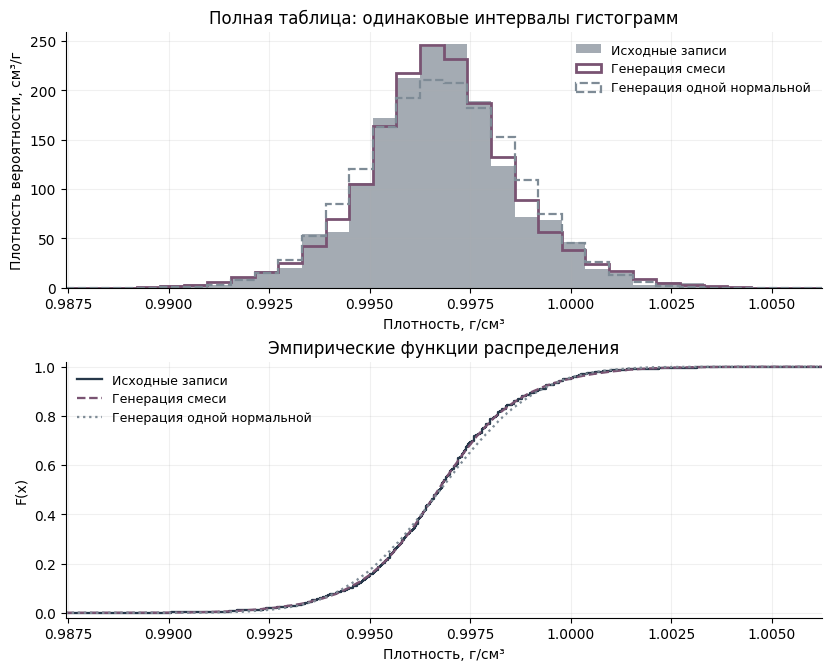

In [8]:
plot_full_density(density, draws)
plt.show()

**Рисунок 1. Сравнение распределений на полной таблице.** Обе панели используют одинаковую шкалу плотности по оси $x$ (г/см³). На верхней панели показана плотность вероятности в см³/г, на нижней — безразмерная функция распределения $F(x)$.

На полном наборе среднее плотности у смеси отличается примерно на
0.000005 г/см³, а доля значений выше порога — на 0.45 процентного пункта.
У смеси и одной нормальной наблюдаемые и сгенерированные минимум и максимум
не обязаны совпадать: нормальные компоненты продолжаются за границами
исходного диапазона, и сгенерированных чисел гораздо больше.
Квантили и расстояние между CDF дают более полезное сравнение, чем две крайние точки.

<a id="controls"></a>

### 4.3 Контроль по пяти блокам первого спринта

Повторяем то же разбиение, при котором полностью совпадающие строки находятся
в одном блоке. Каждый раз оцениваем параметры на четырёх блоках, генерируем
50 000 чисел и сравниваем с пятым блоком, который не участвовал в этой подгонке.
Семейство смеси уже было выбрано по этому набору, поэтому результаты отражают
внутреннюю проверку. Для независимой оценки нужны новые измерения.

Среднее, хвостовые квантили и расстояние Вассерштейна $W_1$ сравниваем на
шкале стандартного отклонения **обучающей части**. $W_1$ — площадь между CDF,
а $d$ из предыдущей проверки — наибольший вертикальный разрыв. Для стандартного
отклонения берём относительную ошибку по контрольному блоку. Для события
$D>0.997$ используем абсолютную разницу долей. Учебные допуски заданы
в протоколе заранее; это критерии близости, а не пять статистических тестов.

**Ограничение интерпретации.** Семейство смеси было выбрано в первом спринте по этому же набору и тем же пяти блокам. Поэтому блоковая проверка здесь показывает внутреннюю переносимость подгонки на отложенный блок при повторной оценке параметров, но не является полностью независимой внешней валидацией выбранного семейства. Для внешней валидации нужны новые измерения, не участвовавшие ни в выборе семейства, ни в оценке параметров.

[↑ К содержанию](#start)


In [9]:
blocks, block_scores, examples = evaluate_blocks(wine)
block_sizes = pd.Series(blocks + 1).value_counts().sort_index().rename("Строк")
display(block_sizes.rename_axis("Блок").to_frame())

averages = block_overview(block_scores)
display(averages.T.round(6))

mixture_scores = block_scores.loc[block_scores["Метод"] == "mixture"]
tolerances = tolerance_table(mixture_scores)
display(tolerances.round(6))

,Строк
Блок,
1,320
2,320
3,320
4,320
5,319


Модель,Смесь двух нормальных,Одна нормальная,Эмпирическая инверсия
Ошибка среднего / σ обучения,0.110089,0.110767,0.114431
Отн. ошибка ст. отклонения,0.047345,0.045342,0.048404
W₁ / σ обучения,0.127483,0.134136,0.133237
Макс. ошибка Q05 и Q95 / σ обучения,0.203371,0.167977,0.184343
Ошибка P(D > 0.997),0.036004,0.041364,0.035280
Макс. разница CDF генерации,0.070600,0.082930,0.070369
Макс. разница CDF модели,0.071708,0.083254,0.070329


,Показатель,Допуск,Макс. ошибка,Блок с макс. ошибкой,В допуске,Всего блоков
0,Ошибка среднего / σ обучения,0.15,0.143853,5,5,5
1,Отн. ошибка ст. отклонения,0.10,0.093873,2,5,5
2,W₁ / σ обучения,0.15,0.148583,5,5,5
3,Макс. ошибка Q05 и Q95 / σ обучения,0.35,0.356627,4,4,5
4,Ошибка P(D > 0.997),0.05,0.058654,5,4,5


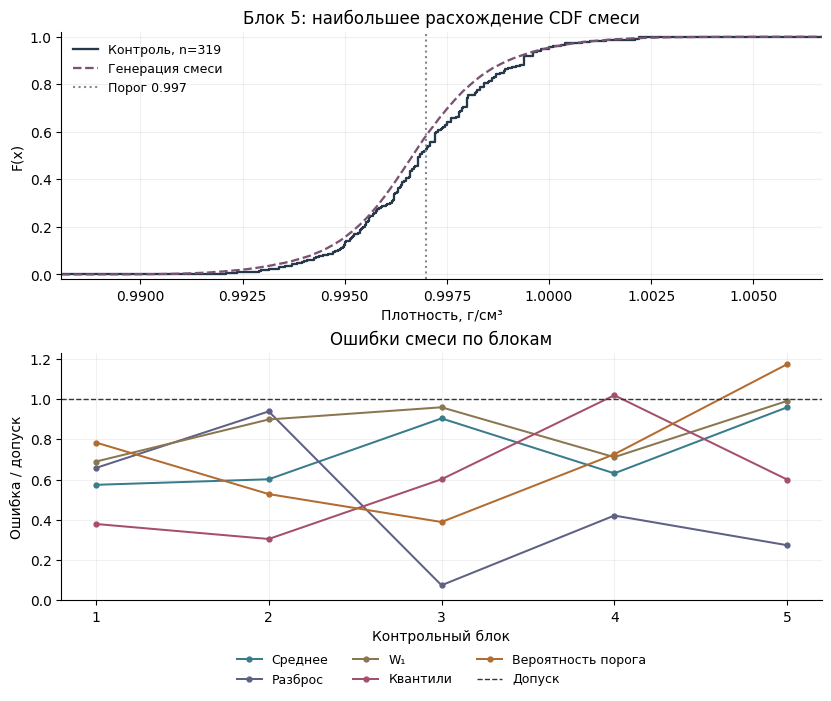

In [10]:
plot_block_check(mixture_scores, examples)
plt.show()

**Рисунок 2. Внутренняя проверка смеси.** Верхняя панель сохраняет шкалу плотности в г/см³; нижняя показывает безразмерное отношение «ошибка / допуск», поэтому единица соответствует границе допуска.

Верхний график показывает блок с наибольшим разрывом между CDF контроля и
генерации смеси. На нижнем графике линия 1 означает границу допуска. У смеси
за неё вышли две точки: ошибка хвостового квантиля на блоке 4 и ошибка доли
выше порога на блоке 5.

In [11]:
rows = []
for b in (4, 5):
    actual, simulated = examples[b]
    for name, values in [("Контроль", actual), ("Генерация смеси", simulated)]:
        low, high = np.quantile(values, [.05, .95])
        rows.append({
            "Блок": b, "Ряд": name, "Q05, г/см³": low, "Q95, г/см³": high,
            "P(D > 0.997), %": 100 * np.mean(values > EVENT_THRESHOLD),
        })
detail = pd.DataFrame(rows)
display(detail.round(6))

,Блок,Ряд,"Q05, г/см³","Q95, г/см³","P(D > 0.997), %"
0,4,Контроль,0.993219,0.999410,39.375000
1,4,Генерация смеси,0.993732,1.000087,43.004000
2,5,Контроль,0.993949,1.000000,47.335423
3,5,Генерация смеси,0.993551,0.999903,41.470000


<a id="criterion-status"></a>

### 4.4 Статус проверок второго спринта

| Проверка | Результат | Что именно подтверждает |
|---|---:|---|
| Проверки реализации генераторов | 7 из 7 | Корректность базовых операций, граничных случаев и воспроизводимости |
| DKW для трёх генераторов | 3 из 3 | Сгенерированная ECDF близка к заданному генератору закону при выбранных параметрах |
| Контроль смеси по пяти блокам | 23 из 25 | Большинство метрик близки к отложенным блокам; два допуска не выполнены |
| Независимая внешняя проверка | Не выполнена | В проекте нет новых измерений, не использованных при выборе модели |

**Не следует смешивать эти проверки.** Успешный DKW-тест отвечает на вопрос, правильно ли программа генерирует значения из заданного закона. Проверка по блокам отвечает на другой вопрос — насколько сам закон приближает реальные данные. Первая прошла, вторая прошла не полностью.

[↑ К содержанию](#start)


<a id="resume"></a>

## 5. Выводы

1. **Генератор воспроизводит заданную смесь.** Автотесты пройдены.
   Расхождение между CDF генерации и формулой смеси — 0.00310 при границе
   0.00872. Веса компонент в симуляции близки к оценённым весам.
2. **Смесь лучше одной нормальной по форме.** На пяти контрольных блоках
   средний максимальный разрыв между CDF генерации и CDF наблюдений составил
   0.0706 вместо 0.0829. Средняя ошибка $W_1/\sigma$ тоже уменьшилась,
   с 0.1341 до 0.1275. Эмпирическая инверсия дала близкий разрыв 0.0704,
   а одна нормальная дала меньшую среднюю ошибку хвостовых квантилей.
   Поэтому преимущество смеси зависит от того, что сравниваем.
3. **Совпадение не полное.** В допуске 23 из 25 сравнений. По среднему,
   стандартному отклонению и $W_1$ прошли все блоки. На блоке 4 ошибка
   $Q_{0.95}$ достигла 0.357 стандартного отклонения обучения
   при допуске 0.35. На блоке 5 доля значений с $D>0.997$ равна 47.34%
   в контроле и 41.47% в генерации: разница 5.87 процентного пункта
   при допуске 5.

Смесь подходит как гладкое приближение для моделирования плотности из этого
набора. Если нужна доля выше конкретного порога в самой таблице, её лучше
посчитать по записям. При переносе на новые вина сначала стоит проверить
модель на новых измерениях.

### 5.1 Что выполнено и что осталось ограничением

- Реализация трёх генераторов проверена отдельными тестами; все 7 проверок кода и все 3 сравнения с границей ДКВ пройдены.
- Сходство генерации смеси с контрольными блоками оценивается по пяти метрикам для каждого из пяти блоков. Внутренние допуски выполнены в 23 случаях из 25.
- Два отклонения не скрываются: ошибка Q95 на блоке 4 немного превышает допуск (0.3566 при 0.35), а ошибка доли `D > 0.997` на блоке 5 составляет 0.0587 при допуске 0.05. Следовательно, смесь не проходит все внутренние критерии близости на каждом блоке.
- DKW проверяет соответствие сгенерированных значений заданному закону при фиксированных параметрах. Он не доказывает, что сама смесь идеально описывает реальные измерения.
- Эмпирическая инверсия закономерно лучше воспроизводит наблюдавшиеся частоты на исходной таблице, но не создаёт гладкую параметрическую модель и возвращает только значения, уже встречавшиеся в данных.

[↑ К содержанию](#start)


<a id="example"></a>

## 6. Пример использования

Чтобы получить новую серию из подобранной смеси, меняем seed и задаём
нужное число наблюдений.

[↑ К содержанию](#start)


In [12]:
example_density = pd.DataFrame({
    "Плотность, г/см³": sample_density(fitted, "mixture", 10, SEED + 100)
})
display(example_density.round(6))

,"Плотность, г/см³"
0,0.996440
1,0.997236
2,0.995996
3,0.999771
4,0.998413
5,0.998146
6,0.996477
7,0.998637
8,0.993410
9,0.995884


<a id="reference"></a>

## 7. Справочные материалы

Первая версия второго спринта использовала полярный генератор для одной
нормальной модели и сравнивала его с эмпирической инверсией. После исправления
первого спринта добавили композицию для двух нормальных компонент и повторили
проверку на тех же пяти блоках, на которых оценивали модели плотности.
Предыдущие два генератора остались в сравнении. В архиве сохранены история Git,
протокол, исходные данные и полные таблицы результатов.

<a id="methods"></a>

### 7.1 Методы генерации

| Метод | Где применяется | Сильная сторона | Ограничение | Пример |
|---|---|---|---|---|
| Композиция [2, гл. II] | Смесь нескольких законов, в том числе непрерывных | Достаточно знать веса и уметь генерировать каждую компоненту | Плохо подобранные компоненты передают ошибку модели в генерацию | Выбрать компоненту по весам, затем сгенерировать плотность по её нормальному закону. |
| Полярный [2, гл. V] | Стандартный нормальный закон, генерация нормального шума | Два нормальных числа на принятую пару без вычисления синуса и косинуса | Пары вне круга отбрасываются | Получить $Z$ и перейти к $\mu+\sigma Z$. |
| Обратная функция [2, гл. II] | Дискретные и непрерывные законы с доступной обратной CDF | Вероятности берутся прямо из CDF | Обратную CDF не всегда легко вычислить | Найти интервал между накопленными частотами и взять соответствующую плотность. |
| Неймана [2, гл. II] | Плотности с подходящей верхней огибающей | Не нужно обращать CDF | При завышенной огибающей много отклонений | Взять $x,y$ равномерно из $[0,1]$; принять $x$ при $y\le x$, получим плотность $2x$. |
| Псевдонимов [3] | Конечный дискретный закон, многократная генерация | После подготовки таблицы выбор за постоянное число операций | Нужна отдельная таблица | Для вероятностей 0.2 и 0.8 выбрать одну из двух колонок поровну. В первой вернуть 1 с вероятностью 0.4, иначе 2; во второй всегда 2. |

<a id="cat-mark-table"></a>
<a id="criteria"></a>

### 7.2 Соответствие критериям КТвД

| Критерий | Реализация в документе | Статус |
|---|---|:---:|
| Индексы разделов | Основные разделы и подразделы имеют сквозную нумерацию 1–7 | Выполнено |
| Якорные ссылки | Содержание и карта разделов ведут к устойчивым HTML-якорям | Выполнено |
| Скрытие кода | Ячейки имеют тег `hide-input`; в HTML код скрыт в раскрываемых блоках | Выполнено |
| Масштабы и единицы | Плотность вина — г/см³; плотность вероятности — см³/г; $F(x)$ и «ошибка / допуск» безразмерны | Выполнено |
| Единая стилистика графиков | Одинаковые гарнитура, сетка, палитра и оформление легенд; связанные панели используют согласованные шкалы | Выполнено |
| Формулы в LaTeX | Обозначения $D$, $F_D(x)$, $W_1$, $Q_{0.95}$, параметры смеси и граница ДКВ набраны единообразно | Выполнено |
| Выводы | Содержат численные результаты, проверенные утверждения и ограничения интерпретации | Выполнено |

#### 7.2.1 Карта разделов

| Раздел | Ссылка | Содержание |
|---|---|---|
| 1 | [Постановка задачи](#description) | Данные, случайная величина и выбор полной таблицы |
| 2 | [Математическая модель](#math) | Композиция, полярный метод, эмпирическая инверсия |
| 3 | [Реализация](#code) | Подготовка модели и генерация |
| 4 | [Проверка](#tests) | Автотесты, сравнение с данными и контрольными блоками |
| 5 | [Выводы](#resume) | Результаты, допуски и ограничения |
| 6 | [Пример](#example) | Генерация новой серии значений |
| 7 | [Справочные материалы](#reference) | Методы, критерии и литература |
| 8 | [Дополнительное задание КТвД](#task2-start) | Белое вино: две случайные величины, EDA, зависимость, генератор и marimo |

<a id="literature"></a>

### 7.3 Литература

1. Cortez P., Cerdeira A., Almeida F., Matos T., Reis J. **Wine Quality**.
   UCI Machine Learning Repository, 2009.
   [DOI: 10.24432/C56S3T](https://doi.org/10.24432/C56S3T). Красный набор, CC BY 4.0.
2. Devroye L. **Non-Uniform Random Variate Generation**. Springer, 1986.
   [Книга на сайте автора](https://luc.devroye.org/rnbookindex.html) ·
   [DOI: 10.1007/978-1-4613-8643-8](https://doi.org/10.1007/978-1-4613-8643-8).
   Гл. II, § 2–4: инверсия, принятие–отклонение и смеси.
   Гл. V, § 4.4: полярная генерация нормальных чисел.
3. Vose M. D. **A Linear Algorithm for Generating Random Numbers With a Given Distribution**.
   IEEE Transactions on Software Engineering, 17(9), 972–975, 1991.
   [DOI: 10.1109/32.92917](https://doi.org/10.1109/32.92917).
4. Massart P. **The Tight Constant in the Dvoretzky–Kiefer–Wolfowitz Inequality**.
   The Annals of Probability, 18(3), 1269–1283, 1990.
   [DOI: 10.1214/aop/1176990746](https://doi.org/10.1214/aop/1176990746).
5. SciPy. [wasserstein_distance](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wasserstein_distance.html) —
   расстояние Вассерштейна для одномерных распределений.

### 7.4 Связь с исправленным первым спринтом

В первом спринте пропорциональная стратифицированная выборка из 310 строк используется для оценки средних характеристик всей таблицы. Во втором спринте генератор плотности подгоняется по полному набору из 1599 строк: его задача — воспроизвести распределение плотности всей таблицы, а не одной страты или подвыборки. Все строки и их кратности сохранены.

Проверка на пяти блоках остаётся внутренней, поскольку семейство модели было выбрано в первом спринте на том же наборе. По принятым в протоколе допускам смесь проходит 23 из 25 проверок, поэтому её нельзя объявлять полностью согласованной со всеми контрольными блоками. Для независимой валидации нужны новые данные.

[↑ К содержанию](#start)


<a id="task2-start"></a>

## 8. Дополнительное задание КТвД: две случайные величины в белом вине

В работе рассматриваются содержание алкоголя и плотность белого вина. Проверяем, как распределены эти величины, связаны ли они между собой и что изменится при раздельной генерации.

### Содержание раздела 8

- [8.1 Данные](#task2-data)
- [8.2 Случайные величины](#task2-rv)
- [8.3 Основные статистики](#task2-statistics)
- [8.4 EDA](#task2-eda)
- [8.5 Зависимость](#task2-dependence)
- [8.6 Проверка гипотезы](#task2-test)
- [8.7 Устойчивость вывода](#task2-robustness)
- [8.8 Генератор](#task2-generator)
- [8.9 Интерактивность](#task2-interactive)
- [8.10 Проверка генератора](#task2-validation)
- [8.11 Выводы](#task2-conclusions)
- [8.12 Выполненные критерии](#task2-criteria)

[↑ К общему содержанию](#start)


In [13]:
def _wine2_make_tools():
    from hashlib import sha256
    from pathlib import Path
    from types import SimpleNamespace
    import operator
    import io
    import gzip
    import base64
    import numpy as np
    import pandas as pd
    from scipy import stats
    import matplotlib.pyplot as plt

    # Оригинальный CSV UCI, gzip + Base85; SHA-256 проверяется при чтении.

    _wine2_csv = 'ABzY8000000u$W5YYr~SaUJ-ds}Qt+i^_K<z72RAgh*Kp5JQ`y2AbWwG9u22$m*8CuQ<Ap4R|!o?whyj%gRSQ&f_2d`ImqH;~)Ov_y6?EAAb4k|M!odfBb*{{HNdl^_M^WG5o84`sJ^G`Q@MFU)=xeFMs^kU;glKzyH%e{OiB{_uv0z|L1@C)1UwH%OC#uulGOy^I!h>$NNA0>7W1YFaPj|U;g~>_rJdX?O*@=SNZdgfBlC){y+b!Pxv4I?fyUafBzr<^83Ha-}C!F{nMZS<<Eb*|LK3;kJ^9ecjI&Y$ov14{>j&m{ZChIpZou%aedN{>q?(;|I7Pd%pdd9f7gHP|0(}pz5jcc0qc|Q|55V&Kh~<BBLDsVx9dl{hs+;oKV|NJ_vt^@9@0ML`m7-X+Wm+hdH+rI{#&m5Pxs%AANw!M@|=7>y2+sVspFGo*J1r0mX`dj>;79`4tn!;T^=OAH}wxD?H-egKIZ=I_haPm9QSkjez~7F)BC^Ha*vS-xL^DJbtx|yQ|A6TSs#>=585wO(><uls8Zy=78!KSPrm<u_dnnBm-46GgF2?VeyU8zRrXK0r$`@k|L}VX>K;?>*BkesA+syfQtm&fqwb$`PhpcW8MAgj_nzu`kLmKDB=aABQN4dr)t5_qRFeng`{nLGHtyGxH`@>B_rF{}vJU+0UpTT%_m%gLlBW%OL3@~drHQBAlfCCJ>71uM>GHR=J%92v{Ze(>&yo4OYL`W%laXcCtA2f554whW*O4|E_eZ+_pU%dV=_s-Q*8XAhGw&&^x*+7&*`xNiy61BweM6b}tP_8~VUdUJzq0H<aQ}e8Y1}KT=rrCx#}-DD)zn_TVb?cII)_;|)Sk`zPh8o*n9j1S!99a}@^qK&pEYc;@6VNWP`Ss{VehhEa!*FruP49CKG(RH`~A1}siXE}T=Kcn{j&-`vak0dJ3jAam}>StFaNxcjtjfD>84-ydGEcDYYUSnkJ&F*Wy<%T({FzNOMA%v$J+e|HJmGW#?;B2ItBYh?l-IYW&3`uGVRM=vgLI_WK4{$y&(&tge9wI-r5VI^Qe?Ru+Jk~MSEAumc6&U9F+Gzj{OPlN!pvL@fR)qnRdKfoVg*}18*p&OVQ6`$C$ofz7Nf+=WD6_u>0@K{+pV;oPNK3DBrJgU4Bw59?Fv&N)~?cqvAec_b#w!EqvF#8tySo*PYD#{TqHPo|yOl9J+VAEb?K8*8YS0BrCi$3fAkr+V@=9k=gi$S+_>RE?jzYHl4rwP4;@N%V&d&=Gu?i|7=&9?ZJC)_l7Dnd?|aMlxzk|{8Yn!SQ~QR*t6E2jhu9r_krGCkLxl6*-nBizjL3n`y6j!C#HlWP`AhkPt&6!jiRGQ7^R<72MwGq_i3RE<?2gL=&nnnRm?}-57MR4@u0jfo@zg8ADk_RiO+h)>1`T*)cq_Q)pbyPd@T;rSJFE!@ljJgShwG_x3S!4x=DsDT{#TyCslirOhmpq?|NCM_xtW2RWYdRR>7cqbKm#X71p~ROFF8(oId$7OIM|=i2JAP_1J98-XV5R*kg1vE=+?&FMB8L`?vT#Rd4|AJ;V<s6R~hw+()@wFV#;oxd7Y5<&hC0>~Euk?yq|<(P<~(9%8d~@8Bha{5#q4yhFHsuIYMBGALmuN~~zt)PA;X1v%M<ZbrYQ<hUw(CX(L+&Hf_2Zi?KZX(fbLHs$*o3gNFU{Cjfr&XE&3r{d?51X~Ru1*Uv2*KEi0{WbRStP5gf3mIkSF3z|dC26msjsviL#th5V?(_46*1yP3rTf3iht%JcJJv)&q;0d8bt_i=P5UIjcxuYUd)eZfuYc6gn|ntCjFB`rZHWuw!cB2mwDWEv@~=;p9b<dolH~|%Tz$n82#qf>fxXJ2$k+2gs<M=tt=Vj6S+}|P><8QCxC*0t3COyvbOtYp&$=Uuxwm5V+tgypWmlCS==TM6gtR?;;Qa@>%;8{ks<W{)S(1x;--}oCRVypFoN=axFn63GtK_;5)cY&vT0`3A_qHyjqOWM*>W+@u{*<|BpmL9z*!LZe;%$E~R(;TY#_nHuS%|e~y)TP<u1BWREsncC$Y)p%wr59fNy);}d2jru&)twerpFlXs472c4vo<#^4A@{<oj7eF98Nh#X_=s;q~PKx}1Hz?R;+>*P7&~wqEy&E(lKViQrvWxQOJgyyv^&0u8@N^5kr>)si7RBf|ArBvG-*H19DIL=B0@G@MO1k0hUznY-6Y>N?@GA!OO_mN}y6G1l#(DN-uv`kdO4rR)gq^5`hrBxDP<t6#XCAGUfxkaS_+&rbU&pLW;W^O9Qgs98=H$^HjFtStYX!D3kb>?^`zmeG*u$!R$}u3wfzCk(njW9$B`%R=XAx9;Q>b-!Y<lxVMpY$=<Zv3jsfNtXW)`C;ieS(>Gl_o~iTJ!s69D^{TAZ4B-2{kB(zRd-kr@*{Tfy53{tCl#$y=$N?}ib+l@!-mDl2<|oOm33P!2<ce28Y49sm3Rv*zY?niepN4zzMppSM9+4Q%5uNgXlg%@#O@tz3w|tCY^(%jXJ2pUMZdrAXX=yg<H*jx{RgxjvVPckge$KhKKRUn^ZZVUBs$ciuD*J|m?-YgqYvt`l$I|goj$!o?ZC9`cj?t}uh@MM_w2`P)i1Sk4!bszE{l|LGVisAS3^u%mJQKwTjZR(2Tdz1E{TzL!4DO+eNf1sfALd_-s!r0D)UJRYSx*L%Z=d&-<K0$YtF8o)NLny?wkQ-r^TcO_u#8Rx|IsjSv!i7lqU2>(|}4gwZ&7&tdm_gR{6byfB8|i<QA9Q;_~spqwjAtnw4qp(<<-Ji(S;RM3%^F<Z5hwQr=h4E^z6YHzh7lsQqSMgq3-0wsUCjUrV7n>#|a)O0P#X`SJC>@h%iW?)^J?PfLJPtN=c+@oaJ152{v^C?VtWL#SAUtr255BJVFbn<r1Kexxwl-%gz_@?tj+hTZ$(UJn*c>8NUnP?kAZIDqzfY6q)C9&<dS>*Ph9$&+7dHrcku{tZ@anH6s+>uhr8CY#3lE^W5c<u28A-sJjR_>zP7jAl0TgI2|^V_JPMjOpAQ6+3=kN4j_K)8Rh#QD)IfGs`TK@n~8&#O3(9&((d8#u_?{h>1rlYE{DugmU3{K>|4gQ>YduP^+_Y?B9XBtv(6KrO?rIB8FYkMFYpoa6oF9Rz1hUY{S#{V-P;DY~vaRr7&uj`v$Mh#tP;xMq0V4BD5?PTE72LvJ0~v|HYEf`$OOR*UGtapJn@9%PZ4JCY!|(O@G$(#jYi%#M8x#nERYcc1hm{SoYxD_9IU+%TlZ!lx&mS3q&rc72dETrtgvtWpDhTCvYFgJ2_9DOlD@u9x6%=wGRdayEeN#RBX5lEPTTc^M$)?Iy{j|%&nW%fk$lU?Q)Ke+6(vokG7r)C!VL1b=&N)wY|Tuf$KBEwNtF(ixcD3?;0L1at?Q?ZqL`?9Oe{$R!8+c>6K8ej<j14XfkQXZF<Lzy*+u5K4u@AI0SQIr>LTGtn-i?0ujqzkJf<3A=(4bZN(m)7eRJ#Uf738ax6{mEI-Yfoc(DZ(;0_gJDRV>qRAyi&w@CyF!SH>&SF41*d&>nyT%IKJp?Iy-f0BRG7H9}YA01@9b?OQT2{UHVXPM;iehBmktA!}t3T*I8u!iB{KnREv#>7q=KV4sl~~l7yJ2Qiml!QqJL(>r*VCarOWpHVsW{KdG>>(OebS@KyzhxMaY|TZRWk~3ZwA?!ZUr@TU%TuJt#4T|!@DXw+t77WE4r^0=h&XVrNb(VkwpXe`F7aLm$cHI^%w3~z1h-`gI@RVL_gZ=eFb4mLAgp102XGI%w4r`U%j0A5u23-Db6nOSgFQOT9lp`+}}S4VfyZ^k5HD?gKt??afW7PM~|~=dEb`pU|b<7LFda=+gq0J7OBkYFPcl1?X(CrCfC_I5EGp&InhxDmdz;R<l^3$gyyc5l@5*O_HBAEiwoENJ%0m*I==^O-&@e#C0erXx;E)>)MndRi~#o*<>hgoV8``_!&bwx4yb`#JJSyJ%FgJOQ9_q78=iqf-EblGM{A)>T`oVN<&YBShaG4w#t6fk(uHlDg{n)hxEAd|JC7Nu*xS5k_5%0vPvJx>R*7jpP~k~Zu3^!>gbGTvKwnqk{&&mH&K>fND^#v#%*}}!xQIg8w+lKyq0X;GtBUPw0D#7mQ{W_>Juvx}eWK#>qq29KIA}^bF+#sXM`_XYC`_gnI=;KcX4R9@S?MZg45+6^=53%&M+Fz%vs0{g;`v9m#(VYso=2#**gcAkNR&qFu`4CRI*$pd8TP^|@We)ZjJkJ72_NY>j7O4{Ar!!~Sk!I2f_t*7)Dl1R1=yF$IMX#PuyZUWzFxB`MPcnuO54jful{T+p--d*HtSY#*bDa_Y3D>}&{a8SD<b@J)E!amW62t4VN~Pk{Qbw}h}{%JEIZj~lQdB~VBCR*erme>YzJ;+%RaHJUZ2_N&6W_@*08#3(I2=0LTM%+Baf=-Xk;1MO-o(-{2x2bxgLYcI+EY>K{BdwV^r1;to_>Jn$4BXrL5nnhUCbSYLt17Tb}n}+ok?$x3&J;x~vZH?nyCu+oeuB_m)%_QQ)ZY?k%t1Z=oBrL)Ky^%Z}2s6}CqKdWRpEze%8CmV#Beu}k$Hj+}Bk-p`JzvEF*NN>7m_F@@}0{zTJTgJ-POhX8n#T3l)+gcMB=zDYcT)?RijQ_#nstWz{Eh*Uc)Ei#wb?@p_`SJp0eQoBPQ^>C>;DeU6UgfBK^h=u*e5$-}w^DMVqwt07OZx<9>wqsb!s97DL>7BDIHP14;(+d^p(ZHT;(aqS3ZfwdYzF=FL@Qqg!XceWRGts<A>s@czqB6r}SSDe8Ui(#eL3uxmF%vrZT4+oX-N#*pBB(Wfa)8ApPmkIWxEMfphxT5u7i5e^Nk#90cMr0Pk`)e<BP(~2+weYfh5G67e&z9gJ6}$|lrHSm^zJ8VNY$qm4weBVHF~q2f`X1)<01Rv8(H-oS1+>V{TS=tOT<zi$GJk6n?|PS19n+N*2eNyuhv1TcNHuyNW;hN%t+sHah)5K5?2m-ZH^<^rEZIyWzKQRdf5t5U%FTv-;s+=pmf?2fmxwS`{q&K|Ej5xx4;kWpxAvt$FdH>7i+gDWCrviE~@*f0@Ag9Rwu|RS@1W#S#m$#M&17;$L0*90MoGUw?p!Gb=!`Lsn=WR>!ESG{_792dmx_|={_oUbe2NaF#<S?mFIo*+P)f6xz8~H!wSI8^6e-^TFcxNv4^^WwCijk*u%VQvTvGViJL^vmS`&^!ZY!GT%6!Q{laPARqOIYU4d#SDcQocI;bu7+~tBpMp|%dm+6ps@3mAG@b8_lD<e4p!BbfIpS(nt-KUyNWR&It2D!2F)wxe1Oa^JeJ@L6Ndz2J~WuJ`Yu=&Z(?*Njg$nGi&Pyo3+JDd8A7{LGtOHyMSjtmC4+1eRaL0t#bw1mQ381(3YR0H*+n<0%-raK+Q&}wkv=Cx<RKy{1F_WW5LSujv?yb1WdqV#NC@MQ7QP&NgY6XNwIwVv|wLp5I)ve=px?;De`w7*kB9ey_-OB^L7|7K-?Jr{r<dr3W8rro_8RF+q|1?g-7U1PkYIq*bHPK&jTt<Q<Ft2d`*7n2?G-G~~{)PR#@tq9L>3una2lTmjeigDR$C}7uIjJXw4s+A$BK_!EyHeOb;Hm3&`TA0beJzDiZKXF<{8mb!O8z5(Oq@^L-S$^{vf=WhwtOKkkjA7o{Wy#@L#S(+2^#eO@2Mc-Y;McIE$y&gUH7qbw9ttTX{qOx<dfs+~(L3YG%xJq)M3NPV8jd!J%DRJmE3x*~(as<#VUz`PgOxHFX4BXn!}h}}aLaoX;{49V{;Nmz*FQ@km*GKGgTeTqaH@0L+cCp@Hc2zmuu#MM;q##Kv}s!l!0!MkR)Ar(L8w}LM2W`nZp&Iet38m0vXWziwNfj!WQ^LU;R?kl&Yt((L*c`sgzHhks+b8yN$^mLbeZ)rcz$Xq-Z$@1&jZhiaOD1rd*}rz6v_J9RWYDiAE@m83V*K!=vmi-rgbsANx)8hQLc=!<510%^wG}CMAV1D9QJwQm4Iv672lO-H0}2wcWk6IZ2-p=)1zqs)jb#0rdwNsJ5&O&X@8`M6af?JsH9krKY^5^J$GxE%t?&kBIv^dtULd=T1r={>E+qtHE~Qh0Z5PF!k+uRq2wK{6na8>#v@AI=>Qw063%6B>S*_9FZA(WeUQc>si8QIBxKi+S~$d74k$u47Oh8<mLZY5j9X1%bv>fw>>e;!@o<1sC&@@Kpo&PXvJE$cG2yh7VoJBi><wn562)Fw>aatkf~&qD_{&J*c4;6+v;!@tN{XB!nss;D*<5(K3|9Q*bg3u9Mv%&wz?lh@D_riK)gA}R0nDYZ*qxX-h<k3z;j?m&W;4LE7v&vf51zF!*PP>k@Rai>*QmW*BBM#66O%JRYJ_pIcN83W3Wd;;_U<ViS3q|9XOkWQzzUTCPti;a8C6Z-UQF=f5)p=a*WkEc?+0bzs%6l?Zn_-Hc#gqwRDU(Z5%BH#7^9%rS~WIK>B?fSAu?s$SDBC^N385WN*wV-pw;AL*o4?LBvOJHM3yMM&T7O9Z9f{zTGAT}K8jLkt>h&sv*ZFz@-HO?GnCjh4ZGp9<N`I^)!N0d6|N_7u?)v1aHF++0_88uz@J|pa90fK-siM?H;gd~L1@eXinpm_0u%_yM3x(@pyc@c%G+9TzQ?C>Zc;y4k7eIc9M*|Ok$W^b;H^1$Qtz#S2DtFIt(jd44`#NCEyG6T5I|CysX%RQ7K8!<^tn*@LaejP9O(GUuab&rPkOA3x4-K39D3_bAp$mRqa;S)iFD@kexz3`h2a`V$(fl<mrX^WJ(}%}hsDN_7UTTsvnJ=TIhw57hHH8b?__Tik~{7XyB9l-bm|D)XLlznQFciQsn|k{MHK<`br37ntktp>!j}>YU(RK8zI_oM?F_OHgIL_^9YVVbaLy>QJ%tRoBXDdC98pvPI83*GY3GsVfSHbdvBZt`q<!^%K+o*Ro2#P*eI}INXuX!p^%R`?QVsrMeI5Hhjcf4!DHby-GO=+9&e!kfV@g0NrBKI@Nqzc}A8h!c(YP^s+Hb%qD(WaLEI`u9_IOswB$88rZ1FGLBLUYT6^nWYDh(hl1?v)yz&v%XU^N(3@$yx&2Ko*)XUJL-8}&QYF-?>@(e|uycVzatnZ#afP4s*yyd-AW#o+76mG{0!7lhZr=%~hdPa8wBBoUU#7mlz!X!MQR4g{nIizPJNGk|2B4MoM2a0ezK`~?jG*-R}VR1C0jJy*KrIQvyBME9_wl2b7w2GXiE8_PafyqW=maS_zSkTVf@zbl7!$~uX5;3h5Pv2;eIiW|2;)`P!MQFtC6qE~|T_s(^UzXPZgtul;LQLKiSt&f&80-ga^a&$~yK5AMdw_D$K!fuNB4!yA`25T<kcvc3W!x|Zz&^SpmACnB2`B`rVg-|ZA?Kcb=$%+%6$Fw$(AYyRrT8b?ZMWd2Y2s2Od6yDbLXpmy%wdHqpjr<J@X%&-0YSVn+4hXpF4Kgx7?cRTraS0@jbKHUBHWI43#+a0L&hTAGO4xWm-P84t>_oN_{}pnt>RcNM(^=TgETT`rBc?$3sE51@k7G$)l|i+%Twfj!l4v$aLueL}j2&IHX*t7UFnJ4Lmsy0{NC>+yv?z2??FUhX&hag#LXonoTlGN3wqe<nZraa$L%q`0#cuetV*35(0Lv*}W$gfu=5XtJyI3xp<?Zuy)>spNRYvBUWnD}IFH4Y~Sd5c|>eZ;A=#*U*OD}k9GbOeN5W?Z4waWpd0O7N*`GDd{eMjDp%=BGopyb)$g`@FX#<Y7R`xD-7gi2EP1*q6+FlHLQRJJ3wvAj6Rwmhm&iXh0KZRC@f__r^K&SM!Rh5cy-(i9@TNnmh!y&#-x$$%;g5k>n*7EV;hrB82zK}5z5=g-`KWwzpWB_XAEO%aI$O@Q9wM%+8R2KgCqY4xaua^B=Ua1Y*?90MiJLa8~`1sku%n4(h$gF7Lj7j!Gj=!rGV&Stb0Hndx6gBCxPR3x=RG5nsQHq$P?$*iX!+Q1H2SMDNJG6uuC=}d8yl12|oS_hDEXn2Kyepl2`AoJLlA{jZBW%-jfQ!A+bTr0rRnb|~Xza82%(x9{^)Y0XvXR;ydl+2gr^*dR!P!?Jtp9CW{^Yd=dTX7MdLiEM(Eb6QGdp+lDLtKOnZ2g7oZP*%EYb)^2h|ixaIPd6XPspBg+o%UHID@QOK&f*)Vxm@I@7l%bZ<a&^f!>juEr<$9MCELh6|@7v)T#>=A>cB%ZcPr97ZeLtSVoE6|Lk!A2vnH>?t=34yCpjukhA|KXeEX*M^+@wjsZ=H9_8YMD2aGhj+%=(QBm+oESsct{HlHGXOgTZ+4EitdOhgp{H7Z4G%iJS|Bn@O2aDLyMs;9jM!~NNWfw^Mws6RfD5mh;bH*c(h>7(GaKwbzO&d~SJJ}o*sk=k>gY$jL?*M@_sRX;>Q`SytE;8!4$74{BgVO)Mg93d=I$J2{h&E1m!2-?IOUXh%?N>!ci7N?M9#x-WFpUkf`Rhf|<OZD~rn));36~2&O^4--E;%JAYXNHiYs$;t{(_+<n^+DP;nevX1?m;W2U-J=4kf!$1V|T>4v$>CX{&HTK&JLhvpX^^HrWTt4B0>fL@k?;fU?Ley~&wZ?{LcGLiRrZw%?IyB?5{dwWXm8+6j3AL))NHRU$gDxe&;Dss&3tRzaX&RDjk}SF;Ra$JX=xEJhu->Rd7bKgL_Tqu=Z3dDa0e=$;ZlLm`)Szh;RnB@d=4R&_`+cqgLZ!0n4$g|M0l#zNM`o5T5}B2G;ibQ7?eOg<%JtjZdcBs%`P%A;r_8rRb=eN=)6$~LAi9hoeObT_r&jsRMVT@}^s=5W7>^ax0gogTGN`fDX{aDl!+H#Q-ulDwq^BrP?oz0&{nAfgmR#*#JA%JPuhC3S|o1bb2mRMt}v6-&tU4Kg5uBp?X>IfC5eLDNb8090B|r9reZY8`!>rJiZ2nAA6FXU^PFRYG^b4r_@mFcp$Bqw8fq>g8N?2oQZY?<FYjAvKj{rJxN{tcG^iayc!#7A6mPi5`=yRV~V>LP)ScxC=F<6wW3kI7#I`^X({@RvG|d_x`>UkZf7Kd|^!<1X9vozTSu`s?C+^TzP5cpaZYBR&yPK6okcwcC@oI#0mvY+X+A0`KZIs8oCP}vl|8Xlyk$j-|%lQu#N74Dsq=Xg4iy9N`+E8xJFg#nPQ9`Og^RtCft2Lb02>-xv(UN(JN+f|M|Zs;97TDGSRpl8;uB*(Q-OyrUVODpWd<L1SG<pcdcUo_rkNe;quU~8WMx*oD>T7qdOJ#XqHtR1PCx)2M?H^%xE}SI$8-3EWxs%9#X-b&6Q;Fy(uFUIn3=gET?)t<Hm|48zAvU_OifIuM$C=0Xi0BkTl7;8j4*I+E@qXF+Zz|QeSQlGJ9(dQ}YrJMFdBYFJ#z;ihQa$U)=ix9JJX+u1T4lz}Gz*rrd3*1g932TF%}Q&6)C-heDP&<*UkkTPUYODka<i{lMu~Mz&R%042)tQhTtulG%5!*by>HzHS}NzBPQXVjIs`gXd$AlOWOh5Wwj;jRYDbPCRC0=OZ7w@iOhW3|CO9F7?o<+W~0?S;i}W*>#ZE?)AH{3I!La(L&}`pAXQZDU6u})jlR%Y{R8tYYQUCT<s(sXpv{SY(woDr=NO#d^=;EwxDd%aD7TH>l#hD<I`?hSazT!OGBO5vl6t=toD-CXTuJ#3qXxt&(fMn@~|hkW04?jR|c*JL%k1RiId5gWhKHxg}hL)b@CLmnx8kibR%xr#u)*b6OiCedT^#xf45+}I`aMU1zYhj>v<H*J&c61PmKV2)FkI<7=8PCp?e|yP-f`OuYeUsK?9$kSJdekVG1&?KGj-XDFOuleWGU6lO`)Rg`YQbO*BY1EFUwTW76_LEuswsM?<v?L0xzi>ayA&)QR4Wva?WDx*dIY1W9aBb#1_mvhE=c4)V8zVSxxL^QhPp0HeEoENkAD6?w=P@ye2(A<g^lIYIv|lysBSsY^^9c!Y803Q0B75(hUoP%ZmJl@`a&W@}I(995!kdRii^Lw}GkgNm&?K30)T)O1$Cn#}h@*<g8)gUh<b(2a<~6fmvX3q$^^^n(xfWBfRBH=_<9@i_e<u8AN!g@VoLbYqHf-0;vg^^OM(K7fke!gN7ft-6|c5Zi?93VNyYBj97=6U+%q`W-C_5@kYaHrLoOff+=SQCWd{F(^o$5i(}nEQ9x5=_zA$GTb<Ky9AO=Fi9_{tB`7%9sC6Dq&<q5fy?b(Dysa=c~1rOl+9O>O!RufblcIjE!OM<2=kMJh|E<XlVOyV6u1el8!ahy_(i1$X)6${RNj;~&CWh6f;a81)Jm*`Ped}X83XN|>luAVs&}mi92VK^0Ak{7k(ys|-NDL2|L{S^_t1atqQ+~&wSoxLQY(o#(ewwb>U;m~>54hjmB1qDKXs6*w;IzeHHOUlKt)o`juGW}-;aColHFAVN)QygKWlew&XPhg{QyRbD~FbZn=~<?NhJ1GkhzTJIK@uRg?4_r$aHCiL30D$bhu|tcLCNW%0FNVF;5nCx<N_fLJJkRwQRIj4<+OZ^{t1bopAO*am$YUX{>>SD1;Y?IA{?=Cc0DEaRB*nqo^T+O_Zuij@BS_N-Gyk_NW#VML_LjQd!vrTGDV}5@5S_7s%xdP0#G6fCpIFEr}wUHOB;JIV^6x{8Ru@wB*eaWv;{}JG`8+sa824^An5Ids!7^QbxE{v8uwngKTCN(dFozyh4auNde*U#ml{U%)1|?+K95qhX<vb^O#wboo-p^O`{a+q>h<#=xhm8@fcD(744ze+8maIrtk`l;$nekWm!=S3#x1MC95IjNV88U2teRUREIA=DpE#-;QT=O1@w>FsF-ykZgqc86t;(RK=YtaiNgJ?iPl}P(BW3dR>Jn}I)yFBrA>N{xP*m5qc9m=g+O~CFlPVV>_NIZa<Lll28WsYLNuhXpqovmQdyV1AKX7>JajoUSZYWKx*_S<z*&UJ`%jVznS)TW)j1Fdi}GL#-YYuj=#QWm!`MEENLR9Px>rkC+*hF2gnZ~YC1|d8s(7@}O2}ksiB#Ws=prbL#|@B5W#-FbS9NUHV06|=@y+fjlc~WafqFW`KeSjl4t9bhEflO?%&7<)h3VM<5+z51hqc?G^I8twmF)19f>P2kYWzo|h8x80xS3><y@PaJXl00MEjg%}e?Rf;SKhH7EKxG~R*8LIeNy2Be!ViZh>|91$QcbS*FLLkT)0I?@ojHzT21xOp|UoD;S!yR-KQzLgn(!+O=1@AsqLs&KaB0lqjzSrQGzw4JZijrRIC<$h6OMhSO9U#g;D2kXfHRWR;r*<97CmbQ-^e}qYs-PN|s#=p2A<1NYD|eNg#e}8~dT8+UDV*1nUThC*SYQP;M5uPd)5W@?kc-6_;Eb$CvDKhrdP7jY1c$jklaG14p`0K9C!=osM%73>znBC+u48&w<z_qlP)X*r4TO*doa5K?WO#$jjayu9?=!wenu-n;%68d~tfPg6d+>$g}J+5gMw>X3N{H29sEWQNhS|SosDwj3~yPDylt~-#pVfr^M_+t1fA&zh4i}QIhS0VPC|3OFB#FK>jgj;NbP2|A9?5J5eDv@>D4YZ#Q>;Im&j3^@&{%zIYj4`e?PF-y1w)zZ?}y9ZjU9qm{R%ry8nORFb`GR|a6?!>s=9%fqe%eb^-IWq2{UqllVg+irQGQhtR3U+U?>S81`Z>xj#VssRw12=JHVOco~iT7yK;F@t(PLJN91XqRUN*-altPs{Q5jrsQFTu!D?ZrvzHfqR?b512wDh`?-~Ok!XaqUg+kWO+i%()Em^uHPEvP)!q@Jnejo^CnY{-l#ts(pgbO&?ntF!4AF+ptwquy!L>zJMn9eDFTSF(oGjV9+PsUI#V$#YKQ_zjgrOg5tz%@^Hd5h+1qCWN(XLPk_ew?5zyU<d*mbr>{%l+F-MolLgKfetS>K%z{GGvXN;gJg~60r3s{<)S_g76&9qu~b(={MrN~}6%=UspbI|3PqrLN&W2`Pr`#qqZw{YPKz1WE<CvX=4vFRS;jk&A>95TuqGkP9;Gw5^_gpY%!m&u#Hs<l*kgt1fX<@+Z6`5F7{<?OR305C+{uOYneOtrNVRgR#?It&#~(ha6Qk8*ci3{QjMI-fQ`kO)c<34pNL8U6)8Sfd_%QzT=JU>SVlOzwPvS4?1Dt>7<SVBBherpeZ-7|cLaHOOH8<}h`9r3*Fc9O42poJ&=qB0rwjn>!JRU{G{ZG8U<u*|3FGs4Lb3p)8S^?Tsf-3oI7WRp@4S-6e<JW%uxxP3{($sc|Af;B#0BmRV3WSF2}?a)e<D$EGZSK~_|kAQjN!L(Zs4Wmt~%%c~raCwD%#fX@KbSfISwQ42<y0>Tc#(rz!}RvlC{hi$sjdhA0@uLBl2%Etd0!<rv7xl_Nv+;c4q4CtK3QhqxmT;Wr(@dT(^5DPS#GwIzxtbqcpxUJ+x`ILyk-35phhFDUuk;wxQR-u=lTMfG9lQyJ{JzkkG>hal_h-AmE4am_XXe%UIsc8c_JnI1NryexaQx=+HsX%w;Q;wkGlYtz{w0moN^Z*}kQ9b+=rBRS;QT+#~h-3$Z8Z>@Dgg$|rvD7ST2A#y}9*QsDZTMYs|GQzwh1S1jXi${q_41<u@3qvX<j@lKWS%j|kF2!8>Vwu&ZDCw|*2s?2dGm^PNmi6PN{EUL6r=)1&iy^k++a>HHa(Qa9j?tY*wdt$Q0~x_Zwk-0$Yjua-D0#JO+o~yIDXw7Pt?L}Ltp1a(pOeVc4+6ff1@{=Yvy<#k0qQb!F~zxw}z|blv?nnLgZv!{o$?Dk5&clNRvC&f*W)lTXRqXL{%urDi<ph)b@0k(M3W)ShXG3LINXk3BsTq4|<!T=3q}cUXL0tMs;@$NHw^&OM`r!nn-0u<uL7WF6!2a#T{}HiMFnetv^mow+36#nAyj4cW1B6(pmG>Za=NU0kb<5q0R&IrRH)88J4#hxBtmSe-=@YxJnQmBFwW>`W5h-=F4LE0pEXR6W?g9r1)B}bwGwu%I9Fmrfbm%?iG7iSzB%ruCv?RCuXkrGM9-!&KUMD)!G~dJwEK~x`|FE8?`?wsYw5Tj}1jpm7-1<l!zWFhF<MV)Qc;Zx}36ixQ{Uu<LZ<ksreW)9S>tz`Y@`pMG>A<hzw#5v)3sqMQQg7v(1I-`g9mzHFx4fcw2e6NYp-E?>QG>N*!aIR)A4%L@CQedSn(JnO?ksV?nAkHR!=dCu37}mZaW|a&;(2Qr?ptM-`$D7k5=Pu;-vI^6mhvQ+d5RN`Rls`UaV5@(bk=bvBf|Y)nl&Agosm)Rw%5a-ICcOqI_>*B<xlPC*GR1!c#SgH<psZW_RpJxbRHx$>HES#|fLH!}<KN|GK5P;G_sIaRaUc1Tu|^1fH$zPjf_-{*kXCPVI3wuJZ6fgU8AC_Ov;a0F420;pc~;AiR$N6~Sn(RBoY8W{i~l2W5g{tB)_#NnfXuZq+LA7SLfTrOC6RCb|?7Qd~!LeP3c`~KCSAj(o!umIe2Hh{)j6j{Ac&mxWxQIE9lp=aC3FFT76&g#XmnjR&O#T>sed8rxjB@~+E$VdSw&`~hYs2M@2A9nFo%j`|9*sctv#dZo1fB%LxaEOVt6*ylgU3jM_yErDzO3XSi6EfDt_T$P<6tH=R5DqFUTPe_D=-Ob?*0Q6<R<KKUuE5Sia?BZlnN5*3L4saU2;=?2mepQ`ywV!zxf8EQvVdA>*(IDPz6Mibsuoe_7a9P?@6@cBVGDk}N1a3{{WE+n3oTN>!*$lbnM2nPr8^fR_Qv)LkM@2T#{(ExRCQs5sV}bFPVOPwfO=j_Xp9UnyD_47C|eYSEL=|#Vi@vd@nMl&L@-kY>F)kAyKev`#6}B%3UuHMvZ+mb|55<|)Sv}>Id(hw+O-yW^=!`L$HQbKx%}9KQ5u@bK~OCr+wAU_?$Aoaj?%n31tImsbvucl^mfruCqdUcr|6rKrE(Ea?9+L+-~OtFO+vxc`$LH~A4?=9QN5x&`#NGwh57oiHJfBmtpI-F+>G(CTIlqLiLr|O=7-9UYrPd!7qO1@U`@)Xn~bpxkl+EQh!X;8#<|121JF*|yV<VNtcN<(@_GxM6f0#N8=j^1Jr#zqYIODsav{;n#F$)Jg)T?vs=M=>g~Thc+9n}%g0c!OeWZqach{1wVIl?hY)XjGe)C!N?|ehl11volPN3*+VcFb6hS3s?s`sxe4tE?*nO&z`$TxFt;jkT0T3Aj=3y6WxtM%wZ_XE1mZowlya3e6(8ku9+&7T@e^9ePM#z`M?URH9Bf1?1_m;_5F0IF8a3VX91Ucm`q24>Ff+*~p>-JA_<Oo?L*jSeId#|#_uZv8n~Z$c$BS|88$91--JCD*fJg)n|{wfJh!UR1Pd(Z${P@rI+eKxFc^Zo}6ev0vs&vSX`G<X2O}tqjy+J5~8=4gx{VVWI>fbv^iWi8rgA8SVQ1o^!jZ1#^*$0^`BV8TCJ4j>Q2*BP&v$x&xPnE^FHxFkzIir8q}a*B#~SUJaTQ-c3Y&Hc3fyaPLLi4@-zF+cv0t|7ork<vN^Y@ll<a2aZudYOVkAAQwd=&(S*EmKy1js8M`p`Ka3H!cojLxq6|D!Qwq1xO8y};B3*!xavbstxYiErc0K&^}A#`l%Grt)LRE7j*w4D<ym3dTLZ;_-lCeMcb|E*z;R~z!NMNH)JF2KS{|`o^#?RAgv{D>CsKBNG+8^-GPovQ9MFb$zFy%z1UajsUtq6j4y9HTwiP&ZCW7u_|EWLf-L&h?2`8A#&!t2J(oEDZDm>6ftbHXXN?J=TjLD1e^%sMJc}0Sq?1++ig3_yQk}-bfPYRt(le#Q|R$MtGZe<bk<q4m>@ioa*(;}sv7PV5IwI6nfUp;7e^TRD34FEUbkU{+kvm0!Y9w_#jCK)a37bN~hQXy86H;@Vr=q4!YY-KVP1<I$8L<F2fp;}kTR}#~N?R2MpeVSl`(HHjOZJ-m#>i`N<&MgYSO}GwD_oB0qh$bzA{}PZLffYngzwVxEhKVtLdZ)T_sKzUiWFZyxmM&$Z(Yn)Ol-*ZDE>v%(ySE(jFd|vCorccIVnM1_##be@;ks8wDruG>xTu}c`nwqkqJ`c)(Mn~$f>c);F#mCxjJ!_2JrfSSpitLH?}DT~OLXF%;MP&O_JG@IQNBFm%;*e&@OnK=J~Fc9<dttfG%(H=Z`2)h4Mruw0<?3d)F97{aD5~Bkb~5#c^P^IyKBg+r%s-wVPdGWTstGjb(+knIbxP;&a(3{{m5AEZiVUF65=c%crQs!zms>yW?<fCnCFRMI85qETWJ}@@9y}%oGId=+8PE#=u~baMfLlad;1*rtXwrEOIAOvozb}u)rfb;X1Wo(L?7l`YOW1iQiAs9sMh-7Nm~D|X;`7htY_jia#S8d_euP82pMzT8TaIrQQFUV@v%k#>kM{jBzGB}isg=VJ|7NJp1>(A!@@IB!YaP}^2v3fZL+#vSjq6x+TRTFDGM2<J0hWNdhf#(1zS52J1)e=VKfZhlI)kmGQc-Y$yMC1b~K$$@!@i^%gDUJT~J4l9M;Md?-=bR)CAOO95obFf@QTL{7mdI$zf4CN&eI2FG&Z5QqU$SngoHKv@_@}_V+)nv9Uo6`}va1`$-Ki89@E+rc#t64BzV6g8EMqrO2N>tOfNEFv@n}+w|XZJt%n|vl>UlJJ<i)K}r^<k`HdJs@8MM8rLoGG^bqsZ^s4lOKB1QRM<W!u6EL@BWZ~r^@DM*&E-DPfVVavxxXG_fsogxAga1|2BOL8Z6&*omy?BEZa0g?EKpW7NG+tlyq-d+V0y7m732bYh$_BEQT6LtpQvhSl?r~;S!x;99JV&E6OY<aL+il?tvX(^(64AU%UMJA)V!d$qtHY!?H~fc#Gc+ith)VXK3n-QDO}`1m-q8AsbW<pv+6x+@k7rZ%rwF^o87<-a#Y=&F-B%Q=~_pfa#WhvB!TX+m){RFFGn*0s*2SiIo<`3pqB{E)$BOgq^Qld<1TtZ(y<3qFAXUxv++-N&ALK7x2n)|mmcoX*VfenH=e1I^2)js%1-u}az4gk;|hjv{+M=D(+VYo)xbno($vpn4Waz2hQ&AQ@9+-GTuGv&Q9i_(k1o~!8Aa%Ix*@%>n2ImLO?M&4PtAIu`-|W|S5SLO^y7t5Wo-~%7+Pc4O$3AMHLCkm2hhIUx(>Kc=9>_M>O|$7Las<+7_J8#p<p6kZwttPF=j(k?EMm14#gJG2BpMCK;vdhkM?B7df1ht>HH=H@B_P#T9bvc5%*UX9M%fLg3(K0c@9W`!T!^7I#<6xXg7|!erA~&$jW`ui_S(&15JEm2G*~8$>oSfO70;fKX7J`N4}nm=@M4ek$yYhgx<X;wv&dyHL%dSBijfloFw`;+-|Q11qs8v$iXPWG0Y{T_>QP{VPjnNnLWcCF5qqj_dbYY52|pK_^5*Sfi@$RBS3nKGJ$)_Jp_m7rZ;<(@%Zze15hB4m{p}8am7HIz1UZ6&X;t!or$Fz&O|WpR%}aw;GvgU3LyCu<YC)9P9c_uRyY?5VLGZ5hNXYDF~5AbepruyW4>?N5gH-oaAAqrw%bOCv}rc9gR3;@Fp~FBy<$ag^BG0}8qdQzz6bYJp9?XU!3#3!i-G{>3%0-Q1?^#ACai$EHUWLnmMGreF`v>!W+wH2x=WtBJ?x;cM2eog*^6bxOG|8^RD*oA0N)ChDx1x4oqplvgo?ncBfDJ2;w7j8m?18osBo;KXDTi&h_NeCc1<tI3LALz;w*>V@}VQBNMAGfLX+fTx0Q=gh{{!1vl=WEUF!39uGu<h&!%*mwnB}!WCVv(p49?IEWsXde=IaLIOVO721+~79CR;2cf#Rlc1pD9(tb~3V?-oqs`9@XMhvwKLn&W|wSZqeMm2B7$u0o&ElCf6xpL`Hu;0yU7fWZ+#_khCqe*a`E2el?QkugQ|Mmx2(Z*DcsvEnz(v??VI<k}D8WAp)I21fsakE2=s|2_bx!5(7y$t%n2yAI60AzA96J|U7^aA9GWY~a`DY3@pd!~`Eioe^6kf^c+BQyS<O!ePx>wN#@R)Qf-fxnpZ?7tosO5N%Ry}*E2Y(S}Cl>@3!?#|{0hRbvFKn%L2Y+^rXhm;w(>2<E))4c!EppA|F3ub~E$_vGpMQByX3E^JpptcpyA{%m=g_(DBO7Wv?T6SV{0Tsd=<X(-d>$fjGipkJu)7sQkHIP!UOHU12g2)<@iO?CTHHi(#3>sXidSPrFe$|DEQxQT@wjDKiW|m10TmQN<_6hH)13^Op!@=3@pk$Q-+TBhzCR<K*IgIzwbHecp;Q@KY5;{)LcXV9FZl_TcKk=7oJ5B3B993zx;gW6&xOZ;qH7QqB-+is%|07x`ki!?oW7xw5(824Wd9hp(R72AB<d4*0QiMGe)F!}<JE6J=L#UIb-ELfvu&t_Ml~L{9Gw5v)m~5c~*Gz~DZXoRT@3OT)RHW<DDwhV8hAhV^^m0gqNL>!qo^JN!0+r<h36P+V(7nr0B}gQ6$!5M88BVl!nqNEgFwz6pN>w|kaJNK-m)R)Q^H|-xG`kc;g9<4HaV9E--3v#R9_f1HY9JtIUxH}&b75qX;7f>M!06g|au`wPprtRDERiO)o%G%!&|g6Mde~Si49m8rtfsMlM`vWw+o1;^v_!`#%f0hmI_r6qPtCL-Rww-4f~$K)iv<YLkc0E)1z*obJK`AJBm4G2359lO!TP3$YV}10f~}OWf^hg^0XdK~PS4mSgXVuYC{(S4Z2~z~0i8tl7z9C1$JoDl4Dlw#B&@A3cDaCX0*MZiecwODIM~)0tL7}TgR&G%&4Y_-e}KZ%0SfO93eQJ~(1^9m)~+qAX{7M0c&-<2tM1Jv_o%qPZFQ!-mr%-JmK2Gp;5-^0wZ)2LjkBR{>xXQlGF%`Si`Mbb4ps9m-^If@34YK3tXGfjEvneiU`Mk5FfbB3wrH^0QDR{6LR^WqUvdu&qwKH^X%gj`o`0Pn(f{;$2w>*oA4%XxtcfsvTVNptAX`I=bSHf|T52JpSOn#EJ__ivt%EXnOX-c1h#+;}rBo3s8D>}vUzW=T<Q7Z7!|CBWhI3&Zw_|OIxU@`qvz;mfRjwofM|&b=Esa&gOakjnUsP<%qt|+Rpp;&{nc0k!i#1>~-Ylcnb$5D68MXc_8*gf00y;u{FcRhJ*Q2ZFN}FYuL(m|~&QHmd-J^(d3Kk2C471E~SIZAuo@tC5ETaI}azFDru_8vWMrrOm(%6IvgTgX;^{e9NTEyG*?ah!zz&Uh;V-h2|9nyqTSVarQGAeUfE9)Ug%er>4jX2;=UK#gw%YSRksIs#j?%y*S3n_y(6;g?UrCYA3P2x#Hzh<SCS(p`+`q7RGwHGTGHtxdK2-+ed&nb>o1=ix8x*9*#p}Sn-JapJVxGx}@hAqnW=K-GB2HqE!=j@?@ZTDJ``X8oE*|g?t(c<FkxkW_))H`cfoPAq}jofb+g~_yz$=k~nL1`iAuQsCnYp4JK!PhkB=w3C2163qM;`Sa?!P{j?v`6y8HuprkvX8YVcRJD2b*(1kyMvjC+xZkV&9MtAxyo0A8d3M9ltFos+VdR~rc=nb2UXNp&uVCXtEnu3=Xc&~;bqBzM19~^Pu<(L<b<&h-D9ifP5gp%$|tdjof*`(%8Ax!Tu#JsQO86AitvVVtB&SJ;NUPfB+w@QD4|JL$*|4-j%FSRfsrA)`twoKtjUi~C$J93|4z|e0FcTXK&O(P7rs<yvC4^S2aTLGJ%~dx7h6zXn1CBC_ekxCh4XUG@r1sHz9XQD)kUuQg!ccOtcbpx{uEG$u7O(}iJoXFS`t2X;H*fB1l`wNL9|##OTE<XYcAP<XSKk>MkCS{5f&oVccX$?S=p3Fm1j(9_-QeFX`zKeG`hF0CX1u0E@&By`|FkIJswghM#aaTN=%=j$toe?FrzN*PlIxP($$LZ&iQMv!34uEhef#RvwJ*{Lp$j}xtlSWzH%VKc8b}e`oLqf1qtEiIuDg<j%~RMLNU)`5wy4P_Hv(S-ruH*#ZHY?hYfSBw=tTflajvq0fnw8wRLx_%w{g?Wcg0NvV>r(;~LsE+p21AK`(9bz|McyIQ!pdJgUD-{fJA|aH(<$JBEr}6+;C;$c*txajP0F{B&!e<6$ib4FU4LZ=w<IatT$Y86pC|QSDo^bIO>y^#dgDLz1P#5c;bTiqZT^$wtGAZ&!mAyVUcuH-upfmJ&f>eMU7hDX^2OOU%_U9nwl6!WP=%yON4&$h76_J`1LRDknuF)>t%-Yv}4$#&&~!Ke|OOi@LV4#^yj2p^znd5T8a8=`f1BpY0N14neKc;n2L1>&Mz^_n$LjQppj+dxeUH?6nj^PcfqpiXnNC(-q(WEe8x)gI`o)&8sq6ou<TLYc;vh0G3^4wWl0<HN_IT%35A=zFDHaRfgQpSy>tsrj)9A4(GDr3Z3mJIGsewsJ3=;2rb|&cZ9|4QUjuW|9lfjyk>L;PKI!Gg_h=aDT%Nqdpiec7l<N%JL60$syk9I1?@7^MA^EceA)t8-a?AQH(cZ;T4JU&$T4kj1`;O!zFeA99bM9QSjXzkgPIetv51D6GvE%WP7j~5`(`ka%#hc;+-d^%*~l;;83D0i%SSDa?RxG#1l<S1)Fxc{+V}Om3vSF@n2Ys!h>vlU{hqSdcecZ>A@DZ~H9|~jJiI^(nvSSgI9CS%DKof4PpXeKH4T)&Ohkx)NMReOy7^V(P7-CH99$ZMS0yi)1;#^<=%MCyT93k#L);2Fb|yTr_opS>LKo7->h;1EDeq7fkzY7`5mB5bS%6c<(b=z2%~*Xjkxq@5GdG<oR|@Q__II5`%(oJL4^D4_Kdqy+&#gx5H1StjZYb)_#KtNZcKOC3cJJY8Z<s`A$ioRhF)&yOdZDp)3#QF2l<@`=Fi|xR?P9&rms{V=Ul)0{J4iYG-P43=+}UI<?!L5FVV5&SW}WKdHPef#gmAAr8fr0+YA%9Wh||?bszGagSoSLv&gmPm;{0a_3#s5nG)fCaO~O+rs}3&)1%UmoxM-Ll6JID<y;|&*L}T~@N*dg}#mX@3Ub^MNKB(ZX=?<3PSoBGHW1y5at3J2jkkTkXBnSjruMw8AG+Uh^dB|a92&1N)f~JuEoNuRNgbpM+q(buyz;facFF9VO(_U1H5(*|#1Sn4ZzhLWVnX*T2ZalQJlSZL|Nq5^i2(}?E*e^uw7q|W>Cs%6fPA8?6#M-(>JJ?-dQIw2dHV(P6$z*=7L(`?|R9i2wBxoVBD*RqjIk0P9W}_h`Rvu6bD$)=O(Go=f!54hb>+e~+_Ato)2C;!mK5wU+X{p%%0m8OP3I;`1b+mki7S~d{+Eo9(0{|;JQ<hF5>)?e=<-`=6dXilh1nM+T^+e3B!YDWym%t%6i)&+-m08H2r^u#fIWG<X_QLC-(%z_BrbfYj?>8x^zB)Is|K-%qAh8U@3RgiGxI9)!{Kgbi6oK*2Fw^Ad&}yTWyX;lMSEX(XGDdUl`OZ?s*Kc>4f*bwv9=y8C&_Y$xXgRjnA^(e>(2iW9xeCB6krhD1A<7{l5}rf0H;I683&m!}9jN_nqDYQvY~Z$Emau@*pQ9JX>d!9t0u8E}<5<&{DJ^k#+*X4K@(K+#Do8iT5fzU&5ql4hy<P2gzIc`fP6q5DuraGJ-SiL$LDF)P_hs87IC07W)Exv^qc3<zx*R@Ja7id`2{}EC=>Z6oP-oZ;11q&AhQk%*&lR{OEtCm2O(}!94y-HuSaupq5Q__d)}R)=ipT5AgVhp))e<aHjOM1(=c=`AhCAhGL8WkzC@~k#G5DyUo0MQV*3@rFzLvv|Nb1ReNDT8W&m*Y(@6+gt#!@4SNRJ?wzF6u?^0QK4F<hPMcc*-JcI9MsqO(M<kWyC5p$?fX%*93&rdJT}rX}C-inC$&?|7uN;N%B;>KW*ds-Q3r+i3R%*)wA>3Cfe6s)#kA{SLVGUKa?!Nk^zb7<NRqd&aj?8mSdICf(`T&GZTf>v3Dc@nW2%*CKMpA^{0qA%)2WptcN(wnbp62+nu~7;2}T$c(N<os#az@5z=BJ(A#sxKh|5(49_pnmKIH%92Cq&(>p6`dTa%_unngdMfdx;EnkCqB`pd?W0#eDO!$wyepO+&r<yJvc@=qx3za>h7QYNm}@(@zF{#@Z5QU;`Wu!XG>0`O>!t-wwt$pN0_AJLIqNFy_$gkK^5>q6)D#tRm1Q@8?`c*EMJ?TI26KxgwgMwTIGOgi*mI$Yy9w0<GqqGfWN5CPY<KYBIW3s_6(*w`h~_sls9U6qAY1V>6W!y%09vEkin83I(`5;$ON%SAL3K*Qvejc#mpX)_iaDwzCkfO6UFv!WGeijpQ3wdNgqnj-Xbn=(`^$7YU5v3~*OhLO?jl652DMPq8&=ZWeiUQ>_%xR}0ZH<b$C>57dPfI})zE-%4iQj0@g;nj=(h9alR|8<*N=CN-PpSJsE7Z<uhTcv5x~C+Rf0HnqYy+y)<SnW)Dt?rrK*b=JG?ucIGWm`G`2DPEGEe#gbC4?0r1d7!3jYF2IOy!+?gKT!Kd|{B)Aw+^bswe#4`EUAD9QsmgTe-pLjBWlb|*1X*I#c3GX%+jrI@COJEMduXJ@KGRTR^3dKe@Lp&%iG_!*dC;h~unQkck*UUO>^*f}~rVQEaE_PZtq7ed={@s$M;dG<Ogu6C%RfeSjbPq~wEfVmv8;Q*7_IfLT2oM715cOE(Ehl>I0iE3~^wx+bz&=E@gnd;j_?AWZ29}V!E>@LByh8au7r1-7Y{u6gmvCV#?pq>zv5<eTfDfnh?>=si?&FY)Xll(`JyQ2(kl!D*g9?}6TNxba@+pxtStP2K4JPZG-^*Z=IC7-ySW^oi9o9D-A*J3AK+Y-FfBgooDjkV%R!Ivez1BmrC_N+s0{?mkR5i3CQ$c%Sc{{R0%|YQPTc@~1vmJcR_uDr}Q{7KP*sXwiyFThX92Bj6kfH!yg)z3u2wkwHLC(m!t@mF<ewFqa0;{+W_8;NKD&&qO=ROSx#}zEA&dPu&jF)26Ctp?ctEmjnc3sW%85WztAxnKZDX)Ls>-luW|ADkbl+>52#xQzv11zsj(dczx2&BKOdoBMOW3p?3o#+Y<>8BMz0r?%E{1Vz<EM#jBnXrl!k!APdUBfl0YAj{-S7R(SD9`lezM->K1sdB2#HBLw5nmK7dKiNa@$KxS_o{Aie=!Te54KWrC`muq&QASJIn-UdGuW$lPPH%If=+!QJ)_Bel><H(rcz1Vu<fJTYRk>Ro~)944Z5qH1=6aC0HzQ-M2}Y2GOv*@;KtUOxYrk7b~&k1ieKo2?%0b|to&nCUOW?XH(`+gys;RB$3$#|Mh&iDfLW4vpllCa{q#o|CNt0zS&#Bhmq=J5QCuX5*LemAmP*_EW##MS0Lsm*J0y`@`2O{}2f@-0BKb8b@L~LLC>1*U$?X{tr`xl3NSmEz+Y+_U8zuQbN=Q7F#k;Q&!tY?Wx8ErUcZ(tfn_P>j?B!CKm2{_I1UW!}$YP&{s=s^w6^&o}`-eqmg-)7OcKftShy{z+%Y&>|f{8-_{${#jg4zw}2rR?#m8E3M_5>VuQQt1u_sd-q#Uh})gF!!JiH8StcDBKaH0sCXsL_^9+F&7wmKw~Ym*#OjC7;3WNQ)H-H9Hks&dVaA7OQr6GV3-}`$r8wmPT-&i|~h%4?)hIwsgAGI?r+bM(OLT<x~Qxp-@su5}DX{8N~c9M|W0OIgbdO4thTXm=)QQ=?b!S-sQ<!R<2%mq<__5u{`~nAz4|pZ7%dsj;ICb^PtmG+~*CvBh>Vu-Cu3#cJ@t0YMjV91ISCtZy?lH^AVDm?7F<F8iGYd9*_3olS!d;M1{lR1ao+_I_wg$kqqou1+2}KXela@JaH^ce7xtM55yhSd>ceB@{x!*l);7CafaRp&0%_+@gSADtT3C#O{@K`u;gb7ng~{iX+gtoZ^}fi0&hG^8a*Ad-n__E8}A`tpeDWYl$A(8NRh{NAI3tlHB(xCk{L769VL_$63do55HU8C9*4k^xc|1s{#w=F8EW(Q3*_?CZ;bA)aEA*XA##1qM2i}KJz}XSDkgI=ya-l`8@(awOy*SRNP*2uusU&dvAy8Mw1V-uA>OxseWOT3Yk>f?PU}UvyHNGmF<}j4(5s_>;fOW8C~=qXSh`SQuH~R`7*j_%ezx42krSjA(Sn3$$!HAM*Aut`7PzzZx?L=H5X3pG*vCQSJ+r{)5oix}PCeIp<T9Q<im)(Wa;|}TQZP!TsM7<$=iJzN;;GTlOK6zQ&;(4CvT4RW6$})C6J5#3R8USNELkghhif&IATRbf+_si*%|cnST`5|OcwxH0TJf7VoaQ}h)slEvBT8m9R%0lzNYP1c2Fg)*k@ZnKR68CH*WW(q<y3UXt7K<)sHPM;ZS$~^$Zsd`-6tMF8s0!cQ+mhfIaX#1Wq8M|2XiJXS*R963(bJM4(^W$!=8k}+!aK2kv<@C_F%XRUdVCoYV86xU&(ig<z*upH4ne^?xiAT&m*9wGN^yUF8^v05(bXj<)e#D6(tJ~A{&O32VcJ8oB0S9T!OwZBCi-rjt4lYR;S_}MG4rMNFaK7fkB?tf!G+xAr6@st-M=;qET-nM(be`R)RQra%Gewk~ijgjcs<C0^a`ytWdT^fuk6~4K>64cVFX`2sdBw#)Bev4{I0OKY2eDHo5iW?Sl_m(Z|}G1RyOb(M@BfRwyVXjDYm!uZMIDdG~9q3U2TwSeWd(Q3*cqB?pfNT&Xo5SAIQ}5*p#R!*evk8umT{88L_+WIAdLO$UiKw-h!ORGUNmXF%R3LNzQDoX}4*JS?=DsrUB`f6Vi8*cun7%<cl*Jd9It8-=!|sWo*0Ju_wkMZCD>M|PsaBpg=6$V&)+jLfFXXlmM}q&HZ30%x$>kH$C~jb2mh@Ryr`np8aqEG0<rjl+MD`JBoBGzcFij8WqVt-ERVx<a*XUy7BJV2N2r({(uwR^mBoD`YyQ*BOkettq@bxNR*k>2}GxddKX_K^e3gFtv0Omr2F>#Dgz69--NZT;88#P{L+-4$j(Y^Fk!s>#YU^XlLdl?W0v$tMUmc`Cy=#kj)I*`xnK1yR&-qZ0_7v-OFMn7+f#&b5Fhi7hOyOuYI82)DJnwW*w2(_*y|@@v3CU5vAWw_UDq20yeS~!0j%>q93@OS!xwrdcda&zOn_1KN}(2?cDB-xeLD_>$XTE04=j0(zGafcK7+N_*tWR$GcEjaL_V&#;wK5n-&x@l^hC4#VZJfw*acCB&jBk0KvB(#>K0SqsxSfi%NnUKTxZ#xQR|WFc2-w`ymf1^`GKS)%a1#!H7ruRmr%Smx0Qb^w1DUTx{;Il+XKm^SCQZ9@(+%)lGc8s?Cz;e!udW$peaDFF8CoutqMp=8B)V9QZg}1cAngCpoV(yM>OAX@`MtYEH5+K|*)yQNB2N!3S!pOMzY<BPg)TX;GA$w1U=T&dnHZ=jqPeO5{N{y?^KLD3H=(ySuZu7|<#e*RR!Lj0u_vpxrkWkPy2t+1LdQ6fqNvp+xUIC6UN^R1SdQs<md)Db{%}^xT3Tmm|0xi~ZFYD`!oLdawW<j`X%7(-+%=t^%@0jQY|7`P6Yw6v4GRwd&czT%kC0G4aq0Oy8Gp7y;wSk?Bi$K*_N#Ex7_1OJL=opl*UlVhPN<78RP=7S18YqtttGrE-dZY0@%`A%+{)?kcz`#>_8K$vh}_HoM^<8Y{q>{7@e%)WdzX3YR~s5T~|p26D4yA1uh_Uaa1>figXj!I|-JBImx3^W?-~X2UkD?qc}kMzmUa99|y%a!bD1DVAUsOLai?DwH}_4|BuauE%ZaH@6aa3(`cC%(92j4w^_oJF+R&C{fj9QINX0JH5Bd#AsnWL!Qc#<K&mk;Qknk?+Wruna(q$yFpBbtP+v3%>nt)4|6EX5i`Ie!v%p;n_d%b&XNQAJ;9Bf%s*Au`4KQDZG{f!h=ETD%$J~8eDz=_Vm#=GKkgXSQXnajGHgnx_2uWarB_a3gkm6~>vt(9ah17Ciow#IJhUgys(5C~!jeQqxPV1@sfA#qf$Fy2tUt~9I#2{v|GpjW2zR>SpjARqUChVMo;Um;MDetTBdMYNQl08gtWXYiNIjoOFv#~=y(*ir1cZO8Tp+jzAV6dK1^wlylfjaiHw%X)J$jo8e5elQ!p6d=;)h?@jS1>s_ONk^hK(Jrmne+hjP01BINUr&HLX%Qf<oIl={E*N&elE|N>HvTjj?8O?P~~EErVh^RwEyMe1A}xh#Cn2bwS(0l9!6k;})n;kQ}Z?z2=!p^yDxD8m}gps!833PS=%zx~o699D0v>GR>I)h1L$`RK+5ltdn3!9c83P!{?hO7w$xLa`EJflEhKkJB?jGfs`j=qs7&Sd+K5n-;CQa6BVFV2GIAqnXGYSliw2m!K0Dnj$!IIgVQffZx&E)f*Qv)9Amp{h%RkEth@-PNedp~HApRi<q@P3jzlr_!~H8u4Q9F%9DGx=rD5OCgHh^q-6QukaP$?J10}^a>)Y@28;YkYKfk8S4nsil(4zkKOPzM4aKmo<ngS|t_P`CEL7?gDQ7FDt?p;w?oFN7V`jA#$ZywYkHiH<vL(px|MSBo6)x0SVK@lN9)&NS+`Easo4~(<*kTNG-io!E6jViU$mL;Xo<m^<m-AZI7l*xF+x;I|2bk-2BeRrd2vdpdmin|ph*L<kCDbd>MSL!E}g1R4mRay}G?A}+fW`qFtlC@Y;I4QngNy}FS7Hza-4QgM>G4l~L+<3n1`ehKpu;QResJ~c!c1J-_B?UfM3sQ{oo5y0S**W?`WK6-g$hpYJk8+_@wpi#a(mXF(L}X0YNp-gQm4lzq{j^@5E-?KB^uwFpZXFS}<+3F^#7d#cJ84*7zyfa((hZa>y-SJZ+A47NmAkCzf_a46oy*2Dorr#XR}}a}1rq34aUv=Z>I8ZTDM-ZjF0vx_+%Fm>O+<|q63N~1LEFj7k<o*ecZ(&C;gbB?IES;nt@orsLVMzhhB0%Nb8H4w#`X>0ownh!6h&nSUaqJhL?75^8e7;`X5d|#@8cXsAzIqAWoZjrG}RG%PEd0HJ8hI2MkS5Ya<LFhjCoI_zHGC(#30N1B#_)p@#PE*lSHj96i`WO=n?IZvG%5@fUo!n)q2&{@ckpKs9~4ADJp0mwuW4Q-J`&KSa=S)ox6{@T*~7@VJ$z258q66NLR$Vh2rb?EJWKK3T(Ogi~Oy7sSa=~rA7wH$E%?tH{go)=ChW-lN`7@`k+j4V`rh%L#G&1F?h-EQ8~!fAvi?ZOJMo_QH8by-BkqGFF9o_3#0)pRaSA%6btvAw{J6Cgnug4LQ*res9bYR{3<|8Fn29l*ymUPs9uvq;klwYSwh(qb(a>H*miSRhOP4e-i^w&rszaRk%JsXjmG(_L?+SFDV67#$Ee{*1s~O#O3+-PSXhD%^y^_EfELk$?j%bPtX1oUJ?-{-8i#v%`+ih^WXs<qH@{LuZN7a}hk%VXel0;7-1=JPsf-Zj1H`h)pOpUFO2yJ?yl?D`P24Jxn=2?hCztXPW`t{ptJ)~WyjdGB7vk`9dawdxo@KS3x~hr;bd_R=XS=GIh&YsoX=BYUP)0>x(RS&<B_kN(<cWP5@Tf5RYb?I*nyEp{mCNml5%c}3pAHla!;&t=r+`ZhLXx$jUI&#4A$z4@2<~F=XlK~GqamcCIfytDX~M;I-rw!Xc*YkJysTI&fIjLkq25D-(j2`jQiJ@rhx%oi<l@U+{ANGC-TO1{V#C4g+wN1RZ>?n5So9cx>{-l`R2l_AzGF70M~%(_^`$Oml#@aS4$DK0Jj1@Ix`%?SSg3e6tcm)N8lN-(8qkru$VToIB`rb0x<{d2>brYmn=qmr`j}+I=K67XXmJnUOeGtg!S?WLFiQNUv%9fwbqA<*DhYo(8=;SxYp{lpa6Ne7sq^-u#l_GQNbmi{W)KUN*k-1){QC7*cBeSb;WqhY9oiRsGky2q6y)J_Q7o@TX(xN-GBYtZ3t;Y2#8MkQWRPzMQNtr<R*O1!0<TyOD`?66S`MFA4G3XtvRx-~(7TtYtW`qZiC~Dqv2iGD=GP2J^hnr9^NiqC#VX2dwRX558PM@qQCswqyilI(K+2mvF^={c{BDf0+C68Sh7t%0OqlWgO=jSC&<R4T9R{Cq6EAe_r76^d%v<b)%tLp4!G2oJpjMQ1j8B90WzR>>y_@QAKvLB!*9olzs64`ws)RCIf&}*kobfmY(MGyJ7d^RheRiDj2uD+PC-};ek&6;{v7|V#l-e}Y1>r3h3X}<J)nhum+wd&Gz;A{20%d@r)!q7yrzYfMgX&c(4p}0FuOD093_zi>?8OmhCWdH<#_WnCvKg-~wm1Q<SdYw+SjFYg$i@=lGQ%ZD^~nNEAxE_`Ohczoc-E(y^Kf;2p@0La*!h(zR9KE17=ko{gfYoA2{_%eI$S&WML03HW{Cx<C8Ve!Z}eH1mN)MEtwyP#5_hh*o+v(O2o4f7=<D2)Cs-vEI~JQRQZK83|2|gVbI=N8{hqw&eI;I{`Q18)5kx!By(LQ>23OQ~8^is2^6`dHZ<m>`fu5DwzY756dcL8G;T{O(=dgNIFDB~5?AjNuTCKhJcRTpE2JJsLi2y0<IjX<i_v?r^D}>}4Q<ngyEM{R6V)YfeC%^`v5u%C)J?hHre>K6q*EYXJ!)pXI(2Rt0KVNY5Ru8==tI+0~+<s?eFF(^$5cO}NQ4IidvS#oK5eyXLn=JPg4w#D$W?rZJ@=-r|LME+#{N&td6DQ!2fM0+`2#kv`8%yx`kZ$tp-bs57=P=9aorPt$XJOLaLLN-Bt|4*^q;yr16BZ@Fwzq_5>g|j-lP>rCa6utiMa5Bw@3;5cPUfzku@YD&%N;CcER(Bc+<e4J@Q&})%wC@;`FHh)HdH<lia%k}bWkJjemZAqKA<8p0f{M}S1F)aEFGHQ?UM_sy>4ui&Q!aIefi;{O&ni;^?58jXYvb2iQp^QTvls%+A%^@3bURX%j+scUywp9jw%>5qc?NN_fn370>&ge|4nTNp_)<X(Xs%-f49DeYi;;+>?^R74;;w$)2D;bw}r@gKSew`g1Yaupurym9MTcMY|BTdq^E;m6@5_3S<Y8s51V=^21w;ZZyf4oF!)1)E?m|cxU5U#?E_C$&!wwPlp5O35^c5NGFLquecHO)6|6>nfk=Hy-rwe-#Pwq4bEpz^dK)CiHwrmg&irjJCvCzRQZa~2Btc;631bjmAeN%0=-?XM(SYAlDdJ;w39jSlgUP1It>q`$up@REXu8IAoAt8sB&>vH*Z7HVHy!aRT%#6n9EZz*vu~1{fKJ}mYP(o_-1{qP#6aDs9i>{B><MD?deHMt_Pz!C<gnJ8R8VJ-ZI>-3>u(%q)2JVi=j1pWL3lHvo4Jlead@RHMM-ZryR_r%^~<dgrw?lv?2HN|nn7-mA7wM#iUH4;h^f+ggZJW!f8l`_q%l!(YRj(w%}H!PlWy<~sVuk!MfA^X)64di^kDSUvC+dn!`5!aks2(W@|h|o;%nDQT!bn*5oXN}ii#$~WS?fC09ZMTA_OU`u}|NRJqUXz6X&^4*ggA3ot<QUwjw8t$?RiLV^wK$J5ngIr5PDQ$GM)}&BPTaAt0Bj?B?DsGO7m7#5EsYd!ls~<?_FtjesVXg1~g@ETUR>hkU3y7FG^hBzCl5k&})3Gz0)r;v5q3DF}-ZG!~P)&;QgH95I!!A!_{%nscZBLP+k{0oS1_$K`@DxEp8IavnQm`Ml+_oEo63G-i#}i`Oj0_`^&C%oNMh8Gaihu7`+qkRZ5#lxoa_oBKS6c(6DxcsPi9y6I)qp~2=KL=SJ*fhzzLa*g6p-SJi8qlwUS0~2iGFX#K{+HS9(#ZZ3$&#=32f#+A8)wRwrx5Q%BE<D_)+6t`Elz@<|@8)m1-R(ZA@rzu6hB8AfyQg9gFdq-xw~@klvWiT3nK){8lE7iwB{g}}oQV*w<`P*0qvT8BDk%;!t8`GM^nCy=N~0zt=uBjeU9^(bit;`2vF8$sKB_bZISB{CbrhnT`$0=ivfQyM1vltYo#}G&3^s)N2M~V3CRTKx62T@QHQiI;2k35!PM*bF{QxXqtRsB=yJpaZ3~~wr!@ffGAs^OQ&zJ!o8=06cLHJ#TcTj<y(HXGblTh7-D@T6dMGGWix)O1w)wLx;Pq>2n{fq}myU6ZxO$sf2L<2-4?ER*tnC|hD&U@6YI-b)t#(*aC;GORte3cgM%R6LE4jCIZbLb__7z5#Ow~|6hCuE{p7A$i<-+n2lb%ip!dM5{-Un&u4WfI!;S=UQJLtx-M6PJ|%Zht*`>U$dUsX^{=ThVU#Rpm#oV3>{I8@U=>P~r27(QGB`V$|nM3(i!3Ap#dKhnr+qtfTFP_nlu&-i!;$4~pa$NI+S%6JnLD>pVzgy07vzgE^>4J1k3u*U=ZB2*JI6{h-ynf4!JGcJ`m7hY{c~)m2^H%h91N1L`=g6GQ_QbrfU=54n1GWvokeO$ekeaVrKV1xG~}O@7ekaSxj2K#Pe+I`S-Yy{JLhU-`!c4W$%9v*ZN4;$j{(v`wL`(_yg=a7*5cJyYv<QnsdfHXIjjanN=rkeX%a<!(G*|D+&BC>tJ*A<`yGK_751v`D7_pC&y9e3x&9F4>~1rR@5|zNAaW6e~gQQP%q#6f9^1ZX<6WHyrmA8vZ(}Mo;b$;@k0lQcgS)6#sTCxDJ?jo+skDoR^%rDqJ2mRlZ+nMD_D@(qPM!kUE*)Et|0DncWuHtJdi8l<4{#+36Ma#L&4O0<uD$6>Jse$4y6g>&Mbj#0FM^nA8M_a_sv*duv$yRmG7xUF36@NoDm8rlse_%}hFKIIUrA#I2G~I8xP=uI5J-*Jr-@VSRw&{IFKm={j}0rvvFMP3_v(%r3{J^35c%^y6y{FjbqM8oh@4`Lv8!+Y#;AiQ3n()$APpeG*^B@qX~a9Zxy!b|Q;9YDW+s2r6TZt&SjoHh!apYW|1JmjZG8GJN2xg%SHv-Raya>o|hfbcWQT6ptFU4hAd6^&x#z6EOpgAzH0ab<_xaexiR!V5m=`6UqYpYFTwqO1(3H?;4*p&)T^Q-)ttqoj?Q~f|LV$jmHcqZ7xRYpuOzKC-)Sk09cy1#H(sE0}@i81JqHnqqYK~g*<~rs_d#7WC6gz1!1t7*2Gj^dk{&W0>NX|x?<;!23<t%w+4~@la<1+KWGLkI4aMDMVo`~++@NowldaGannwcD!!hFr~1mYY<TN=#Qt~+4n{rD=P86;H6t5=%~<-OoYq~0G?V(L^fNFg>7P=|qdtl}asqLyIW)}MsX}^BrQ2AT*p+sOs+l`wzk&ym0=D#MEVwVrYFk&N7yx0KJuGyWnf!WCi2_srE$#}z-rGA%NI?b@fyJvQxfjx4G-4U;@RYIANya59zI(lBL@1sah}!SlR}372gj_SU$})BTL{U%*h830mvPzRwfAR=6Pnu;_$itW#^QHm?+2_R8$Y7`Z+X-}s%1U*+B#!M4zKKLfzor_jf_mT^tgz*&`wgn)K&bC>FNzdxL9iT!DP$t9fL#okuj(e?bj~Qm&dxRcP%0Id_JfRQIT@1`peDi{@W}zf4r*qN#_O5-dtc9;%eJ#RSMAbmLHJ_Q(!8IMfr|wdbtwsA`Lzbq(tcQ)cXwwiJGsi1pZ0ZHq!v~zWI3kApVotHpMTz>mge=S+ES{sDdVMu;3aWab;{R3&7hO<mc2!;G=(0mxE@kmteJ_UMzDUZiOiKCVrYp7hAFVEjR&r`IqG7DPj;u!8ss+(U`(t@6D3raK?m*WP!=@OZjU++U_RR%@-8jT8B_y9!$wbjXOc>$2O>G@2k&(~JPx_$0sbUU{nH&amRNICHCAs!PY1i0w^aepu(=lnuc;J~ccnrqA8m4Rc?hLL7fDSnCItxsssHB^jX4@At5goR7!z$(5V-{uJs)6@wismca7iC3q%QAHP}ZY8*v{khx6;zEWjSg)j7G?!=`gjLE%6Xd%lX_I+5&Asns>x4Uq3)@(sM;hSk)DpV30%Zi7%g;PD03}09>Lo$pC-5^7Ly~+|p=gu?(=8&S^P-+9zAs<(XJ~w<dq_flMR~+b#-aG<x1<?}@VxD)P?VRNeQ@8X;MEA!sNFvEhYU{f1uS0Wqu9(}vCjrB*_<cV&Ds5L1^;w1cj<t9!T*Xeq&SLX6?#TD5kwg%H6pDVRG~7Ek03S`|Xb+7%nD_PdsTlOIJ(Pa5nMnv0tjBXsQv7^_~?ya=JzlKMKZp+Su{NoN+Zk^82H06n-NFJidloD8OvWg%1P#z90_;L18XwH))Ii!Tz{@*I*sGirlU25ByCI)nDPcD7%=-EhENq18{Tzf%6m>`_z9GB1enC@yFle8R`_ngO#Y%c9~`w$#cpsV<xoMq-}1w!<h_0~1C_L0(tC?xe9*&=NE#FJiG>sSUEwS3CT>hudgz*96tu<pG>RJ`*JfJN4D3Ev3!1-Jh!jW#eR@C6U`-Dl|Q<1QMLL<Q&t3d0HPb?8QtRrW6@04?WfJ7ZLT}{hk@b_MA+VU8Fu!Kgyjj^asJ426=;>6D=HNOhO-qQN=qtO|iVy>uJgCb0Xv`ne3kJ_^PVaaGD?wyCpA8Bx+sP>J@A0^MRDrM}QoI2}k-vcCQ%~rZj)5LOXN#1{12ox6D5ItAx-#G2l*r$HMJS=h{|Lww|_KxP3IKYUF&{-ZD(ztS>t+`aYR5Fqnh25NJg#$MC!Gqu#Zc{BEFu+TquydqjC{Aj0liP4cRX{;1*No@{7Xr@s+C(_Oi+YMVbDlK;HtW{~NWeO4bHuPr${wf=em7X^Pzhul=~;R5O()e!15N$DkM&r@^cXMU&d1s>6x8<0iltn`OUSECY0<)|F;2VsE)eOUP@eOY}h9PAfW>Z*EYSt}^BH&Z66Arw0l6NnZnl2_1TOpqx&K(p30F?Lo{<hw13<|Mid5z!C@<{k(?Vv!P*gH;hCbMK?vpH)IU)STz@SwXP$<twfzOJ?6|pBF1sb-N2f;ck?!Od`irq|@!bFHue9Atv37)8D0miAw9DV8b9b@6FUjz5gEM%&TAavL@tE6ID-|m3}#B`qq{5F?vR^z*9n2fM1mktMCaqi9$WM>Vk{}%xaY<Cw$us!uN1j3?*?k%4vCcYneJMpHyK7?!+VD-4FJAwqUE1Y9Jn&Bk;rvh27LP>)lJ*?zd7=rYM;U?Iw4#%C7j3qc1#)J>rivokGh3bhh?!CO?FHh<%y|qQ@f6S(YzbeMiM%ziFpRHc^<`-%O&KR-^S$4efU$47GZAX*goGl;csYDh6`|^U-dnyX)Ri&cRk<7x+R85~)-U36qYZ(y%(ueOXpz+Dj##aK&EvhCFn$1;*P$tgw{gzIn|tL4y%^g6O(f%{Z<g5_VV6BP`=6pc)m*H4dy*y7~E`v27K-g%m+OR&pSbky@<?sUR|&9fN%@TuGRU7o$#F+UV<<s38~C<fU&chqB=FU0K@LzUd;1YHz^9UTLz&+T(J{t|2TI+dZHouK~W6n@Ic@{#Axobgh|c*g4t!%NY)dPCC`wNV+Qv@$$>HuYGGJVyozjDok;MJE<s&x1FY{PQp;*)$6@^l<g~<bGJPz4na_G)x?hqlm692GzU8fsF%Q?ivI64L%~RRWOS@(Xa9F<)EVTHV2xs#g`T&S*`w)l1a!)7hBJ$vZkMg6Q|9Hf8_h;OQ;f-izwsI1N-22(7g-%{7tYO;d4b$Ni29!DbYw+;&7PN=hSuNpSQ&>j`7qg}>HJURd8~e&di6z}BlNxIbht-S>54ZKFuXJptfZUj!AEgu#=@4VfBks^k}A_dqY2AC+f?^@_!uw_E@owr+*D7_l;#^LTffY`r(qyWjhii|6XZE-Mo+=(;$J`L#ZR(9Ll0OC5+~?f1GM2WXaF6XUH@&@4c(u)x>-?iLFu>SD)4+_UCa;c_Lza5k+3m-;=}B&NhUr|UbO>6D(uQ#s(6Cap@@DxG{t=l-N;Fepayx~!EX$e`(1Ml#Ok0o;EumJM8cV7@S+3ZD!T}gQgSaA0Mk%J6<GIpbhTOw1^I7ZuAe|2go-YMr?A@Sh}~ZOqIp_<BSBjG<jWSojUGbuWvqfi@KggV%<|Z>Tmnjt#}RZUQz*$B=_HHO+o~r&wUhH?YfpX_w|zBTMVBbfsPwpnhJoe=8|T6Ks>dVK`IuilW+GYE3=7jB)HKSy4$wcQok;vfjXEY-nhTb2<S5;UG>WQzxdn+nDa5BBtQ~4eujV??0p+fNX`(QILSwlb2=t1!uLJEmbj*{xhIx%g@sa^>Wywl#8>&<|lxslw$_;QeM`=x~H*7^Uuei>1RQ#t{mhArmKMmHq1gDgoZ<E}~uma^@k1k(R=H>`K;;ACDQH2nK5#7tMsW;;Y&5u-$QQ!Zh;M9~TykIhRM_)dh<6m?~&a|b<cC>6+dQ+|#2adw8!vf8I+@X>TMBxhgXWKkP?oBgqpPn?JG}#>HyH3(qv(%rdbvrBtRMH^%k79r=)yiUJd6~`pFc*x?f*wkz2rZjRsx3dx3+k<|_NYnnWLI&sldF^2D49<2^Wk^lX4p}WZeM&gMy2hcMa$zkPnf=JdQ>9Mskxu#fGJWBQBPveeMS6ZX0O1B;(Wsm`vZDe#FFNdTDnkdXdw*Vn34-(@M25d!v(V3#-P0&7J)!JeJw3&hz30E)u~Y)YS)0c;(2yPS@0+;UsYb9%uQR74?Aj;Gw;0Z6&kaw)gU3*dG_=s(lz<1=wc5nUNvmQ#$FkeKrJ9l66O#uvMtaFy%MrcaoW<=qnGAz%@whGN3Tkh0E)}8$uH`K@bsVgtT&?qALE|vapZ@wJyXes`8$3WM1SrB4B&71JI7IqJ93W<j{%Ax@Bc9({$QXvGtMZk9*|D!y0b7YJ=yNg52yqKS||a2et3e2;==2>wu83t7md(g#a*>H%nOTt(I<fhhX(6@K7dn+xPw;%igjZ9kBG1V{VyL7_U5OFE4)B0ZxqKLFF1hL#U4(>A=F2Z0ow^X7&aZQZi!}auLe;@U;bTCL!2Qt*T1zMtn-S=gSUdDSe0%~9`|)|f{Pff>i9~xPnWc7WM8VsrB<->iU>P{$WvWHr@C(`E0@Kbu(c_$YwjhO;uTlfW(%yMoeJZdMm;c9aY~F8>rei|9_=*F`cQ|ME2su`YcyT9cNtC;Al7zcrn1$M2y_-rD^|C_m~{)t-I<vIX;i3#)hNc~q|}0*fa?l(3SyM?8vs>$&~Jo8WhT|=$zWLL7B$s^T}~1nN}z?pE*k|;$ewH>gzIRy5RoctQjI+TYz!F&{n!;7B+co<?3qu8q!-qagzDy2n5dEZKKydVf8yL(d;<mVN-wVcEYovXY|gjI^M%5s&5!eCW}-TZk$vw*-b-;yB|^#C{?%BugJDZuPSkv}0tvNGlx5hV{a`|>t=M%o1ZV&*hXr)f_ti%ioBMkWN{H37Y9Ij|;KwdG=ytKN^zFpM3RFvur%RmiAj+Hq9@Yw`KIwyFB=L*B^~ac40GLchv+B~UuqvFW(4sO;anE(txLhT0&(H)xW0@yy(UaZ~nw@ER?DkkdwE_>ydfOJuF5zdhI(xb2l9x8B5t<=Plj^?1%Qb$qM}8?O)u-6=WJgGiHt6@-ZxaacTn}A~47zo1ASO=T`jDinp8_D13p!H=g)QtxcOxQddv|%vpF4+4(6=$PzT%V!7)}w7@9Z=ss(!H)yiecIl`7n?%LA>1Xd4SrupcGxL918RCh&r~;F}N0ViqdIeLFpSHEiNfe2@zZnD?EbQCzOJvpv_?e<k=L2P?CkOsoK-FrBENf7&1A5V2Fpr~{+0J#kdT+(uEIU28nh%FC#ri!2iiU%z=VTL<hfq0?CWIuzW5mO+NY5uNZ-0pxCq?dZ?a1Zgr%ccqL*s;S)A3+jJ<$uCm?Q>8RW5c(@t0+Dq)<#6HD$R{Z@D&E-1z;I}EbCmWI)zNKPRk|Al-<6J}Z4fv0>UZ@3dY-&W?`*64u|5h;F%hk7N4J((_$+~D4~jIJR6=Vo(ADhanm8WXCEt56N?ZX+Ta2oix`PCZK#Ii$X;7MCT5Tez2JXcq?<Nzw5`8eodWdv?J!Cl?Nla`J)r+bJ4+o9U=>a^QfLCW!=uW`HX^{{Dp;4vr+i3`=m$1QBDA*e~qecJBb-FHSWwDr)g2+1-H(|XBc<lX|gdxZrDlk}|0#A*C?;!<S#ANUMCRBkhHrYIZ$mcOJv=kY=BnrVujz3n>BFGaJ)vF7t=n|?AQ-DH4p&H&GGZzr#e?ULb&<XlZFP`N;D|diKr=5Pqd%dZhK{`E9ByF`q<TMj5J+2Z1?y`u6eK#(0wb*aFSMe_AtRTbSs&&C$+X{|@?xW;P3YxQx!$;JZ7$CY8lz}hayLwtQde-zqf}ux@e_=JvF&C|R-M#_h(%khTs})ZT5GL-DgBj+wjJh37#$6GoDY)j&|7%AD-*BmAo14sTTTbb1Nzl{5r^@_ZF6_t>Q5})us<LLsR-S=FG^rm_<Z~UkN1T>dY;D0_M#uCGicQ{cN|5DpS*e2j95nOdjFEKEo?&%U3I84peYS=#MWvhy>Z0tgJ{IoNEvjz)FoWKfAj2C2AD8=;?n(x9tUN5<A(S3Xm;nQ*biUqao;76_TU1i2nyv*KI!VU9O``iiWfK`SGl~H}?@=#b&<)!a*IJ;8l3iee&d7FNgq!$sQ5mUlm^Vz$(a8Ebx!gN1cUzN5Er#q`_^hbYub{LjN$3_T!6JIOS;o6{5#%Bg8>K~F(RvHYkj<3s{mILzxzu-{woAiphNiJ*74uBcHM(7qEu36SdqNglZhkvsEY%)S$aDqaPJk;x`arzC!PEfMU9g`?OqW}MJ;{srGA-<Rq%B>Wl|2}BmJv9iC(%Zlqm<T}j7bKSraN1Si+1CP1GT3(JdR$3E?HPXf=Dsp*sOU$^$urZWn(^KtU_3c*|A;jB1)gC9XfvhX2E>ki@M1Pkl9f(Bq_X|w-GccDy16)^Aa<vv>=$+yoyKG8l0Z@>(nUdQAo-0o3~gqa*#XToO#ub`!K(MmfL0m-@G?@b}10$Hjo40fo;*!S~ACWY46pr%2BbNQBv7>M2brp+kXXXyfK%kt{+Yf&E3qhPu%59iM4SYd($wjG+El*lhY*V3X*-UCi8O2HN#Y&3}Rl2VqR(xuDSZ*l17WZdp014nbln5dfLtp*mIgniRvxcDUr31as_ejU-{NJCBCRWbLbO?7Pe}K(6@Dw8{#!?HEzxIsY5f(rs@C<>8vNghmRcmWCk-##iEZxUIN-HyPso}Zn+O<kk)xUh0SF?y#l(yZVpkZE9jy-dM}eJL)t|;8!eNt>Y(#N2?;a_nrk<^ATaugZ(gr?w?xK-)A?ZR7sA4x1ZbK(7Y&_<o0^PpwKb!|o8W<gZn4<0MJhR(kOFx(e-oA^R9ClUk=X<i3VE3T$T?IH)6-cE7S?`$m;l$r<|RQ!_o(3()VBV@5U14;*qV2RxI+Cw7@7e~R+cl!$L}mE%7sA^46DRXumE3#9-*F1B?|LP3*z)ItKDU73yPQlAMx!l1rXHP4o<+nio;PeSr9er(f8x5y|^%p%YOI~z$++sxAJ*8DU8}hDG)A;a^QpoDG`KNDmdeML9v?E-YwrZf?$Bfb&Drk?PoPwu_h}NI|>y4=GjKlHiK<9slygmu*%tMZum_+<PB`NMIF#9%#_=&|BJo1+md9*jWzH4VQM)^@Neb&zt<!Im;sF1JyLodm2_rwqa~@^D<VDINf0pm><*+Z^HvK_Qz+KYDAvfnP6hkmkz#B0lyU^d2VrZZo&XSK_1edoJKQf5G&`N(PH6WwiHu9X!+dyn(TAxe5S9F9?@U6kaXo{A%Z5Hm|L!th6kUCZO?ew)SppLxF_XOd7IEVpZsz&xG~+i3%5P(R!t84Uhs~CF!bCuqaG(1=NvwZMx=>s*)<w2~%BRQaudzYe8Id*P5e${=c9y297$!9W=D#Y|R^3T(`Qzu})f33T-9~YD+nHW!`=qD$QB+Wgmn!HZ?7;pNW-pQZ-s8QxY`>j`L0!%CAU$g|IRz6roxT8fe7Z%T?nby<31PvTKP#$M6*BS!^nFi}yvaqz1W_}J{)h;GwlV!_Bh<<4-){CUTIHuz7l1Lmp?Y9_y){o|UVmC|*<LTSDe7~Wa^Ze>l?$kE$eFSF!6ITx+2Ww6<$=_%+){N-k<^T|PJVoZ&HTy?ww7SswFWa_yuKCWV;1DSh_z#CqCb;QSZ`Tr$>9w>><lsfYPc2lx=$=*Z26w%O6u!JDoVZIebp*bAyni1z6Q_yomTQ!m#tvB2&uix2yP=pwt~THS~Gkdc3EyjG@6yoLqPnv8ntc<(vJyD{XDp62@HLyr1h+Tx;4(R>9iKuplcYUjNl3k-fZn4CTj6$A1ItR-!0FEIu5u>?f6<fVX!t?DH1&46jkekgOdxFy($an@9A2J>TgGooHR{7XTRRG@>h4_hd=8|5di0n^Zx%llC;{~(A^;{7$XZggiC0R_#WU(X3h20lYDGHc^YP_{t6e^(}>=j(;D^^L}lOS1M78`I{zT;;<WWqJx6`|w=U|zS1nY^TKBc3Hu=K9Diwc!=}xQ|fTsBG{pBt4he~qu_ZYG`dWbd2lSjm1LfP0yxKh|yuMB1^>bnO8gA;YN!+KM%P@)Lw>e+GOk0RLIjdrB5IynP(Z#uD9QW9&=e#lAY5G%N5ZBfTP1)~GmE;GkZ*lIKYeA>aKxR`-S`|x+ZA&(I%fA_=X%E+RQ;b#P%diW9S{umUV3AcmgR)kFg-?Gynb3uoyk&#E;=)SKGx7g&SYhq=4EeMKfabht;OY;eQ{TTIg%%uUOLE52xbyj<96Nf(1+(ge|fNV7+7dGz&&KLq~PtIRol{!(BMpsLMLcY3eg@s1*4%~LG?fv=z)ihe@2k7{e++ez{h;rLhFx0!BS_bfD7#~YQ$`J!$a*6VR5*|!ySi1T8VY}ZSw%>nPkNv6<d*^MKa7QBdfU;&jghN9u@$8;)iqq6}zj``!*Y!ScYx=DpOs%Z&H7y*`ohOiYS5X$DkV^(so-aHTSh8ff6nm=2WEUY)3#vAqtqGG&JN=Zk@W?VSZ#^Zaq?=Jf8(uHZopILv=h{J@h{T4Sf8v6ahlLd*LYg{Z0YYa&C;}skURzjF@A*cTI8VL$fwRd<VEAnM<bn@ZC@C6b1*dCTUT~c+6SLMvy8OFmB4L7S=GD$|ne74{F%y@0v#?MV(oR&lI@!E8`jV~*oHLE^@E2EjZ^;%M)0TP<%XLrd*Ce_<n0%vNrgA@PZ{7@OcOQ!|h!l^flgBUv5!W#aK=kAJrBbZRgY2%4K|rNMQdWNa7%x3i>y_(mN*OssadXkF4am9muYk_M7Po2U+H6zUQ$9IQq9((i3h_1l`wlP&t2TyMiUQX*O#-xqACOsa<P7*t+NV&9`m@`%LUDbz`NgrzS%m!@&p@{3a*UkkLc8^mcm!2T!Yn*Nx_Wa>B<D3M=G2vZk~{pIvjR)78A<a0?d$S5In?z!iz+GF3h_CYo3&CrH@)W4hN#bMHrif2Iw}7Ze_N)k{~!3<BCS9Gu(V>;4;B`Gga$ihurF@L%uZb<ed)<KE!30*QZ3&`iVyNo&>cOSntL|=#$f5pW2H<07dppsi*+UhA(K2^QJN4wXavxds-5<UwLhKp#lt<rA!M?dlG%>izgw{pehwSooLZNU4XZHy_6#QkjF#Z82{VT~PCcscw1P&XI{hHhBJR1}-JX7pGaP2(eVaxRL>h)h$D)$|t~j}!F<3n!6i4<i8d(hO5oO4bF6=RG3C9#cb2UXiD30$*sS3zetCrxJR1je%ZZ_;f^NXR8`d57H!opdhSM5EkoF|4Z^ZlRp>NdXn#aJ|{47&t!+9&c4x$z4I+N7!^`_8M>!d%LonjIr2bD#dR*PF%c10O+xz0&MLH>`LLv9;B|H*KQW#wF10A5k|A;FMvp$UTiu?0`iaKF|1*z#5AMkRaRFMj2Rp`&XqDJk4b<z=}xl)Y$mx>}Ewg9mpbEiy2Q&61gV9AI%QSTaPB{OwPc{7@it>DYPnkRH?_7-sol`4zhfV3C};d5j#4V&`~)I8WM=O<ZpwQutZ*ALP&0ooY}5rWB3f@gl|*fNMcAFC*p}1Dd4n+2&^%|!EQO*QYiKKI%)pa2#=)hbaQ1S&dV=YCbBHxlu<Xtj0S|&-u-sM{_F;NiHj(j#+^r-EG0GM8|`3ZDWJ&5>+$_exTwJB+in?1>BiMNK`r3ci|uvOjm6^9@1vjMrgz#H(QB*B`-<S3XmbpJ?2dP5AkTMgVpiKA;UIUIBJA)XfWdl2E8(}t%R9I*(lv_KN?HV8lsf4#G9xfz-;zD_1kTq%eg>uhx~8w!pEc84Jb36nJ=7XVk1*+jgPMM@?m5IBnf4GQpu?nR-CQP${RZMk&P5;Xn`hn^mBdR5?(sRBSCl{4OgGD)op|$`?Rm9+`^0qeK^z}R<$vX~l3u<5@_M>81C1#u;RU@%6>Z=4ft}H?U1gxHM@iBz73e|$+OU)fFg6F4C{<@fu8%P52QBdPVZK35#ssDcyrlFD97N1%<lk^oN)uCE;ZcO~BWADjWA186=W8Lmg`xMG)_x-`Az@pCz$5)DV()+cM=^`~bPgl7J%lPlVw}Fcz<7Bt3Vy649^KwYbe%;6f%iz>;PlH%C$vXTL(D6?sbhpLbR~0t9j*o`6#SflZ_TMdPHn|&*;5MNWY|`X6Hwa>6N0jH{>5K<hDC9cp=qd{2eyjFNTL4G+;VOrBoIs20L&0;a+Pi(85*S5s6Q=OsheFhGB`&eU0iZeO|6iYZhjBd+St>^H}k_-`2|fBKQSz-R}Gppt3Ud?Mno)>O}x0J0zuRrI_q|mCQO=HlFCKPD3`{>;35E$g{^u99-)o`8jrf<k$@}}YhnjX^Xz#^$SA6trglHV>=rjn$>2#~qDh{Vh+6oIALgq)Q>_bP6CPAJ-w%GY(z}y)dI}4zjDRl1yR*9}d<}8GbgGc6RP+pxCvVuCX~LBC6#+aXzCSz#^suu{E#0(=oioCtUwqoe=)_4i-3z{RJ8+6J>-*vt8h`dJ8Doi=U9%K~4h2<Z*IM@yq75L33HzZgJ==Y7la?9=GA0-&pZ;#>PaFsIt?n(MT7S!Fc21Sy09^AvjZX@Dv=2XXcyb^^_4#yX;L7>pxFZFkX8j4kyZnBEH?*OXU5Xjw&v$=ZBCJ)*Hb#Jru0T#lG?XX1p*7NZ%e~k&d*NJII>wd!6`3gI64^GD=59#C7rtfNv17dau;Pxyvq9S(^7R-lszDo75B<9Qo~|v{y_o@!8|4zE4tTUYU#o@U)2saUOkUP+F;a`;0qV_DJ9@uuKRj2AbxGR(=U+E~mG>kJt?#}|BxOrUsw~Qkt{W;Xaim=LE#RzO-b?(ai{Afj4Ow6di(XR#t|J{v%9UF{HRjSna(AIb$6X68YcB|~+2K#F497jo)k<xXj^T3hdop!F!)XAFKHIl1Cv|2s^iE#wAOCG^w-kogx^Tn2+Lq3@E<sOLJ?AFFh+|rRRvM9{ob<YY5=QKKSfPb2d!rr=cHga!Us=K*#><Gry-8YG4-^M&v)VG^4%av#cna-Yn#T2g``7C`!j#TNZKrv3E7DXY`OW<H-=h8R|0gNQYGLqhx=u2rqnr`6TV1<9Q`9$h4nxf&Ncuj2mgFfnTZWIQwEnT0b@9~2Uz$!y(>UQLi^L<W#jLZw+;Jm8GARl`Y1G&0&Fk(MF+XNy+R^!<UYoVaUe{RJ>y17yy!G89GQ99nJ=bnom%T&2+)~#{TV0T?(uS=|PK$ONBdDRoP#dS~2m<;W?DBWtF;5jLJxCIT@iW7T=;0sl{;sUx1^Gh_dtZJQe>7s!v@R_#8)YL=x*<8Z(oSSYv=;8PkflfkObIo(uJ%cT1wcW$PM#5u(2TU_T%y8ZL?f=1-OQ1e4C5#GuxUoKfO(r)6t($|oa5kPOK6#qE49@Sii~h-#swXNzZ;jdBc#8#EE}ZFK$j=n?YV=ld1&?pePCizAc@#;R(|R!C4oZyc5`2RAulvNcr4+n&(G<#SmlXn+;LcNPO(d?^lBIN*-F^G&dmAR4RL2RAy|<JpXRyiQ<_l-k~xDanqlf@+oTN!=F(Z+RTr{Byigl0VkUU>sc6Ri-4A1wn_y{kW*<jSos!u`(>OUzs_Xd$D{W`;>k1~+z60RyjK7+Z+{K88J*D2Gn<1gl3lkVWtl(_M54$BruKhamdqGvSOo<?7Ro0bb;T^;H7zr**`x2)oaSnCWNGje5St$oQp*k@NKHHwFOlOHPRQU)!@r_paAfF*O%x7ZorOol=2(A4>GkW=XX+)!PaxAB;KtWGK{JrMkERNOFc5{mD@jzm5fLEqyZVZa4og^JQ4|?_$B|gmQ>xvWob{3Yi;~4Vl3);#JT~|-U7oW;m?NEqgwj9WL1v2x2+&q@m4#{Y*7en`lcOzLuDsrMc)&cM49BK1Q0b=mj(}lN<>9Z66Z^bqt`4QICr-62@kWIZ!s%eMD9kOcBgOY8}8@$h)cr)jW4Rh1?4B5^pyh`L4PV0pZ{8~ZTZ?69a*U<bjkUi~ax9GzW5{=F*Pmr4$3+?%=E6aVbk5SzwQP8h#QCGG|DwBaojep1^*2q9ei6a%$G{G~@0>rX_N_xN*UJPh6UmAVZ<?b0CU=eti!o9WxfTIV!ooP<ZG0DATb79j*w;|8P^p7#~rjzBYYjoOF6B<z5(LVya^{01Nz<9p*7N3WjYu|U;I0DFattAf5XGintaN8U<wsBXnJt3Nnyz{UWm{rnwn;<&2xb%z$shWCTU2|UvtmunVuYNV<Q)NWI!{izj!|0jc<r*GMAv1bC^%~pG4~mn-gDB_stVn*-YEdgOo#=h25@Qg!RV@Vhg|v0a!q(k{IIIh1jXc3Im|>8r2_@Td)o1hawVaE?4JG9;NOAxQa}Ev&j3X>Qz-`|B#o}iCLCtS;V+7u5h^5)waw#6B20c>66qVUGpAPGrR!q!i!;-yqv=PBmH6KVrG3in$)TA9=$WobK=6!X!-s5Z(Q)_%I8W`p2eQ4Q8;3AK$5=+13B}JQ*niVLO`1^DADr{{OZ6&r($^FkirTV8VI`XJb>q)&h{4nVUyyo4a;i#1FtxJOd>aybL*|0b16W+r1=BKvm0MygJ@?NYBy7e_w+RV^XO}@wryk*dcJ$}2))ROYAJUB(BRW<!5UO}{DpzS9>qr+GxX@f*l+XnxPNjp;lEENN&1k;Z9vmyBSu5PYM4I0&VpB3k!v0{~04iP{}OG=6aSZVT))My`JG+kVLt7|qZ+)yyuk#cjP__)aT)KPxB$iHE^`10RhWU^0LqFd8VMh35<40Ib1ka%Vp-n1$7hg#C;3ap`S-!lzcTSAZtcgLweR!?b}iwRKY)ZrzoM5Qo;XH0QdV|4AdgD7a}v42~L#r!u{nV~t$&+=7R{>H{JuhKQAEjjEx@ovI!Jrl75v36VAf9~wjpGya15y!ZKM5#xi$w;>ImccDMAfXx&Y#%6+`4v0Dk*;NaS@Do~?;Zr+Vq=%9YM9;lnMc}u=<JJKL{iE1{cmGNqT}o_*tKm`2^a6$)~px6DnQ=#@chRe7CrG*N_YIU`3P3FM&dl*e`-mZQqs8d1Wl;>bbJM+O4V*9498R%4hn|$3h6Vwz=|P4d+0P$8W4ID12i&1lDxBUK6vmEo7+S0>k_;~6)yr#wlFoPr9kOPfO^H(oDsdJ)R}}ZLg%~fojczlji0)BsS467^0QC)QNyt2q)=0nQ?3a|GYYjIyX1);k<iL@SuyEgIF%Eaf;IQpgRaQz$Q|K6kIqGm9KiLrUnEEUmx}q#6)}4*f&t`dI0<=eEwBHu0cfj_FZFHNHVXEW@-zgv10T1?CJ+_E>4C+KW4^Q*YU`Bed<zF6>;B_=Xm@*=1$)OK&-h#ZZq5??byz=Rn4;eZNsApv-a13F6*8GZ+sP>!oV`AEO!rJjuLs+$5fV|NAvFUl*4XGNGqQJvop5Jv^jMCzucszX@b78JuMxciD046x@tN}pk60WgP8~w(CN=Bte3!H6!~PwRA+e%wP+?Oj7WhjameQsw;RTY(dL{hJc3!S*rZfR|+%KC4(edQ<imBV{Z-3Z`VMhsyT(#5{_xes^A%$n=fX^NG4nk0EcINw8ACkzf`=flGXqt&0&`Ga~`P7GXusLP4(H(n8>@cmZ=%<j>-IA4};D+?0bgbPYuC0!vT_MV(=F-_tq~vD1UL^9!^fsc*1Y==Sq<>1)g;<a12Q(0X(xxkb$>~VzN$u2v>Mx|CKmDMYn!b}>*J?wpCmMA67tT&WPOfPENGmfdqNLqS(<`7f0>3mCgtN}7JB1Dno}_cO8{tEH%=m`ZwIJ@>0ayCPYijgbBRA>v4$A%oP$SE+3wZwOqXc-;!G^DTAib4UNdMD}=l|#{KL6$mdWG+2vXJ(kBO{_cv;iXxN5&QYmw`SpxTrgPhB`88gA={fCz?38VCb&>dB|pk6NnZXqhT+O;cy=K*H-wO3>?Pzseonu^s21ZntZBecEMC(JHcwPnZ$D8w{bUy{3f0X<%m};?spw%sVqJln=Q+MXrq;WWvD5SKyp$`FgA?@Jt!e1RnT7NH2a2_KJ1VDkw3Za?e`oJpL<R(BNlu`b-BBuQcm3K{o4He!WA-KeQ!n#X^}?%R0K@1)?X2cmfkjX$ot+Y$Kvl-t?WG<B)KkcJGGgn1Cw2Tw^+@j9buE8H-m#oYJY^^B+bT`o3$$0Nt)1Fs2&Wv&q}1jI+*~pfng1f|FW3T`?|zzC=vfTgJ5P8C$0#_i;RFhjYbHDsBiA22OFkDO-9yn<ScD7!X{i=EkGUjSd9B62<euP=3oimWYCH0WK5f+6UvE`!Wd8^eWt8Y0L=ah%VSNMy2__Q7ST+ODfDtVA5>j%N48;RoAjtZByLCHrW-jDig5I;`qA>cRjQuDZQloSKdja-wv5l@i~(?PXZRO7%B~u%>a>8)ARfp4wcmfkaa9wOAv|Y=EC9qrHpvIY)f?~)T$Dvo(=sIR{M}9Lx*BHW9;tv2g4Rxo3o12)*~Cg9@36*g-K~e0210sS)WfmtOfpaBkzHW%@3sBIpZ4;Opm9|OO7^b64)l|E)@-6;TvxQ@_gbp@doW8H{-hoc;!N-*JonR9xQbBE2v_V}t2PS*hS4^QuJ+3w4cFdoHuqlF+w0N<^lTQ}*SP72AMxDCdX1182hh!*{mIbMQfR?9Z%1R0yua4qOxPXi8hZ%5YDD@<yH4V-zG3u|BJ-ddAgN*b9@%#_*@^z~Wg|J`$&M8ZMek5wuJkz4bsg5rPN%z>d3{tdq$gIzlb0TN2_qBZ+>~Z~NSs#J>nnB|{Li#SyZoo6m5PbLZ$3wue@NY`g`IN7(|C-ozWA<mI*2*EsTy4jWs@j-m#4SKUS9@%QpJc$<H97&R?@C#H;e>OIttk(ElR(&7`WEB{*FW@g^|Dx-vtxvap}+kw9x!sI-a!Ifm0r~hLbA;QD||5>EZnA`shxyo~WdhmaN8gvUN^LUnpN^Bl&o&>?CuaQfd$!K{RlR4Q(#%ebgYy@;O5&=~yY2g#_B+_t8T!CPmmQst6YhmBMq6EFQu4?@x$6ypaNCO^lhJ$9x&1j<%siyz@7B5|oX*?{+tcSQ(enzZ~3Qaam7Abj+_E3J;8Wp)75hv1KbM;p{_#OXuEA8|W1V)r>?ET=A;iUf!R6$Aky#k=kQE2b`Az;c-O@307aBA^Nm4z|Pz&QG<VzYXq|4-2P4>gpUH9c~M*`LwdI+c-Y_Re*T)=03coaKy}5)oC5u>nk{_E_QV@nNd9{H*S-Cke|A^Kjk2(gm)kg+H4G*XBQ?gI10n|+Ic7|6Bpe7=3q>4R#bi(8;dVHWYa%aMt_H9aC5ZQycI~W)YC+VCbIWMFbZ?4IDrh4KuRk@}mACWt-(3}f++oBXMvvUdsECZJdvC`C9X_(}waweZ^_fY??E<rX#gbw9Ip-%3;x^AB$>rR0^)bT{7D1THcDxj6i*y6)VGB5jXSI*>S&x>I<EUO=HX`c2Fw)GlX&7ml3S3G|nKt`L!ZW{_7yLXupOJ!BTsZscF0LrPn_Srj=lcVoF^oCgSpFrU?vH<f#Cf}-UKS6mbwtMR%DIHK-UIQXvl#DZlsyt3$>$vY_}jCMP1~?fv!|m>BgtxTuQ!#Hu-9I5BSb=aOF8`rxv4}1Mn48ENV+?fh$#iO`+}^qdLLMLgb2ba84s*-)AqN&qt|r|f#Ywz?jsYxC;77qY)8LJgyI5A_Y6MC(~%EUkvO%lP_i;2Ey9)&G3^^Kd-rh(A!Bf(?IV9Jk)PDx@9nDl|Jpb7j5$4w4Ym(YXKw~2?IFxNn&*7eqE&Cs6|Y!}E+o$&aiiRhK@DL8DE3T$T-CitYE|N$dG%qh|Fn@t<Ap8lvx*Fy7^v+IHpT=F%B~aUXdK;;z{6U9OJq!3tx8``)%C|r3CppJoj})gK#?l}>a2-7BB~aXMT|ZyAE_1N3)|?CCPS3d$0c1EcgL*87G;eTmu#6JR2PjfC%pZV6hkyV%V#3Cc}FH`90so{P@wap8UogyuMX9^PO8WZ3LONFH3@)!R>&S6)===y4+lz6-<v9UJ7my}&Xr`$p?^Xm%lla8I)%`qhGSoRgq+530N0%yPN6W_nI`KZ<&b@#`EJ7>V~q_*-e1dCjjMo+hFMW9iR-+U2P!brB(!<ez4)GA>ck2NUOHOm4p?Qg%*P$eTUh5ijc8#_Gy<54nIeIsFg_!LO_I-gd{M1mn>v#JKVH!T8>3GG+EvF5iqeJ$vUUX_{N!V-gc_yify*$@b4NJm#zMQ;9NdiOTy(V<3<O|Bo$fTbLU|o20moB^Hd6vUQaaxB;S<;i8=cE`VfNFpJ7&^+)_R;eg4VOimp#s#9U#n=Q>pwyBL;W-15uhQP2QUWA#+&E&?I2%cUm+tZa?+C_hwoEJ^|SvLURFYgXW^1238tf)ikE>*HMg>?}0W9c;lBxYb@k8&&VG9`KRsdioq6g#+bg+nt<1m(^K+1_^gHE^B&0%k4+{PGYT603yhNKY#*PeVIj|{!_ce_S$Tg$BG6XtW6-Rta|2V#%@1qwEni)hID8Q9mDBCA%6wUZ9x#0$PKJR|w5Q<q8Nz8<^nj$}+W?)vxV$)fKvKSR(kujGsX{VR-E;<!b7NT5r`F*=|7WF9mkgTy+*RbKS?kd1uQeurWSVM;ojc&a<1E~1*tLJ#Oke!M*V%^dEHx)QdApzFE$D2gC)b&WQB*}+!NWhpOm_}tcdyUd>NKr{gKSJPKWC+S;J@L*=&hdxWP7P5k=pdEo!8XscDf>tQmHWV7+)!A_D1&n>iWdvy)rC3pDfa-7EK=Sez~`Q*y}s_=24MkH_-hYLi81Sx)!N~2L*|VuUrn1X0;mZ7lm=I-J^4+Zx&?&e!~gC4se|o^KCMTWP(KN=M5{$zf^bTH$z8_61_fazb(tqCc{ZI7|s<HRe$C_66p*<Q6l{^uHICc!j#Z9KBQ`Rtn9L4C)o#_4br5Wmkuc5#0ih~2zL{>A!$*r6XN*L3QtPBn{imYP&O5M{mf>!NLlTwH`o-;zp;z!P8(biYcb-wUZ?Hi<=+tiPCtD~yk=S;j=%gJCn_sX1uMQ$OC-CeA(r**R=8Lg&H|&zIU)IFEgXkF_q&)SmkXFVNhL@zgZ7++=Csfr#7>-l*jxB6F%%j-M<|g@`{N_a<Easb@GOos;LJ@zyjq!NJgq8*USy`&1-C3s`+}IF7+U|#d==1_wa{!yJ*oX!001P%e^C)*=WY0Dbqz(oi4l%$|8J=2%<vr)OFPD_<nV(qZmRbSe40(*NpeY!<m)eR+#K{=xMq!x(AtHBdwo~pWI~MA_b;abAaF0048Tkw5yN{5P7)nv(?!6xD)?-NAZ?TKd@aM94<MzpOVZdCYu<gl&g%N2CW^C9WM@iH8JFo%@O0UZvC2tYYTkpJ>Yovi1kzF6k=>oI+YFhIu#q!%5D`nl=XYu!RGy#W`}7}H(!9-;m}Vx-k2FM(Z=vRgv+?f^4O!3q*2-*&k>1k9`0$CXcc!;nJoG_ReJ!EU7s*PXQ+jDy!zg8dDBeRZD>b7%GvnhnViZkF^@p)odj(|8Li9dS=}_K`2m>kXG>t1)rZ9dTf7a<2c>N+Iz&BSNES$H>^=D~q;0sm>YBYHai<BC**80y?LYk!~<hC>1swX*tQ#YFB%IGC)ZHC^Ic;E*Xs(PVw3!Bb1?yYpu8huOK2i@zdnyvy1|2!36#h#ffGEvezNcAFqu2|gv{^Sqp$x8fhuPE0gIaj+eHbk4rZn}6Rj#t~~-J9CQf(Y`n>Z+}s9(bdMjgZ_`dSt@2VuD!ztfsz&9W>L%7E+@QZX|EyeO>*yZaCin5BWJLHdtVvEeRUQ$z4qpU@w~8w(PZAVQ^T3zu!KjIAtmsAq3h6$r%T+k(UK4R7u$lm~H7MS@RTgrRa-Fb%GAZwk<6-vx^Xf6qdMIfK|ZQ1_$d$FyK+2i7^$B4KvW$a3!UB44$flz4jM(V}zSsTX4%yM=8a+SjzToD4Qv-*O%w2R&2m|DnUSP;`M!Z6SFdSeXRrpSTlRjO6aiqAKv+&J{<`^(82c;r#@m!UAe8_;)!33@$wOx&PQCkVtX7<If;>0u1Mx;qEDaSS5??NOf*|@IN~lc(j49u)=mRr(e(#kvZqf|n@A641aWv|kKoXKC0loeZ=@tDpT+D@a48sIWzJEEd9=La!J{T-S+tQ~-pE(Kbti_pe1VdBQa@`F+|^6llmr(|NhHm?VoF!==(@`Dtdu*w{4ZX|21^4J_xmj$;fM;sqbrU^W{PN4ZX5}11_y$={&rb1$g~}Nx~}tFZw*99y;D}kAN*-6fmS9xsk->=h`A1VYl~idXZ8+dv4fr=pP^NAR3f3`-F2PJl!VH*lM3|QIz^cbJ&3k?0ayv@;&Tf1H?3zr3!oTpZb**gJ)$(h8=Bz^b91PO-+CqDdytGr)NbarW!6ObgPT7BJE7u1GC0n6^aawOIyKboFhf<sw+g08-~ZuGAfpNj#PeG~B60z?xxAe0GJ`9&B3`>kl$Ox3cqo`KPIMf96$s1mRhvvv#$3Ec$jX`x8{y(Xb_9#C=V}b>lgR<ws38&VS)d(`vK_!Qv!-@>D&-GuNKT%rv0rp!WVcujYQ12bJ#rEX!-~hbCBWv-B+}c77+!8W)Oi4fJKD2}36zi2uhvPQ1`To@PGC!k$^(6pBrn+bI8fbAc8!Czd%I80!d|8~Aw2HDxLVG<S}`k2Y_<)xbsG#xC@OZG?!KZTO*<s><0_h-&#bBiGDzon&qnt-cA204UCDJ@?HLU&sk?P0M2ku5@&`Bn=f8DI@G-Wx_xq@a?TsI%(~!kDt^w7grHl>h5;ouh8IsrJccydz0$l!sZg&mc)<o!Z*q)0^`~6NvvgjD=!i+S&YCry#E0uxu8q|BhycN^LaC}(KEgFK51^<4<jtL73@gH6!0%|QSpBq{6Phnx!U3f85Ly>%<t`kmI23sKCrV=fIJA8CYH2kzV6egpWJ&)s)0BqsI_MlYp2~xh}wAbJLu#qkcZQjuShaVB1CoC@`AKk?|Cf=Q@)@o|k5pq#sH~1Y}>BJaxXv+H6gfvfhV6_&=^8QTWfN1*O**VL$t+ORS^Tl;I8@dOySDm-}#8EB5!g42!a%d>>?r$BI`DM$*VPHx<VFIc^QK3ft{^X6Yph;T}4!ZuM`S0CH*F7({H-W`4_FQzr6j>HPCd=auw7rd_w{aCNNgsxje<yCGMyuK>E&a}Ox$N)`4OMr#WGR{;u`RqLfef{^`)H8I#d!@SQc#rJE!X*8a%h^fjEJ(5;2y42`@2xrcGba9zC?#un|FxsWX%XEr6Pm;blmwAqY*+nBJC$DMqV3|mWqCyqMqM=#kY6k&7HT~Aqd|Pp59Np$D2vJ$9ih0=L^Iks0biHhJ8~!oOPrG7lz8|raI8M+E_uX>)OzRYHpw(45Z{`njA<%Uu+at25TE!8-i0Yx%=5<?b%#&Cvr~y{5oD1(%z`7?5c6WGj$<mr7vMV2?To=jwD{)65nv~2(!bZ&x1F5Ym7~LXq_!|hfD{;Uug(Yqs^}faj85U?_nUE;Vahnb72bba+b<X%GuZ-q24%IEb3V+q2-1XY=tUm`Mhq@Gx}e2S&jogh&X#umjOdu5N4-VlBJ4QS7>Trj<<Xp^d%LXR1UjdeNc=VC5{z#u9(m*bMfhN84|qffUE2Y!MwKDYw{|0e(sNcv6RGqwh*tqRmR~0m52G`p1XFb##Px(=UWYA)}lYA+;X+)D8UNd&4%=Btt|<{;ZjmB**n>q*=6m50F~i=2$&=#Ku;<i&iv1Z`s9FhI~lLP{SEI<D$dhd{dhRb2%<ob!|J@YK@j(Zu}o`^n4y+9!u+*g+KaLdt2&CZh0|(9piiT7v&ZyWmCV2-3>+#v2xFv7@%8R!p8vqG5=#YWiR8dQtSkq$?Bv1%_4~h>a4_pBOwk@!gl<_ltN~rFv6Lkt<3BE=B$QFkXBBxOQ+SMz-d|5(m%@Xi_cVQT(FvHqafO7il|T@U#|kwzJ#<{*bT+Nv0amBoBqW=2t{_~O$qHnLa|BWjRv?#&m;_kzBH#XP{&Cx%H5^sNMLNqenwSRlp>?&{1dbFOJedEi;sGu(I)n6&+6#@f9m&I50#F}u&OiHpRFY3-;vAJn;1s)(U`n(U<X<Dn8X(5k&@8`q<|q={&SKoqbjes4_MEy|@dgh&lm1||brH(E1&+qpu!9`Zh}=~_=w9kk&3d@H*a3;DebJH>=CS-5$(ai{--1ud%JgS2+)6^<H!|l6@!2&YD$4pjv#<J~E#;O(f>G^>8gunAD;Pk&FPzT;r+$9~+tFq(=%X=9pz)ONiG9B9aP;-=Ixigt`@y*T=U<su?D<RwvYsOXTV#rNYyLmKflT6&AIM}7W-<)>xCQADW%air*}ehwJc`ko5J+?uV3#3U1Xvdyt<ED}L;4cADA{!p?Gh-hm8;~{_P*z^_3u6-xmSh8uAOu`vcVa%*zY)IB&=5k-yW}i&FW9wLig3K6bSJ|K(e@I)YW-KD4z*6T4QUm2kLv*Bv38)J?wrNrZEAYnp8;$LkV*Euwf9-ak>03OF)D$>WM3$U#D9;k}lFUo)fx~PBEfg&lNL@4Ib~)!sd6+&o*knbq(_O3R;-dHJ}syqn|1Z`8302<<PUvH9pw`iqWs(CTptfg`4cjjcv!hG8)$+RL_pC5V;^l4+suCf1_XNIh(%XZXf0nouyQdr{!Rp#&MPKS=V+mRts%(JVK5>IcsTGJ%fnJ*W=M!!36Q*BjMnp_*G{}@Wl8|-`>t-Dj$<e0<w34>a@9)2V*t`$VnfF35K*mWj5#)F#)2*&r6xj`OWP=*69T&h0A76T2~I6W%??;QQd7ITQ>k?)}OAD!|+~x!K91QpA#KA2`RN}HiW9^9;?}<eVaOa#v|Bx;H@`}=7;y)ZKU_1%lwS~(m(pN_sA`%G1|i6glDerXK;>u<XY?-H2t(U4^&S<_9L0bwPn>~_h}<9?r$HC$=o6aGaiv>#msK0&8KwEa%R{P+Z6;|wChd*+@uPq1`Z`@+34QuG4YtOkqB<$>#rD6(bz{cK^@Vj>W9a8)@xpgI=(ST<BTH7lKoyrHC05bVvlw035r*9!tG*fT6kpGVx{PEYb_NvP%KUkOxKQa!rnM{z5LViS-FI$L77V4A03lfSZzgznh*bpa`wx<E5{zxoK?Y|lv@u>N_WY4Y40>kz)2YqVj{S9)p=F-Skt_$wOF0E)Ub?zzz(uc(;dmvaZi*HvW$0(J?cM%X{ZX>`F)3AiG!~X1(T(#rH@kbCm^Uenx92BDP?4K)I+;R^33uddoh^YnoEMuBA(Q8BOIyZU7}**gi16^%*TD)`h*BsP<GTo)r%?F6RWFSnZ|D0#*(!;@-vTH_&zFbBfjMMG|9nag=Qo}OZRks@bTg~#v$p3s(y16bp<sFyZqsmZ4Pp;UQsnbO?0l26h|F#Tm@j>A@Mx+G>P|DbVMNm>K`nZKB@{ZSic=b!h8oHM$hEm*@;Wyw@&E9=!?t*)Ift{!{4*GeCv@9Y>bFZInVvd0`LxM^W<g7@2LrZx}MM%sAZ(j2z9Y8#3oj^n~^c+1Gbrju>IAISeKX>MT7>rz#{TU>N)5$(6e)+4x3x?FxsC)nQJA7$CRs=O4<EHMPF-5{r>H|)|d%jRc;GK*`z(E@8Bg?Jh?>>tmhMdR~%X{PMyiG?V8|n`&d*G>_Gw#|EOL+mimqrcqa=ZRt<Bq6#i)|=6vPy#(tl#&vn^hUn2bPlCo;Qhot7u0F4S>P5XmCtftI$r0-Pr0HTrwf(zGx0uqTmyoScDd`)45G^o(c;^1eFehJBD#P$62Cw}=nWidjsAD*v>j=5rWq5gvaYO_hScryC_aNKm^HC^Jazqu$aF^waUPV(CKb{Djf9SLC(%=A^l(5=zQ04QXSlZ{~dhl{y7b>Vy6bIH_0<yo)Mu#tpkTG(CP`-x~8G8EwHMt)92fbL+(ZorT999t3@0-VXVuO@a^k1$9Sx*AF(*2RJ&PRH!71TLC@=J+o!?Wx3Rv2}4K*u0dIu#2^%b=#p47^!7JMS_V0{I0AfInJy^WOa9?1!)vB`dBJsU`wj#Dqx+q4uomSw&{LonQ#m&3X@_tDo_mi1kC%6HL?lK_B3Bz^YT{oI0r{Js+_k4q#d0TnLDsUi16}W+-p6lzbd6J`|4;5ZhgpUe*Sp$3nT<lm~~uz&{6O$BaoP>2sI9;=Ty%g;*OflRuI7r;UsL5mWR}%vLd?{pY-A>r2o6_aO>!uK!#QfRCOg?{tW*7qLhOp{C>7-BRyn?F$>P1JDhoXG)D=EN{<M6%WN1Q!`p!*vSwjZzWI%(TrBkV`fj}Y!z9{FF|#Q4ep%JFEb@;yK07yOUGpL#uLi}YJ(TZhU!T37pI()3;=(lR`>*N&y2}aDn8gla<f?T#PCFzL24oW==YS|~U!5Y-Ln}dR#I}>=L34K|SacjjMRZ78P?e=s<n*tUoK)$bQ%(|_&tB8#7}?^-U(DB|?IH@)K&O0n@m$EM2E++Dkj~S+E$0^lN_SxjQ&S={zA)HwCkV!%nA<2vnwcAWe*Ksuor>SFfC>%JduRsqd6B1naJMIY;VLrqZCk;*+eNos{m4*@HXp}N_9#^m=mI!hnZ0@+EeQ1+$y~H`i0eCAZWFY@g0<gWXiQ+5H%E14@&3o$5n{3~h<jUC5c$ECN1Hc`=zVP66GA}}*rr9#(Bh_*cr~zy`9KI~RdRt^2?MO6|2oovt@as-v5iSXu^#G5*tAFRsE>CStw^_Mfgt++f=L$gSo&1s7M-Rc{u~OV+|xVCddh_k(0{MjpOwaiNiBMwQp`c?;s&Dl#6XJH3RVV`D_R|`<dI7NG<ka;XP}$}7UC0b{m??(B~|cdIaxfG#1W_;=>!^+5#%7(dfwQaqXJfFMfH1uDS7p&d>~jp!f8qTwY~&RG4oF@qnK5Lh`F+Du88O9M;9d2E(LF<_`Y*C(-QBc5tln^TwQ!uf|Rf5sp;y05HG#%$&xK^P1?V-2o-}t$ip923J^(xc0F^Ww|-U#Fur0Ksz1nO9o9}}2fP75y<HZ6<i<Agh|_Uh^t?8YP6H2jXQeGBudgp$>B7y-JH5_51<&~Xx@5YKI=uPbg3XV;TC_su)i4aU@X+Z2#sK>csW?Rt^)ko0gGOy<(!ny{vBVQHC^m0izsGmf^dnzD3X|st(&0vUY^VLX;cWDbRLfoCD)%Ho<<D>B`|DWcL^$7h!~(LQt@#H7@A_#{yvCin?s`i<7&yL?@Lb-nWvjV*13De<x;<?EIT4^?zgSqpm#YZFwA%jYmb`uq-u~vV9<ldtPy3zT)hv|6&s0z3hWBz6O!&b!o|6aAqh->zXI(t+zxk>X3ECV!_Bf;8U`~r>s0Otoly{wJUMKnLq_ulAt0)0d?73PQjDe4K+}$C9S$J=TT$FJm!a_85s$#g7Po?@G|70ZH4G?tUPzS_Ci~CJLj+PX5Lg*OWPr~(#@7GgG^V5@3ikv(@a6_TiG?Q+*valjpYBI>7U0O4LKNmV2dPaY)3FPJxM*iRnX513C(&I^sS+4H<Zg$~Tx~`TFo?perlpJ4QIbAiu^sB$k%hgJ?A(5G1f*8`xPm_<Idg6F7yyrH20=%V%JlmxO@-OEmYiG)xSL(9$HO^*<%<n;t>koh9*FTozHX;kv)1mXV&EyhufV!(?S;`mkVM3K`lao$Wc9Yvq-EdY7v$#YGx)cAnaLcVzKjIr;%yh2meIL28;*lLDlO56pAWV(SpTYsP%5d2(`tfD?4B6=&6w}5a;Y{*Mx-;St(G2ujd~XWS2M$R=sTA+63{mnUYu7`G!?zPVu~RC{{r&q7Twe0moFr{l3rH$b$4IW2<*K#&>UogcFvyMF9bGpBmDw)lt`1Rgj8x9~B6Ox9W5qSNhln;K&1Dho(mxo)&U6h?hw@Q;BkLboaqT8ts~m|E<I}wGzU*8ikH#+3l3Omk)#nfKTA~*aP+DRXG4)5Kx2)%M?`+9RY;KtN>)zcJsz{3O?MG#(C5kVOg&8YMCg9$F9)8ePN{BAU;K8~#fEjv_N-OuyQ?wMAWLgd6#JmCz0g@S^#9`_9U2l$0>BHrA?s2>>S{3^e`K+r&;eMAwCqz`LO<z%<?v2Ct*<$N#1uyS%AL~RKXwFhFp-E)U%50qIZJ3|+lp+WzH%UW7DKaz)_SGi_IcSWaDYc_cKwg%<9D5PaEW!7i2x!6Pp-?dYlFEX3HoEaWtm^bqp`Qvo=Pp53YZ3cPCA#pQRP#6$FI25u@)2guD;GqJ&VoKWuT8JNtH(&xF@X{r(XQHZ#;Lc}p*5IXx|Y}py<hCY#enB-xzI4h*A#^3?#<LE3ShG8%6s$!tnZv8_WZ2xe}2NmwjvKbsG~C$$yXOqxT5BUk@~QRT%s*lP3rDrd+}K_6tIg>l5;O7g%@)!u00mfdPxU+Y-th%&3G`XV|?Cy67qC2#`bJ(n_GN+=-IFr#nMy?3z3zy@7kO4V|CzXENT^{bZ_v@LO3|sPc17Y`{A~~{Iz)IZ*e%b#6q75)gX(v@XPg77zi<mX9Vns0DpEXl^*R58yCX(oAu2Q{@rVqV<&e`N9+aHn@#wS7jz5#cKJwcBg99kr(~vwKYc{wk-s$~WSb?~pjlAqt8Pw%f4Kt8NDS9C3_{}X|6><g=)I%b{O<QFb3qu8bvy=;ZB}I{=^nL;-Ne7R+R#GGIjGKGxjCHY(lfs*)_H(kt|md%&M2l?PXs<zBfHJZOVt6P(j6KKyQrZji@4M#7A-A&um@%C8D?QrRKu6^@*9?Lvg|-fB|Kst2c9v0%PpipTB-pPD*dy6c`Kvs5SZ8WHUpw-$rC#@S{^=6uWw;`O(X!TVlHg-%>xNg$RlCB$jx3E6@f7+l_%*?e6vTR^$3=F6#=f4>`(?NwOe`7vE1zRqG<LvCW(If1)T5AH6tKA=f_~qf<k!kR~16l@9dQ6>v&K;9v=2>a#lP4s;PBU#0pGizg9gJJ7urxr#0qWM6!_`N@@&7B(|a|l)kSI*Rg|noJw?DDwD_5Vvk~>UY1!QgU5OHPCIne(zy8Izj9IUDuNKLG2BwpR?3d9ub+*XluaAQR1H$%iL4~k4b{0b$fY{+hCxCRR6EF3INa7hdFrD#d3{Hv3HUGF*(&cdVlTM{tIx@gW!4^Zr~Z7xp4LL;oVvooL%1#>U|_aL6wn1<u3dd3+QfPM(Sa67l}3%yKB%lagJ3Anp<J<j{A%s;+&kk2gh{K!>Rror9vnBri;t<j($sE)k;0^+@WB?gu6>cyGyF_ZnN|2L+n-!EQ*cn_p}0jdVB-dZxBBPzFlAe()v74^RU8h|D0&!jGwurs^b4o&FIs%qrY&~|qjqE#x#TDXUaoN=5lg%;KmC=HaV(NDEsW}E3B=zz8=pIP9Sh<BjAaY#rfzPNaS@5$K2tMUr4~X!4~igXX2}hgY&Vxdn;#ogxk!L+D#=DrZ%Mo>oInsc@%^{$OZPB6aYCi6^tKkh&8C$ALqkbRWAk;M6q?g<<+st@L^Vgmvb5*mk>8Ii9BnD^BTgPbW;D1E5#{Hd@8Uz-aLyVlaq~Bc&M)80kxW@NL<}o{pieL{!i3a0Eo)$Op1_aJh5|EUt?g7JeS4?Dh0z<&e&e6Ev_i!$wEQ_9iFyCf6qkWq!%rE=3Av9h8%?fmy)n#RX!w(l(CCUYDm%k*OsZx~?u;G_YFpWuh+wzYV$?gzL8wji(YLoGM41(ViDzu`)lytWWrU%XE&;S8tkB_WuCIP1^^U^p|MJ$uG&$o{o2)^S+fo{v$$$5{G&B>4cH6RfHV8f|^98cO<u84jpU%AD=)SJ1;d*ODLc0ly&M)~#-;jjsN)UI`SfdKFWueMK8S{z!Q};E~wt=xbLJeJ73E53aLxLsJS={Qq-gI`hNZriQH;po8Yi8<-<%f$}uEi%*R}91MJSM1q)%*F{CRj7Kc3*v1GRPd|fvt|kVhDi^YnN;ve(0z}Dw{24B!w=cBeN^G8YASF=Pr3Ke;}A^g^RRHWRLt`a6jg+m5cU~axAdNS6YU~i1NE2;jGh*en#juSV}ea!j6@WCfAs)Hs3B<_IL$&u!oUkIjbmz{Na>lkjZ*C8q<Dp_+)lnQ8)DRnqqKF-9~&G(Oh*9jpU7293`p2Ts~e(a}5bm%uu?NyIl-Q{M6*38i~TzNH{rc9y*jgpi3ab{74-e03c%n^{TTroX4939M?x$*(8icn?RDU+f)&T`?vYI5Yh81d%cUDTH~6TSOCc!W{v@1kwW%RFx-1{KYIAJj|mc<R~;pC_6RG^#mqvOqp);2tQ?mW)EY5K)`4172?^7yO<3v&l5*ByPGP&AZ+jY^bLd#8eXo)KJ+Nx8M9i32rD``UHar@G0_Pcx&`wo9OrA?obO=Tpu}5?oS6_TXf4BTm_Fl^*2E>jo!pWw@akIFz8FnxUC0!jWzs08Y27~w%=fBWJ{yu_$RH~jXdlx?(hLP&iFrcpihg8iCgE|Awj?tvorDpG@|00eBdftJ=z5u3636g{sz1S(KGvz4Q+ZDdmBy{lgdYS!PYnfmPN1l}k1yAN>k`YzuL+_4ffB(hjDXpK8jijSmG$IO%ZEcMK^XSN^PKQ=vQMSssmR_UdCy8B!%mlFjvPthA)<GO<DH%J-E-d!+D2&CEQuHiyeeq!<RzXts&e`#aB&$fK>kSx{%3(oZ**$)&N4JEGJD7*w{b9a(R%CIAw}cybUTa&B0T^LGYrMZ7>)wI7?p%y`kCfSVMF)w$K|R$`t|Vdxt9)=?H$tM^)U1AO5Y!r8%N5y@D?N!JQOo?wMs3NO@gzpxkYw`B39Im)^%K&I6&)_gyX2tB>8xcw9k!tG5;U5@<)b-z2$*9Xm5rnhEQuht=$;f|oQW7>&$mgFhdjaw&jo#Mm1Y|$c@@xE06QG2P`ZS4r=#w-q^JkABPbjeGyGw!5v@Cua>>u;;&tp(v+fb+oRUp2=YM~+j0NeeGhbwg`GFX**r11l7fU!|-{(=rT%)6n|KjH7;Y9adRWS!4@aprcq1M>ChcS4waaM4OwdrELWe|!wuY3_&**b7TXNp8Z*Z18k3<vNoX8(vuJV%2bL~yU57Wf5y-sy?~YXP!MrQ5zx(f>b|Jy7o+!yd3FWmrxO$%8Fz{q34k8`=A5KDZj3pmx##ON32s*adnrrBx=s>aFQ1QOe-F)R(O!07Cw4H-cr&?dk&WR=+RPRI~==`HC>R9`3SDkzUR4W~2p$Rl|8m;;M!O%<`Y!j}71d_Ms`Gc`OSXgfxECN|Ob~a)n*EJ|qULig#;76ugpre*r2nV1SiUZ_HV+Lm&~3a_VUNaQ3=FCrZxw^g}xCp{i)z!{3<roclg6AF4nG?5~k@#Zq{P!ZX!A>W78{2W*5A2gH;#DY*k*nS0v3Z?7eqhdJn1e>Rdk)}1}0O2`%vJY*B;iHJL93yKn?70@+=L*|L}uL>_Yx(AXC9fjAdHA{eU+?z4EG4~Ytqhg6oPoFbyY(y~PRsQMUG!u$(A@N5=4I>E@ivOaZjlI3?G!~qV&i5{}EBd*-O3%SWB?YZiS6!#7e$XjzQRj~k_B1~DMw8|kV^{Ez%1@NHMP59JY3<P6yrxx~XMteL$Ulg-02a0jhXj40aq`p~+bKa~p7h6bJ8Sps4hwmc(L<U)k!9d(R{P;Fe*%@mz-d8ku=XyRq~{<al-ZO?<0r#NtTPAC6;?Pe`h2m9P4gPy{qIE>!d09S9r}2x=LeFK#%_SJeAu)>cM7N?vBu+pQ~r7$cL*>+mz{^3?B6n3D)`(MNI4k$Rh^T7g{q(Jvif_{dQM2NyjXD=ywBD<^^NC=cY4^+{)klMNjzW8DGn&K5!_=U8-L>Ep<vv^Zz~1^)-}Uxso)SF658KZQta)mGG_>P_atI36!nbRYQl+f5njlZXEOF7;7Ry}nv2@^r<gK=!bJu9SWe5p0|IRhlT!R(+UXDYUMOARXr5;%H*1JXNfAS+rxxd~%rVpby46&Y!$2uH%0eKOvbGS}tPtp-h3U`8wgbMe+&ap%(9(VLu*FmmocU=^&EDx}D-vmsauWr7;kF&xe`{xgH@5gI$w-A`C-L#;x%(9$T?))3?GtZ)>v_S%{L{Yc?sHre`~aa)m^Z8MkDd{<i@S;zy$JycKqJXGjGLw6`EO|tM2T;rD%Cbj(^h6%@8OQwS6<fh7{L3mk46d(9o4m?t=PQzhKwvmRn!)=<*2)<cRpylXdV^D>5LEecWt-~5jT2S&4Y;HhvDb5_3^WhdviyU)%+ZSX@ojQ5df-27@-y)u55ozdKBj-lp40<g?&0@BQ~OV?8$-~IAkm~z}Ue~aTmx;iOxQzHT2>A1#_NdfP&5|x`Y!a=p84Ptd_E>Qv`if-gbJiV?EQVUw*+?H-3a>zr!GKAbjE6&Jy*`1eC@tt$(~_7(e%sGlsJD6}7>NS$7nFTDB)Z_WbX7HUuvH2{`NE&SbYEW@1VATvJX<Q$r-Y+l5q24KOq!K;|86?}llGUsE)W@c?QxXIqlWRCIKkv+kF3AcX_#_4bo?3WeM7S2Pp&!oJWpbWdg>Zob;5Y~_)nM|~98+fITnqzrJtnzF^WnjS{d!j_TxOQb5`I9GhAs7VqvY1?b%L3JZyXkYQ{Co61*@K$v>LYqnng{0thZs})s``FsQ3nXn7u>O7{l1ryZV0YW&QIZc7%dfN^$wOxcTn9o}J)>Y*d$u87FHY_;A*%`HZ!6VO8_2USxxnXTIPsrp;mD{Dh7EDR5U+EKVu!4Q!5O1`H17zNrpvj~XATFHT1Yy6?H*!6{RIR&;EItPqnBjg&hP4@?$UvWsyoRw@(DK_E0rp}hV-QlZHRMPHw;%nclX?yLK;cHAC@^gWU*?Ah@yxVA9&Y#R1yhrnbKlC%MYye7K+7QFS<vP|6oVzX`+d<fzXrQR?u-qib;;2YeZyY4a2w8dlDL115A}DnDJI!t@LRg3r5m$Ej%Rxk7))QnE8Lg#xQR2Cu5tEq^45%shIGxh0)+3!|HM70dO*f8O)}W37JU!AOH^M2XL{!H@X+E`v7Z4SF#&&rssA9Aa^cz@lcP^p+%mlDeS}H7Q@EqTU*DkV>Hp|r*70-teWFMGY%R2yVB5Iw<tiL_0DDO*l|$-{>DYgkgJ12qM=pbZsu~@F5AW=FX?#B>=a>MpR$l=g=CA~sSDqER+}Ai10964$_;nC|E!+yVZ-l5-_|JbGk=#PgC!cCDjucjdNcIg#ggt~O?Pp={k?*=B%m#wJ?WH-E71COC@c5oj?2JYJ);T<(1f;zONG&J-1|gj+x6%+TEewUh95miEc)Xo#80aJtL;eK8Khtu_3auDO<*(i!w~monBkgInb+-kP1h6(-_ElD;bFZe^W%e>M_z|@$`=B63UvVc=6Ff)?<y<Q!nh0qxf+uMBXg{}I3S^};OLJ=0ZW%29l)wA0%%|qKDE<69qNdDFurTY^F#{svwUQ>8JaQk&1{YEjZ^h^=9YEV`ck7c^jGiZ4BNL*Qtx(4VDPyZ_jWh1{wF__zl|#`U}kuirW0(7Slf{@$q$agA1sC7W0*ZTd6XS9A1ubT<lLx2v*OyE=|{Fz8qcGTm%*`XZpm3`Etja^!!a49x5zrQrfnl-h_=I;LZQ3>tSro$^0`S+Dm)9m`I2vLNJ=j@%1Za%+F7uDD%Dg7D>D~M^oP~3ii!cS{lhFJDSyYyAEsY2k7AKpF9lnuAWLtiRK`P)_F=%{^E>HzYe9T}|C`B0fbMzcRJsR$EeTW8!uAdf-AG=Lnll9rt1u&YS9XldG%1mO6=AGGW3#0vX;nj>bKTLtGu_>yaHf0+;yYtY>@V|9XltQ^b%*Zj56d~#!X9HMIdC^UQ@6!CSwBkY^Bp^cI_GHNrF7Wm$DK*o*qtZnE!13WME7Vu{mox(C9yxBtJ5&8Uu3}!5JjSL%z_<$ShX_~DxQ)fzjGXxL&?4QcedspL9pTi<{3?^aC|0QytW|x%-MDhB085*Ywpze4Pfm^d<rA?E`AzX<@_x130RL2z>fH`)K=@s#qH32RH!Qj15`|y%Wru-Gy3E!@^@hs^0o<CGy8)FTD8_}iT{v;smDh<t`jG6UZ}M**?sf6l)uy9R#|TMOu6$zg>Cu(jZRq7NTG9+?u=9ETuSTCr!}HW#8<~gDbhJpdn>73SO%}7SK#Ox^9);%bgEP+_Jyg*fA(Qu_k(TGV{X=IsM*owUDt|_5^gizZZo<dVsSEZDs;@#@+M%ZrmB$J#LJui@~3v`LiGgXjahS}=xj($>M`ztHEBRRQ{<Gfk)>hl@T3<1OsHw_58X)BqD3;2l4*KTv=pySdzLX$COpIJIUTi>n1e^)!#CzE!+xgAYPu3lmynV#5*1B1;<ta><JhfdxcsSl_ovz2_u(US+GjU2kdbBSwVmw8VD;LaWn6euy>(@-0Tc{{_rrn4DdtM4B5+)AOY-iuy#1V4e^CsTzSnerX-@y`QN{XEWta)#DUdw$m=F1CD$(g$jMQrE3wQU}k`lIX852xuv`?|K7y`Ob<io&B04j<u_+ET$nXvfJ#eE_`qLWM)$(=@fRg}j<&sygH>8C-dqU}F?T*rxQMx^<>>w0=&v;cab20Lqk=KwSdPP+IafA;tN_;&u`eZl8-KTn?v0~l^qpj{X|2pVTA19G)^EU63LXa?%hEKW#8x`>+c1zbFwL$5X_IV)U_y4mZyI(4+d$oG|#Idj7x=0+t@+{<6R%6-E+812Sdo-jYEjVeP6sz5fe($R#cnfkT3+351$a>Z0*YLE6gR3bj>JN>!uJ=Z5BHb=8XIV!DpAGQ*00lj)H2A`2sTLsS48c;OO(t&6wv8~O^Zv#O;-S=m#=mU?!K>Mcy6x>4k!=7VJ5wU9U8X+{Ko-5z?xP$XQeG5mbMG#}#BUP&G7=#rd_HCx<bnH#xkD6_~R_!s6ksMEfc<N2nRbyAWH|o({7{mvPwCb62x0|F{Kgsn$vHI!Xl>*lF4QrsM>!27mxHu`a*sot+$hB3&uU49)`QJ7Qt^OVr+e5G12pL!NoLBrl^SsMITgJ~wIW>6Ht`92~b?nUto<vMiY_VZ=+H^UX6N@J_bi8yUFM+kKDg^OHqh+HqED~vI<|zs0J?Ow4?ljX0Na3`oaB^(h3<QT~Rh_W-Ept^j$C_y{H%kjPdtq6KQ^E?vGM~j289Lkf<Yyj0me2Pi%pR1r3;Ksv`KYi_bDlpIZH8jAdr1w^buCr$g*7LvJ(myOX9(B8h#rCmkKwY+o*GT%eV^Zt<i{Vxp@)R&U0yqq5S$kYc;p&`FrxQ^pr_hDzTwaRrVzzUj&DpQRQ<p-g}M{z#OlPDf21t3)5mrVj>$Zs_i4W>8!kV6GXCrre)&k@Z_92%7tPlNFGK%?O?W{TUVCgt6}^lBsd5?_7fMxz5fZ%FQVp<m6WU391pnRyrIo6#sa?EKcm@fk`JEi>Czn`ltSl0SP)jt(3M`T^IYh>x>kE6*g3Y&I(&0VzI$AUxk^;DC*5&FmsrD<7Xg|62J%vdmk&x=Q3Mox>Tp<I7hn5ZsBNqBf&gt4B*?H6)#86Tm){6M{Li(tgV4i{N;uik=2cutKo3+c|u$FX*yWP5n8jIArgME$>76rr;NmV-tU~eAb8Kb~tB|4x;Se62%GvcF|lH3Y9G%BI=Q>Ts3A4vk`*UvA$-}(PQc%7OoJzPYQ$DI1lr3a;>u-cHs3lsm5UtN^e!;vx?67fK^InzFk_bsixH3(iSp5IOJDL4f4Us*NTkZQe@`wFI(K(zx85t1NJF?Iq<Hs+`b;Fq+mP-7LR+O+O!BaIflYJb+^WT=1i;JzS3Iz5c)OGafDyKu$$yZ4>mIpt8XYkIz<KfKH0s07`#B>nJugXB7zDqZBtoXW)O2zRe|t*jM25VH&Y1h}dvC%vuuJuE4<+{OQT<A=?~>Dp)wt2L-hXB6m(@ojZfhkb@vr=;0@<pK~B1FtIM?)y35?R^vmNP4V|D@F$Ehw)HEK#f(5d(}?o%S~s1M1R&l)egah3mK#CeEVU@CC;+NRyQ)p%PmIoDe=tK;Emrv@8rG(xhczi0Kvg*BMr^Mz@YhT4mmUmX4sv45FDn8%7^ayyfGTX$P9q1Yd)7LWNQe#YoZrXxL#2DE^9Y&+S?K*x$etX(nemYR-qnOh~A!o`r%zPP%rF`HWuBS8GO8Gqmpm2%*lxfTT4(lylXhWohTlEs+KA@s++9)3{;grjXk1nYrtS^IfX#E(Mj8Ha&)UWL_n=}4sd7-ST-?m^OU*%{2MYPPU{>1pwBr6w`0Ye0s7OIm#x&rS!B%mRN5JNF@nYM`69-ugnc;B;h0=pH#x%4U0DXZ>R1oZBV?=l%gceL=imo=jq`*EmMky*TD18VHVlKi)RE$d`SAO-lTtNFKN?x^+BTZ8UO6akhIDmvx#~4@s*!BW>5veFq?ALXFx9#JyU!J6)ku}FgoNXvENe!5bxXkMzyGJP%SuA~!{#g_$&=!bLP3F8{yZ5v0)|_RM^p@>E=fl1sGv{dN!Z`=bj6wI!1KzI;o@T_VgLs%kGioHJfj%)k88eRn_m(H|7+xKs4*I?wf*0m5ZPFXIBjsS`&mE2jVEm%Ll?T<K4$K2Bl4D$hXDI>WdJb1&o>%J-T7ZXzaju~=e^%F#eZ+-RXq#O^DsNnpNqGD&*x|D|Kw*?^h(bW%$GNd2|*%EYKNoI|Kd(mGI5A!IIRB_I08eB3QUgSO+auS1jgbR1JD2JY;J4J&ELLkF&LvV@&4dcHx=ua#8~O`Po@_)nhsiQ>I}|UKn#W#ZxY7HT0-+-y-SzPSm4+gSNy@-FZt?@%oGqW>}{RdEpWvK-hN6#AHY&P1eLc$Z(y!8f-Qx$7z$b)j2EVvsBYbbGi__kg?Fhpo%?M<FovigJ;bGCmnWbp^5%11{ypJ$nW%0o7jbol1EZHX?qr6>IW%As@mM@&Qj`+9t$nSwIb_9a`bB}eHAkY&!8~v;8dTK)>)>Wg=cIJ`)nE1UD_Su+&S{M*kMG~<%d2JU?T3`7Ybo^O`!^#;hnTghxf}jUMQ}ROI<Q!j32o_!$Q}rJS{#5s4Ll(mA{w)%#K3*2LUi+HVbU}|1M+mWM3?Z95sztul|00m<b4@LqduG)f3&7~mc@GEzt^#C!L?>De)tBf-g`-d(upwJ(;&f%Qf*2d9h@E~byzJrxs{D=_bLqUYCV!qDxWG3gQ{k6W?oA04)$$h{e*<f6lJuv1KDWXjAJRpk!<g&OU}2~P1<|I)bsTnNfzglT2qf?6l(A|!$w)}Ctr;D4mKW?6Ipc2bMu*n&PXLAG*qoP2pGEEIDhT3k@UpzleOT5Jr7?tgTl>R&4&lD8{%=HRAHB2m~ooO(0ZEM878-qdGO;_=IdVl0IJa&un)%H)>^3TBF`v-&uLXG23CNmDl&dUD}CE3aZuFI;S~&9_8)@Az@AZ<Fx49~J$Ih;a65!0iVT|D7)YEWu!jX{59yZ{n|*}WBC-`0_L#0UPOS*Eo#^P!izrw8qzKo&+8=z1F}g&aZT2bFeKR(j^&?%GZ6aFz)kX=U=*UYC7f3yE&v2vJWn2!DC~C&iKa(hm%=aLh{Sr1VXreC)Qyv>SJy3Q>D1Rmsmlg#w*2VM&;ixN3Br;W}t?Ta+qc6Ho)B~1_SF<%{!N%!G=IC<(&RLI!m1M5S%m^7FDf3j$V$TN&CIU^!n`>U*i&uY@Up8>rN<{B+;gcrgzSrx&?9I=W`V}o}kPBb}r(Xf{*$8nSAKy`887SJP_E&5=s$8}04Gd<sFL&t3&^9*LcP%#rt+3}NVa9WYs((@?yRI9$I|F@B;~v~w>v0sVW1gp~*7O;4i;pV|TRmZjdHY@w!JDbd%e7Lt#}fSNd%nB<fAZIjG|-6n*6+0vg?@x)*5H=^wcp#HV#A}lMeO^(o{}4-@05XrNQ-#(o$r0FI)faaw)}n--<aW7=}T9vy^T2Q@edavv+7KNQRx>J!|8zERwN6(x`^}fUKk@K2D5hS)E*<!X4d=9%ERZ0W%2u>9->*1dhu;oW}bS6g!#;XF)7);?5EjX&V0A3Gu4q!Jk{0nIA~JVsF|`BK4PGF*Z7O|IV;6(sp{JotnKt)1sXXE#?m`82*FP*O0Bjgc3GN0TJS04j@jG*b?gL3@FPfFjnb(R?MD+vfv3>jgHYLk@aldo4(?uE^zQp52nP5bBZq)Kyb-qRNq8;2`0b1-)<*r##m%6UA+m&;kN$xhExJ;+?8lv?mVErmm93v<2@{>n7^?zDDy15q_)g40^Q4}YPntYhm1|X-Nm!R0f2QRn2{@~$4G;bW$If7_cSPVRj~dC9Je;0R;B?LFQ0t^u9Zr{SQO;licos=NX}kg~R(n`=jKY=e?dJuvr>4RqeVpvfqhtn`w?o_joXOArM50=O(kNw8t5+US&rS`Gk<7}tVzU#68G0MnLxvF8QkkB{$k!g?t7$!nPL{YrtDv%Fnt+2JrpvFoQ(`MSV~ul}wR$oPy5cZPSm`@Cr~MIX1EC~cMP)QXf)<T={I<+jUl0WOZZff2SrO>yQ8zK2MSUa-nfNe*4`jxihRy9fvdE1Prq6XDzyYsJ=YrKVe%!Se%Q%m9lDD??ZoImQ2{Tw-k@efux-0qhsYwnoU*G-Cx^KAl;w+S&Pj8_N&rBUq%+(v62LmGU66z*>&urS#BU`NEPb-U#E7vHvjAf)zX1$KXK7RI8tg758S5Z7RS#OC!hXqo~Eo@La76@KugMwDP@keX9oIQi54jqsQsY2ltTqm0>xQ4BnqNgSZfc17e2mjmz)#VG&lD7LtjJP`KZW43<AAY;-HO~1Ti-z2DPY`o#5qB%iSVx|5pXJF*s^gHc;9;HJiG)9H>DYP3OlPXP+7ARfAiYBIptV<ebdDm{44}bz)^?Q6E@N}w({HE<LRjxcM6INffunyxU(es{`jukc<eE(_<*MZV;ERrwac_lfHN+kpCIqpL7SOQwHzv|)xz!)D{bZDkG^#5ZcEywXbj`TJlEGWj<$!aR$Ae5Fo3=9!LRSMY<n<S5m94S<`giNep#q*Nu7k=H{PGe_c}X9(7_NNkZ@i?1%#9KW;eYTf|L}Ky`MM=4u%x!|Sx_bHI*1@%xhVcW|LoWQw`V_-Jp-qBjwB;T4XV3^iltYN@C=2zpX#Q~vILwI-o_eAl<0vfIK9Ly6*a%hvIimUL?R+*sv%kLto}X>G;aoIM6g``UvOErp1C%=shM<or&hRo_FFmLknhY)qnc7Si)55G#+K359PH1mmHQ@h4a~AnTQlsI`qg%Vi=Sc&GUjL8<A(ENTUSiGrH_vrzJJUw`?IELm}#XM?|<fK#g(8KAwI>$u-gB4Hu_HWMiAFVN5?4+I?pk)OL8%pPiRG;6rC0ZngCZ}o@3-fbNyjS3_9uzhd|(tr@7T86gmmrNM2P<zq2m`<%y-SM<{bk1Upw?b@O##(mdOh0hGi?KYcr+lO*UQEeoyiFrO^y-pO&_1Vd)<GtMlk1Ay7nFr;{`$wkMz48!Lq4)|R)X)1h~il>(s?Q94Ar;7ka?P!4Rti$p)h@lh*pZPe_nOQqrC*6KBEc)6N(z<?(k92l_B;6#de_BNJb!zmQkLREY!gvmPX|*M}x5MU+kyDg{rGEbRMJ`g~LHB&F%E$u_+y<4_F|7w8JOa+nhKo2m9iZ36v1$wJyPGv1rZAo0x+S(**P30*n3x5B0QsJ$JK-h2{o>Z5?6C*F{f_-IHR6;OVLJ|$t4tq@?pz_yk{YlG_j0kyhDkAOujE5xZgfHn{jkNhd~;Rz$l(O18v{nu!j!Xw$7?!bS#r5Kar!)?uQQ5u9Z0hn#|e*TjT6_nCSZ<naDZBg1dDc2&5(cv(XPKX-a(l*v-FnmMojAeUi0&7en|$7A{{_Ao+S<0p9)#~zEh<dw^_rGJHF^l%fB~12eT)|GH`WBu<A<L@b!0gaF@<Q6gZZJM#KWq;|U~_K0*S&YI*qpd9JK;l`D0#<)I_F3g7u|hWgyz3V5?N7u^VIu~h^NJbr{=mREFJ#qbjg3g`a&b?(vhBGFkm)#6r~qrDXyq6@{GVVk@~A~w{pJMSZ&Gogg;ZX-$UfBqeL_m_o5vsFWD6pzd<baH%LGLm3#u}WDfy44t{NmZ4UcOV%S@1vbU@JaK6xs#`kRrUt464Rta;IrDdCE3^e$HTUK$6?WDWy}k2Cs^_OtjK%pfBmwS+3GEt!a=;~W3nn*F~5HGd1+zPMg<0eN3tgnxbjEPoluMWl9tmQ!1+K|_7+(t_2aPq^S{n@Mc$OxLgo8tqggnQHz?`cnO1|5ep3l@@U-+31S4rQ?=G!He@nJR`qTWqnJ3~vsWlU3YLf55>Nz2h&_A^2WT}X9ZGZG}ji+dii`@w9Z;zI<QptV}Z)vMQHcnhuV6`uliO=Y-zq*rI*vW0p@wYi%r+5ec8oApui3Xm{v^T0*JjZok)7Xi^u{k8RMz&7>ha*`}GVS8a>X58!n_)fKP$%~!v@BS+G^CV|qahA-jS_%%6TwmvuKP$hQj=@x-1zZ+)=F8`i0WAp0U0rgy_bLZ`*<IFWqg8s>9M#nb@ty}HgFlHmU=V&(-a6?#!bh6{}b5RnpMxS^34o9N*Mm0GcsBzZknwjZWyXuvigdtYEaLIx1hx!ZJu^9BEtjP#~uwD#p%tk0^=EW0~#lSfAC~^XRL93+z{b4v|8p<6BvJoVsg_ZW9=tBNc-<){7Qo{Oo)(vZ8q0EsK}$~ytQDu@TXsUHoFlk#dV&GylYx0yTOvvlN+a{kdgU?IkC{*JR8oKEBZMtVardfxPQ>IIjJn!N&Vx$=vPg+oxz%{j1&;g+Dd|k`j`HwH@|Hf^^VHFseA=F_~d7z$GRiZZ(o-+zZFRx@%v@t?H%+li5l9~Fe4k2W{}*F($X-{aJdx-6Q^O<M?kPjyX@hA?`fa0Sl1PMrDdr3(=jYXCSLx=(odLLgQ7}Xyd!0s5%5w|e4zML$S>>GBm|j?E#0l_8b8d|w$3yu^~IOu^R99Uk$Un_5A5j8STV55EGFhjSd?B}mcqjzHZzbAz3As4%|da;BfNO`87W-Z(Cw8L-hQjj8-!UCfd2zkm28ul%nnQ7GG~wb7Te9}i7l)Lgk+H&9PxadYg%E1Poty1kK1n~-bQ1aiPHVYj+~H~{PFKqeYJw};H)|OGqVjowAYW+1mNC7dzm{gQOFJshYc8Y$|;HEqegee!jodzVHs9epa?ldRp+kW{pH#{Z}VZA;n~9d-9<C!s`|RvExyX#q?11RW=28AmlSCI0PQ>rg(UH<)+wWMB2iP%A5d>a4r9rel+U*mebfK7u6Bf@Hqy!Cc?=~Z{ldim=!(Dk2YF9nB2tSD4DlS${SYqG#s@&b^wx`ls`F=&fJL=A6rl4%^fe-GkQtl8cCisHKmEe%3-bhR_B_dx<Uvc#m7MSXEJ-;(#RX2M3?B?oTY1gM)L0xhVV+h(8kBt%gd}5mjQ1ZlL42@Iya$@=TkI3b8ae|ZqG!e9@qK5Jw{{x**{V_-gLcR3KdeWPU)|(}s23F`GR2Qc;Rs?z8YK)#bmJ}h32NcoXoH<K(h&tTbPosj<=O<JURPEZ=xw;V)Hv)gAdS#|Qs+TubYo$Vmet5RvDZh~vx=Dm3d4cg9Xs`({>%E6lH_M**#`2EbdJ)+y7xPW!M*@dFWZ{wt|~UBKad>&azwK4$fTVb(40kFr>?y<_T`^mmWFojpZ7$C<Bjp*?yM`qDXu&@r%?<}@lSd0v&A;38f_A%#JAVcGI$nZ<Tg&WcFVdbP6(#;Utc&iVGDVgpPH2Trk}GuBHbJAV&DtQ#NFuqf`|P0)^l3whG#o3A8itfbd&!uOkH9~^Yb69B%?Ue_4*k^vU}Nh<0ZPD?|!ctFea_%$V$_U2`8<NNOU)Xl4Rlo;AH2}C^kec>^>k3yCls^^*mDj)4o^3<4i!PwX)&uT!jKB$=@iW>Z;}OXUazEb)ziW%x)k*7GCylcpmSSS^!{WaUYQzz(@MZV<Hbc!h=+RWSj~mN>D_;|BL5#pz{;X+|-I+w#w?S=zp8ect%g?ky2S*9?H~6AzUS8+k`s7k$>ou?Tb74gNs5$*r-SI6}9f%Z_e3^tYq8G;54HKI0BJUZyM|R{yWx$TcobIfNb~7aVr+Xkn{6z`0m4A{az`*a>N<m4m<9<>Lt&~(DINJ%@mE?GeiOCKsb~82f66ae(BgbQ%#%FUn1hsh+8<b=vr2A$~i~1NfhBEDrQsvuo;A10$NtAyCMu~#K~{)_hK8Di6`1yVaA}A5d`?cFT`c)0840MIK>VE$rO=Re?Q;DO<KK<=qK0_j>gU#Z<I?t?AXc;%^ojPM^~n2Jd<15{9E_k_G4X(3L#V9Pq*6cB7UOP6lyPd@l~dVxwo~A;LF;>h>Rh40(;7Sf@9`*BTiGnTLPQ(Hl|1#oTWn;1I1M%@_$Y9k!nOnQ{G3Ohc%)VRqul~M}%>V7S6<XSIrPq17f-~X2kjDI*fcaO~wg~y`dCep<s<}qGZ%0OqcJjn;^(o4eSWnQ(1dM%U%=|*UtJ(y6=T5?DQY!le}({GTnA6R(^UT{lof&i#czUP|;pO%O@+cx8B_nQ@i~5*?M;;Q|eJa`w@mRnz%GR1fT9L;?RzPC?m|5UIni?cY=?IKP2Hd4mFvzb3KV-HHR}HW;D%N8v#ZRyRX0Ti&{{$SYPVa>h<i@UWEHfXD^Ax%Q?ZD*Jj0E7Pj}UQvw{nP59lpFcuw}{J~`m9VSexk&s(8JaIMFg^m5=!t^r^;2z9ddZ|fo2to=G>I#8Jx~3XEM@B*QWFP4l5LO}9`pbR4RysBG3V*URJ&gT7xGEf?gU5E2EIr7g<<u0}_E&`M$^<VCCDy7!XPpUPQ#uj@j@?M9udq+?E1Sr}Zpeb2-Ov0zNHd5l{=O<EP^U)I^G*xB0FIlQ-h{>irzQrSn&8_R;GhhSb<c6fuUeZbgANq0i-`TCIuVCzqb?VVi8i^kpFK*nF*;wh@rAhcll6MeDGniVYU;#tY$L<Uks(<`dIaA!kqmWh9%v#3!!)LN%VNI#jaf`x963E$0O8zzvQmzkgMn!9^si=4`6k)NaVne2D&1BctNQR>rfo@0xjoq$G36S0=+B)35;Fxz4$R?4w1Xec7*&C?<HXK;QPaIZ;;_cG@-cjU17Rm(E$aiFI+G&AUfLQb9cKR3G+|T|wcA~L7%v5K9CvNY<-Io32<&5e4sML~YL_DIzxXE}xDont`F?qR)4`j*V^@L6B;s1IgB{hSkhp##)$KV)lqow+_Y~d+EU?5)3XFP^^#83d*n<*r6ig7s9QBBM#w_rfC!@!;8L`2Rl(TpMl4#7*1fXIf>d?z_aejcAbs+F0Q(JYf!uDa`yX)*Flm@sy!j06v?sM)+5ui5w6HsNRV30FPGrZb_Hl}@ar)=5iehTUITx*YerNj}#|L69lfL5|_s){|xV-)rk95SO}BrDp3!}vG0lpmp1OT-O-M1Hk|<sZPN7836fHk>lH1-<bXKLGbVtxE~T>tRHam8b(d!wOuBJA(n&nOxhWdC|+I?=qFgSB*(>qvX?`Nvj`rsIDeAuo7e1t{oNu-??7G)J1m5i;r8V@CSM&Me`omVUe(Njo6?6?yW32F_db9l*aNf;$Rhe!8jY*_=<-%9=OpGbMo<-JU&sgbOzWml%miosMz}`Xt%#h(6Z`46dr1h@^<k4^6kLi<(Hvx*EnNHKU&Fc{7TAh>IaK$(*+yN46!ulUO<PRTjq)?b9yT?X#`C2)$Q*otiZ*JX9Ea5z0adJCC@j_@Mk}o_GL(&A~UUXTqXf(oUC@<T$S**T6hqfdlun}F+;;sJPU^?=t>s${>28_-j#%3-p=jv-|!80P7-l_na=0k2zlHFbU^HMxP{lkWk;f|t_c+ud?Gzr^CQ_xP+f_YN(G>`&PQLoQ~2sCu5g+tga&AIp552sHny5)`ak`CsnyyTaH~n|@|l&^5<8ehk8JGK-Hw_*#WrG^9Xo@=_1|zAG(|q{QW{((a=3ZwV2|@Ns)8PAx*cKmbCGEy{f@+xi^_Wj3@H@I#9l!Vk0CEc1)XPu))J$8hB28~*mob-1NWdu5%Qj&ukPJ}87-uBi$4C=U99jj`QhbqPq&q%m@pF5WI1gVz$YAqW&)uDfv|_a_{ev*AzXZC68KY@AXaqUeTV=cGBs@Z-8fgBR;PwvFxP4n<$<x4QvvnIWdqI+sq%ROv|H$Z+zK;ebS(yx8GF4ZLWoC7t<MTzl+WUbaK!E)f9cOkFwGLr(>T|ZWITABmbSFoWA8^eZaI55O-SF{N$_zmitG>X-%JLRNvm{oxOPd%RJ})Y=lp0OxrIZ?)6^1w_Y+fhzz3dgpmaDOtHQOB*tw(Ue`hzn`I0Hhjj6L|1*p`C*(oXD6)hgBe(_iATdo4aGo!O;k_yGZ7r1?=MH_gBx+4MoYKE1~rdxNZ*in0Whea939!#}vMr+-9IaDiM#YBz|Rk__P&Md+N`ZQYxPpOuRJ3#<Rd>Chyx?uVHb*gbbO5UoGwv|^O7u~l?|LIwXTL5A8C#%>Vl76Kj9|0}|9o3>dpKKj3m!_xe^mLhM>lhHe6_EvliuM=x9%W$}Oe{HMCF(cLsNG4d4EiKZj6Q8K&G!NbDDb_Q28Au0C&hzn?=%INzNR*;1dRe4VzWAfSUL|z3nWglar6A2e^JeN{R#PxzLec+fISQH9u8la$5^Htv<Udy>;QGK!PsDz|Ls-l%EboGv4sn|)1}u}DA`}!jf5baBp15l+9w_fbe$sK{^s-a?gxAMhjnxni)HWuKdax-cjwXX%(pPt7Z4?5B)r%~dwQ6BB&v?T_>9;pC8pJ25Y{>pHt&5Jg*v(jT-ttkQA$M6kvwjP{u&4_qiP6f=o<l0aNYjWzUf0IFADVHR^Ofi_p%uNBu4p$sWBmv2O#*(I+3IZWYbC!$r2SM%UnR9X4A+-jPLidKfbq?fp0k}z;f~zJ=(<NHk??3j@ciML1vAJptqlQg&tNiXtlG|A_9YT6rQe<O1XvBN})5(xWTBOv2pV7a_Mfre*-A08eTZ@Vc|?s!^`GN*4LVPsC4zweE6WOdUyMpa~%uSscM6snYZozm6d1S-s~>+>)TfC7HB*1l!j=Ntv&LY<iWtIoEuqx#U4L4wZ77s6d2t60obCgUEb^)4?j;v1jWY(Qfn%j+>A+Y5dhsfSt5%EpU;a*PLgV{491LT^m|mU;dp);krvO$3TErf1@VIsdykO8Zn9P)499<TAAJJ*Pxmn&>K0pf!;Z!^eN9`ITYxEQ%sAl~s``c_($rj(>q6;eEP{$tdMtYGCwDOQfDydw!XVcHo^iPXQhJH-hfaYd+JrogsG4OXemNpP*Cms(b~I0e$1Ks<4z8hAU+(S7BKOIO)R{#)`%rs}SX&b*ZKVheZ+~u^4}tPuYFf&--}x+hblvmRm3#&y5ah!_ZL3fLvshWER~G1I%{Z-tv_D*Axy_iDZ6l0U?)8}IU+g_8e10uv!u&YReX=naDqs6<I7ME0Q(`mZX>oL1(VltnQ9&8#{DEzF=+2X7h{Xk7K;&)w`0j;dRG@nCGy%zII><IlM56!no;M}}G?ScJYv%i|?VR1qG>c4^Y2E?xXxHyQ>)a6Rn}d$4s9WA#)sqHjp^c$@zcrE_w3Sph;(Q<-%@2@e$|OuEqP|*6wAev%4A5sA30TYHun>6EV<KUua~y340imVPov5b98QObWp{kSmT<+)$!l?_xBixXa=-G49QK6ce3jK&m07zSCe{_-=YyFD7Jw@wkf7bdUbHqVrplLO^WH;?C_>$<EPJA4-Nb0dBo?0F9%J1(4Qlgd-#)!EauI_6@xAh7B`nvm7pOC6eO;pj+yQZYkI%v#~QilLS-%u>z>Op&~U7?bGH`-NJB_t`@W08BL(v#Tr?CmUW3?H^Xc+8zAgmgEZu0ObnM<!JtV)-~r0T@p8!fRLZ`2`pC1UB(zp)IA9EY>?>vuCz}>LlDZ#W2}p_=zcPW6MdP4wmQ?u3!`lJ*)C&$UPPIJ=UA!bL^DoxssVzAp6k0QX%}aCpKlFetG#rSb(o(N9PpIF2kCXZG?@yC2m}2rE#`bzk!Lmsp6v#PHp8<Zz}+=YN`3@SA`x($OqhKG*b(BTMKa;eT15o+12OK?KCmzk!SkvB^>*)`c1Ujlc48OMC)sK{9$P3j8h{#@FP<wViEKh|0Ke#u2|NR4E1s=FvX0J+d*DEByE}S4ZpeSqh`h;pi*hfX)NtBWWnpB0%M7OW)TB<Nrj}6Mmj`Kfxf~l20MbcO21G0rN^w<Y{ltJ^z}yz3h*bg>n#LhB$U+K`<Ua`soa-i0K}s&`<{2rk7Sz;31SxmWVhVfy{6qOQ7$1EI|)rCHLWB!O|q!x#f3d-U#1zp4__)uIOSN;@p_%TA>4m_WTXC8KaTN+bR)%#KmOas?-vSN3)+49#93KOf~+WS<qaE``Tu#|ZgwTSS2N%Kcr`Zaf;raWYcmbow=p#saU7Q0%b;E@4-uZ08l8Ao6V-<+#x~!YK_}|e!uDZCQvw-|OSa)@Bq&-M7ycOv+@Jqhq1rtKAtCCj9iQpww{d*#!Lu-`!{BLlM3#lD>!M&E|M-)*cK47ktCK7~Drj+Xd3jyn3N)jk$B^&1D#n9~q5GHs{O?scYg-40_DX8)6#Ry88gsji-Mypy7|nF5zPl{0IsF4Bi*?9fW9_(l(Pt-+NsaK#4XT!nhUXvXE6sY@k3=Lgi=F0CL?)vso;S6|l@C--fyq4Nkxy1n1axnPx0v4~^rAQmmpJP5z-<T<E89l^@K1lRd=Ep!mPLKfLr1wr<i#mYphd3Uz?8^6>g-wf8MyU=%NFj4n%f4B-gPa8-BGB}(wv9egQ8E-#IXbFfbSvPH_a_ks63X=P{5jN4Y~utv3A6Q&Hq#xiHpK`H@%<Ru>)`*$;t~s<<zIDTnEPHxA95)LnJTOG<fmmczI&~ssX~<RNI`LPkhTfT1{^QEr=>c*!er&G8KBl{!s8-?fG1ZFDav-Lw5u}((#~p6L_@CkCcK@8Z|r9_mvV7_wkUXFd}H1tx{6K^qjdM`09Ae5H<_x5zuAAde%V?s$|s_X-Gsry|{mw${NSu7KfzoT9*CTL1sgb&pOt2G(4V&QjdL)Chs1~0ebiR=`A2Db*vqu-ov#@_n76k80OF0ByFemYEZgpA@TcH#EsYAM;&q~8b&6;!0N%kQXft3@jshwgwU1xIB3LZAb7ngJGC{uTPr!3!rkU(AK=jjBc|kI9sTLYO@IzEliQvrH=nBCY@<JAXziX-TXw=>R=g(Pm&N%gA)~<e6Gp`JW}F9D`NPK87;mzPMY%%kM~HeHd@rbrN?=HTd?)jgh-cAnBwn#jBSO2$fM_|pVW_Dh5ChT0VYJ1R%#WUZfnn%u(1GrJlr}{|eEnQHYMRBJlP19O+O2Mk{VPFB9Eq~x9~ZZ>m#i{<Qa|#?f1JlVTE$(270ZUW(o>5ntfUtMs$Wsy#tB8=4%9B|V5|?dK9!u>!DPbm2;5PL>Gypco*vVq4@pf>`nsVSW&g+vmk|+8$lKYe4Fnfd!46^j+KMJ7&MTub=tvDNfpBsc``|R~l!^n>%z%Y&?GQ>96L+j~XK2^IM#^d}l9J0z?kK|8cA%9`{t)Peh3*O*KK|ZCBkrIc2hGH1@`je;*d8ZqZ1q~L)DIJ;h@B!}J*>372Ah&eB|raytbZeXR#OVtq;9O~TWn$N(&-nJL=vnQp%tv|uxY=!8$FP-g${{>YIo7M%XE7ov?2Uzm2nSHVxF#(caBYpxw($^z+XrVtZ^UD+T&Nsx<&+#4;BUo8J+Vx{RKiNErWeb^Icouc8#FL76Hryv)!s|w+K5xsn>xiS(MKTYj)Xgi4>;6`i+x<+Ns%BQ7P)#173I6AVU+mb$YK)%`l;$A5>PU`Y6gv@*cYTS1Z;wcN;T(p{B-o+emG|Li+u0!qoK;X485+TI}B+lN1|N%2{1Wd!GdqcQB&^mrb4O1I^Hj%KVT9JC?AZIa?@bm@O8nTblZ#Yi8p5a7Q^W%gTrJr(c!qn-A*Ab~C=xD!*tO4tdjFu$m<-eicePjx#(Gz&U$Pe7^`e+E@dcHv2h7ZtUyruzu`Ryv0a(#I{@ugGFa@QLm)qwv>kNML_e<5c`&60(`4<|1WyiNp2^hK(5^Q)}@K36t~6fw5H2=-Tea;|E8|LI?&JJBgVBUxUgLAIQF%X8*jx+Mds~<&R|3`M9@Q`o1oG*H~T&GScUqe$J3~h%{AFn04aFFTG&3UwFvYUx=w__jDsNq4GJLEmuk&`0_AK=$lOb|z5l1ZYuj}s$C2;*F@=;w-BADkUu%(!Amu6yU{_D=46yysFWq@;D>EfB7#Hko-+WL9aQXZwsV6vSvWqPBHp?OeQPs?Y8qz8>VDa9s=Y*Kf?PmLF+ZxnT#i4#>wR<a3g6vq5d*sI#<v8^4KW(Nef>tWWf2WJ?Ypks2HH8;3>#&9G^iyeY=`ouAOj$jk!_D0ORXo8uXRP@xbL)WwDhlggj*uq1kE)a8`eZ|j0PTW&(H%^h!8L6GiRn$NgH(FdRUi|?Y3h8Im$Fr-yLDWWj?Pr8GE#(=2+he0S!ivB5ah3}2Or^?dbmmr-r59m;vzpQDz<MNFcXQ(Yi|O&ZQv2{jvYSepuBbcWqz(3+>gXahr^Oh-6nzMfJFX!lH}XtfZ2!vs>F>>^2%gcv}9eqPNGu!Wt99z3eZwQ4<tCtgIE5;FA95d;H%a0qx}{eB;G+ZY%w0F7`%Z8(V|P2$&4=MZNi|#9t=EBKQ;a>L|vqxSofBh$EV<>d2g6T8q2e`)cyb25{}zOvu`W-gq|Kwd<FdQ<z-|HG11@{fK`_CB*<uKkSRw0ITy@`VovIL^VKSo(*Trs%{l#%L<@%7IT)dedT0e@UN`+MWp@V9U?IXz6daGzKqttf^ZQ$xB)4aa>fDV^9qrG!dq+6uEXU=Az!!yb%5OHIUYW@|Wqkd4*|~WA+=={D(N1QE>c^4Czx?AORB_Q7u|?KG3!=P`fsWfv#;<vLK;_>G8(tYvEd=V|=34dj;2m{?>wAQT-9mE(wnMPGIaTUuHav&t{TeJ_b9-=eAt>&L)O&JbewZWI?~H)9qY6?lX2i3Ma_9Gi{lmB#o1^z`kr^LhmgP3(VuC9@DpaBEjP(N7ATu%9(MCCPJ}FzQv31H|Fm+EF@RB!bXuy>?(r_q5+)DBi?!S6(J9QQAMw8JlCN?0n;cG$!Ads6y_7g@-Y=?YBgzTqNfcfiUu>{TSH<+AY^;SnQPepgcpt-B~q<LdZAu3%5@qX%@!sjwO==BA2*)Q+6WcxsG+73?abmK)YwbAcrB7~YuIs+>xGILlHAKERE;Zu;31A9;Xj>r?IDX5n7uMRc-VHMGrvqX)<dGPiEz4jhf@U`^nIfam>Hyf$-%#znmIF;w~|MEvBk$7WF<?&qY5kgpJmi70y9OcS)$whBYu$J?{appB{-DVo`7}#<>-n!KQ5SnnGgGCi^lNJUz&+3SWHVd2)|I9l{!(*1jB%GK>DMXBENH$4;dy#vHA2RJ^hNN*pOU)2_IFBo?j5wXM`aa1Xm5TOWZ*c9y4|Ba@H9%u~!Kyar=(WVa?~n@Z2)e8dA6N3nA$pPz&c2*>|I&)sTTnI~f_G#d;0#;O<n+<p1K0mw_YYr}s46(fL}QCx99Bb%W&uF*M_*D>k}3+nZaHcgIj`6vbX$H}-qOZ}1^29k+o2gz28wyd?ugr2*&WTtEv`h|iA8LQAM1t(^-B*-pwz8CoK~H1GywM1J8S^V2Q9Ti)mao8C?!#c{`AvYw$%h=?F1VwwwTsu44@fvP@R5q&pt(qU$~U{w3!`S*e)=f(F3zztA0AH1wwo{3{MoU1dlqX{+f{OqQbS61++Y3(QUa$B4jg69RY@p1Ifrbnk&3$U3|c9tTZgjT-hS`NpZ`dz%g^Sh1#k#22k77S>B$}{FNt*Skrenkk`z?ZxX^TfACZDq-|&A+aXH%Y^k(7ra$LJ{?23=`9==;OHQsS)QcHKYee~M9<UQdchW}oNA9@d_V&5?Swd4css$FI-lv<q#NhwCo9o{fHA>IbJ|;<vM#h&43B3hE;f;g|GG*T>REbi8!rSTHXxPO$b$*!Po?PZ$YzfbN#S{!W1PVmGrGOLNm-jD^U`wPxOo?9~Hd4N`&O{ek?Ij)qe-^NDnNd7Z*T9o2nv}19YfrxD#YIg<*Tc3fg>F?XgaZG_8nO2)8^)J=*l+DAFr>c6QC7y;PNaGcOn=+$8SjQ6(TTO6F|4a$Lsu+-*r(BFgMO=Wy~9NcCuNAICG^fi*%L()UtnAT3I(Rx9uGc2M*XD&z-Xq?3d|jc)<^^YO5SU5C!9M-OZUmgt(m5+-uQW^{30k&{X8|WiKGdTD=U9{6PpEu($f5Bk4tp`#X=`97wWIRY?jn+G;-FDx!|L<*dx!EeSW!z5^gRXGr39qo;65JG)@6Ox6P`PZD58V=pK~;6V7&jw5;I(P}mJ9oPuURSQ@4v`me5H|A$-ARJSve<y2jaDqy)&?o<jrCpX*~$t#&XSZR0YQOPL`PYRxkn7cPJ(ZQlIQ98Rn(7;C862xvC9bll?nG2!=>FHInB!l!TJrPGqr^w~C95@n}>DUz>owqmE$Dfz%0?n7`f!k$IOwdYNkg2tjb2d#d5dUxhPk2&SN{Cwz%xz>gKK$H^)+;j7B-~X-7uY;$bA$Q0TAn-E&t`kY1+eR{U-q|u8~JLc{2HPCM);_ePsX|&!A4qioey7B3p>RQQHZ76bhU9{hq0A2Cx>PHuK61irTt^J-&dO3s%+SO%a!(B7!1)OHRP+yvRA|Y8HATcI**N!(>yrB4d7qw&gtjOTr@(E28yH6a-KB!`%B-l2haIP)7*&3oYQ^7ZJSeT<?8?Dc7RjS!U|-EQG|A70GZ57j2TeSgaSS_gJ;0R%^2Onj-gXK_18Ym$?=a@dNzt3cAdiotEOS`C2;;|UHctjtJPsmx@c!d%oJmP4;Mj&nbaC;Aqc~QV5$u|7W}td_uZ=e-L<57eox`DEf}OydaBK`)TkDSL~(MeOIc(0^6O<S1yq;BZ8`K7pWu~Xn=G1h?&P0_CPKA&zGqjszFTJ&PIPcRs3bx5t=41+c-e#_I2$wMxDCQF!_TsFz&j~_nM?WrPd+4-u!qAZHqBx57P7MZG#X;PMH_l1iAOBZ(%RHYrN3bx8}>2PX>7{bJ_jch08HPOdxRPUK8&DCNc7CskE-^P4Xd{EeF~hWPtWW3ptYUDoPSqZ6Twtx9{i2hHpWy4!5FYF1m1u3(ftnpE}LAhVWZLV&e>`^a)K+FhXd};W&(ycP-;lDHY=c+OfQNDnRc7gdj+&wq=(3Dp)fDsn`X&MrQ`;85M>E~_VdsC^5>B=t}!4BA+5o>t-`Uk5PbgTB2)J0FDQ76szF@79?J|Y9JBM>@ci~|qE)7vMBcbf`GxD)!)Mq%gnocSe<~2)0h>vHf*BJY;2ahrV@6$7Ff8n?=kUpFDqA;=X|Ta>0!F<DfxO?0_=c3932b#TbFP<QAg)`^zhUA8{*HPtw`7-Hsdig$TiGXzITG1y@EGcv%L`TBdFKG)-?rn&Y#|zlK`!AgB~jziIsf}F3DUT-zqwg%jA)&|Sp{@-E%Zp&IhHq3v4t&!JOsfzkGRhlZl(=23}Wm_>M+Tz*#YZGn57djYq-(Sx%yR$h9qN}Op_Z<y~J(J5gAD+eW_G{ym83-2*Gf(BEP&*Ol4EM{^ezK%22mM;C@LK+RR8SLLk|PxVR|d+BG4<CkYd{uvK00VYT2mt@yA)3$jK@qG|aP$V8Zmfq!XsA8DF{=&yKkpC5?nGRQ%c%RT7G+is5%MnIm%Lw-(JHefYmk`|m!>Tq8;&R;DVO_oJgONp+0B>h62w%t2jr*%${1_Zg;RH=gH<2EIJ9`#wU^gYB9^Gax?U-JY$_<9=YmDm@LP0T@7wq2gIl`yF>ruHnhBo(gkWz<d7yJFjWsooip67k_hO5yV@N0@JUb^*Y;EhYY4!wW<(818vUO_5|c8nBn<F;U-s!H^0EqHk?RcS(%7|E#N8>EUpsiObbN;7LDRBdntT-G|61e%Z$hk{!=nK4$uRXh%kfaQi(mD0jJ{+-oOvw9O<CVMikboL9;hel04Z7N;^MC%f|~`NbpaDt$=lgST8$i=gH&uSuXo+$_tL@d8YN(jS!xhVS;#*;wQCCtdY)(rsObI9Y$CJdaHSrPqD(VyMy0ZZK+g<=GkZ;}(?Raq>D;vaQ<wmmXe>a$7iB%y?qzJwjrc^f1dpc&t02zaFN;Io#;$xUWg@3BUZf7LAMB2b|yiM17bUt}Ws`Y(YYweF{uxK^WGvQy^)Fnqc8Q#%wP6)0%56Ehc}wJ5ex*+aq1wa+C9wj`@nW66R3t0MU6<W71&~+|F+pZez7yz64fd_cWIQKu=|xC-tat{bD7hvj$&yj%25L0z5se#VdHiJvBxi3$J^|L*H0$-z7cv==skv1lM$0XV%Cv51n=dEQ@NAagwtrA3K6w3(>ivo;RQxzTOuv%bmK{4TJtIcv;6A@#V~XKprHsav3HlXuum(0}cLC!Y^Axw$rbOnFfwc0j@;LNt3Fu`))bjkA5%YTuU6!<owDTdHUn477S-MTO5@>Ir97j>#yEH1wI0Tw_iOEOGW&wgtN>_V~0vPC|kZ9Bg=+6Wg^s6IM+~4cMo8&60C$FV=_sc_ODK})I(DAzVs(e#Sd(?gW=I=%>G(60do~^SR2$>E}mYMldLnE6)F<6Vr#K>GmaI<*Fb;KdZW6&SVD0cBcc}NA)~Yx8M&46G@a3%V&n6llmcVVnIeoaI0;f-|LcidY8+L3kDa5Hickd$eWKI}!Yq>r{Mq_3Mk%h7O0!Mjb=k=I!$%?ql~EL^aueFmG|BGtw_&jv<V-jKTBd{iVA4xC;e#K?Ldew6^wv2Oi2851(C<J+WI}@{L?`+Bp-o&%L83g5N^-8*dXBj~DM&k*{N7w)rihvU-Q&e?Xx&?6o&C!d^%L;ZW%1y`-(0rBCAiUn`&<P;xv@ZpUkmoO2ZEdm1561YniO{G4XJ;Uzk#kYQtO(ZFdt<}+PV)5du|3AoCd0sJ$oL8Me8;@dbb8|zvgMUwFOYBGv5|KX#(69-uHrVN=CBEx^sP!xzUGLef`S<e^85^<$-Kc0&g?zm6h1#3R*^4g$%u8W$vFQtz%AMPLd-Jlp7P$)LYvnp^gZ2-n8hB#HUO}_z)|}#pxMUx7Oz7MtEnwTmF@7L!jZAR@0VLGBWCdutmEpq+$G);yX%7Zv0H2=vTx`^^cN7#i?$y+%f?1*B;^pXSGJ2#36V!6giWSy<GmUNG92yprypbmB>(oQLZx>Vv{L9WJc4hh{trOJvU*nMghNuF2HX@k80DB?I1H|VIzbddR0jcl38;J^0#}UjL?OtnpN)u@${yfxy}dH70pT~58b!JsXCA!tHMgB3azXw2BjKW+LEY5BDgylhz$<z2VG+54l%vNZ~SfX{6?I_Fo3lM7ny}3K8kzJ7<|FBDkvyr&o3L}lB2G0DXAl5kw4{>3A9C8?2~r3qWJjJE(RdH+qy9idumY|Nu2e<E`yBHGxpP%5ZWVYh(_|ICs!(hm)=5P<Rovhb>f0&3mCEe3d0<&AnS3L>*Z=$6@lOWDAtx@MH?E_>;dAem#Q}!E);{vz-7r%u}QgnTaV(JIuEDcYOR2*`bIy-7Rpx;J`D>Oe=#cu80|tk%#Fh<l}B=%R7p;=B^>*N(SR<gnLTFT?nft4KPOYrddhoHdlypQhS0J!k?({<nI6%ltBsCY#SKV#iyf(t@Fa!3yp&QqEOXZ)KO)o9eEse{RG(WJ45|;)tLDATU=xzaaEd^jlJzNXq2hii@z?|yiE3chh=B)f5haJ9RP~Gov%iILd_3{=u8HHsGFmY1P$jy~S+MjB8)LL>Mc`gRB*8Mi7Co!N1hZjZd!PfY#D1mE9IjJRI=EK=okpp_@bkfC&;_gl`|c|yBiwU@A*SUlCE(vyGD$fq4!vkD`k-ipdF=>a>r|u@MVoP!_pm#iL_LcIuDquaGciwp47_g)=<@@@QUWTN5Zn)?UOH1Zqw>v$9qNQ3Xx7Z*cQy5SLVG0PqHm{OSUvRy4K?^<$#3Y1A$8yPXmP0TK#L;QQOK^IQXX2vDf(B7F;ZY*vjN)K<{LAHa5OlMt2*7_B{Sho{Bs6v^vNKqQQ0(j96DAnJrN(kNeUf-&?H@KVVpwQgN|&(0BYb$ev`{WHPmzq#hofS$g2bk7SsK>y%NlkRynC_GkSoYI)@essXLt|W$-My$PUT7!jvXNES$Tz!s~cMWsR=4nc21{Kg$f=(L2sIF26?IswuRS>XVbPX=kmik$3VBb7vOj7Ek!{>GFy1xZ+(e<Z60&!ltn#B8Icdde|T7Rf6d3*Filq8>#cM9W+&k+|$Oi;wVW*d8F$khzXJni%f!qS|ajq-L&ck>Ow=4F-f&L4nyvOzb`9Q5%9VyB6l?@#d&rk+jqTg*Ch~{m#%FlWkaRAy=&+T1+p>ua2Tg1+c4~G!rAtmku>!A_YG44oduK%2OV>j*x>Dqbl+DB7H{hkTeX!1TSfObZlyVI%ti!_L-^A(Fy5?mQY<s^w<FiDGXBm0F>hCFGJx{DMZn>89xY1@>d9`?*0F{Ewg7hToDx>$EqckkXf<mx+W@D;_s8K1wj<h&(!;!Fd$Nt~iT<>yuxYN-+-W@9HqYmnWnwN_DHMpr!qQ1)NO?TpT-8GZ0ke83S>~&Bl}D(39YJOHi52N!mNVobTfNF{cOVfyQ4rG5@^lP*O7275H<bDPLRN+dCb`m)#zASjZpr+*n=vy9n>nN*2Vs_S%}lWEb#LRaF*hq*9xB|hVbbE-rM}LlM6TL7C48H$#)(?A1Mb&m<Ww=(X0SZdR}%qRA=bC4`ESK}pM8r#tgOqMv}mj4jlcDMM>=8nbbbDn->6w?Fk4eHq<7d(L_*-*)h~NCtbd;NdMokA3`BAmeCE*GMjiao-b_kF+9sVY*#`0vvX%tjF(~ROwbe>ka8H@2#!2FNPCTk+s#zZSY|W!NcUFZ(zNtUuwjBCx4BQwY?x3l5rgQn8E8IYBOADi$QJ8wJ4|~x%tb#GM_-;%m3E0Yw?a9}J%=QgBf+Z=7FcP`a2k?u_CJCgS!j)$6_OLG)xesgZf*lt1OrJXQ^i3eKJwe+hWEnHUZ~{<%x^JS3&T29#TEYV&CG3uu(w{*2BRcBv<6Hgl-}o0oA0%Wi!v-}<nPub7q&bi~nMOA#K(EUa7}i!J`!&-UJaQo9ISjpfItLsw5y)#D?FztX*qTa0LcG8(W97HEWTTvk$r4~!g=>(IU0IlyOz$h+ln>NCNwGTUw`wP1Y46Tag$?3KKEb{bB-h<W|JQ%x>+c>m7`<Vd*3}ZK`Y>}?)lN@{!utEeuiX8C`)I8?H%NI)G}#6?&6JcUgQT*an!3)a0vq``{u<0va^&f9(yN&{belBB>2_K;hi2?Bl^GWDZ%6t+@<-T}s^$rIHMpa@=;X%!7bYxuCDS2sM8S3LJLK<`lqritetV#LN;RA4Aw<pBa7;8tCRlfrOiDWDD<CK86Sp!gbit!)WIp~!Kl2an@BIAM1Tks&)`i*s%HVdL<=q}oP^M2HwA)8;r?<DZaT#$KCL%4>As`ZXC956=KgUQc9%seS{IKT?UDW7wfZor;0e<qE&b5m#$7!KJH`Ey%4{GNd=J>#H_8T6xfP@?lS@xf<qf>1LJC}4=gVZoI5^2F#AP74D(N}FYe}@?A0Koz57aax8(69bb+)H1a;`?bE7k8~&zcO3GOdB8nkd6Jl@AzXf{G%H0&0|h6VGLJTqejOZ$-tsWyeOy~!93oswGX=TryoQYu!$#8l?FmKPiv8CG~5MjWR^3OSYmQbc=2_lIQ5{TeRq}Ht0`Az(%x0&B@#2!l!_JL?#GvTH&SmQhE@bf>9i)MB^Z9@D!S8~uxZ}6BLf}gY)-XfOXm;cPFfo;2h3ZXw1g)UslYK<9TLBu=nRY>ZgD1>Nw9<Q=c(@@or$Cd!GxSB>ikhtUST1Ms*_qI9F6zR`l2YDPavA0$?26PFOFf*E_#{@m7fwbd>>q?{^>_#x78pheDUMHy$6!iI*kUj8)ql=yqWXz)qV5L%3tcqjF{KS0E5lKLPUWm29z}Dmm}}({MQ{c?o!zrEe?mx{x>FhQ*w$;3Ev?>-dhie^C?(4uhAY~vXqMnG3l)M?5B;lR7>dDON>N}qgptYuPJ>j!V_oA0R6W08nJYhbEOn59z6dRf$*{-&GmBH7CP?xVEz=33ou$wp~5@ireA!+A3G^;fMB^=-)CQ)Tll-WRopKR?`KzS+el81TA@X>+BXZ5eb@`hpUpBjVR|s>_$pCOvj7xYJ-@2ypFXs0w(rb0S4EI12H!JNic-;GV`X98yo@5*xQ@Y4Jw{P2ivG9(MuD3Ve)`RYCRv4Jh>t8M9UZDdh`kdYa(+}yR14?r%4Hde!_gXx)$tCNre+yXY1Ir>@cbluu00W%NZfMZq81mm-&_=C>8weNW9b`%Iic2`3@Rq}FF++5gaQVbt)x;K1FD2C76wRe!{DE8?#F-!;?<QNmy75(k;{#}OIKv3n+KH~#vEz$YGIZ(qV6yKj%MT1%RQ;9>aPd~%0;w61b`0V*w@L_!x#eqsVLAnka_*YuNuI%NCADVgy2cmiduw2hu0_P$hjV#Ir?Z|Tj)9nUL!<<IsD*9Xa9N>B^{f&`668H)9wFvc7CfM+#k;yHfQ@(gL^NbG9b7W{tb&-D%VptYwO*X?W^UVQ4)?y54fgdWDi}Hz@!30=t;R13@An4As;Sz>{A^@=d)k=7`I#CtY%<}T%OTvINp{`%6)d{^4)UWri~FysORz|!=-9&v-^s0E5B605X`kW09IH`gqx+Irl1OZaaEACJ6=u?X7Vb=QXLl^SHg6tOo;lBvaR~Pl><Cj4gSGZmC9F5dhmN3Sr8TrTPnmQ(VU3WG^hkVe1?^@r4n=Pt&c{FsWG;yVk8$l8DS>5d{jkSg#oW$2@xhaHC1x_FGf|=D+|A+Dq!{?Cj?1LdN8j`7~S2kvK!+U9=jzB9Q2V|mlW_a=oY%qH%t41L!3kmqQ^(Tv`L{aXIno#Kk!kA{HI>SW<*Z!Ibf0gdLO-x7@ace9`?IeO~!%gu}<=Kq*LatI9ZsZamH7XrxP@e*e$HkQTz`-iq}jVl_Hz*kxYntlF;ba%Th0*+pejvdo&|Eov}3`^G{6%B4w~YNV08xA&c6T2>P?dop3$^wyIDW?cA$}M5fFad2BUs!KS|6cs}H*Rx1IpUEDmO$x))BGc-8y;Psj>l1wggKnSl)fl_{v<}le8^yc93mlsKrCsH=mb(A*1*&igu?ojha2+t-(OS%3NX)a_THLskf8x}PuqY1|0`q?h1c{mY)iQ)R6=JE$a)r2{+JL<}_G0p3uuYa2z$%B3wGe+C^xY-#r*0yshb2hwW@v8a`tdz#m$Oj+a-Z&ct%u|nW&~JRMCW%3#{L)>su%i|9?M9;1bUWw~dJQ3OSPt3!`iWtk=y8WD3LT%`azaeolZf%=`Yzd#m^oaJ$6J1Rp^x6%CDgJYl<kxEnQWJ9rh~h=cfqiznlXxd?5!}eXm4IN#;#vU<qhmfdUpSRZa0;dtYx&=fW1T^KtsyYA1ug9Uj31o6W)l+?FUAJb+4DEgM`|a(PLl)7ZzWQIm(O-9vBn7{^s_6f0=Z)N{YJ{)XN;kCVbM_Rid0kOvHB@tXC6t(ai6x-3*nH4gofMfqu2l%vai`3Gt(>Yh_s&;YGW%ZZ5n54xh|$m_hG&Us66U)BJeNX?A-ys}6Ri1bAxMvXHrS^QRI7wpR!|d_-YJ^94ntp0jGXH4$>sn5R{v$ct6ylX!$iBS<PjUkYhp;P~<9EuTW|Q(LK-=Z*#9+DSf)fW%awc%2+<Je^Izn74dKPm!lEOTOro2a~{x5acbE#7eHJ>G(<|y<25%j;57?dn_&5He+~q)Y&xaqFu}`3_2Js2iCI4nJz*--oG{Vdird2os0f9q~_zr`QkQYpW4ERs1l;QGC7ixo@wv!V2^k&jd^fN?T7}hhl5s6+m6s2EXf<o&N8nW5o8p-u(s;4$yumzL&OX-rCq@?=rp6=fRa)GC8iq_=h^31y;*4CXg|{>Y~LVTnOnZRsgyqbVg6B29H_I+hVuw{T`gdQm7<Ux<{Oq*fODb|l4(6M=~wF1F^V-tGotLHgHt8NypPU6EzWYyh*+B3@&_Q^9;~R!ImLO^D9yEqU4^c}!{w*Vt9@<?c>i*g^#N&~^}qf4Wln~C5U3$EoEm{$PiKW&*~-X|1&qX*Mdij7<H29a!1Fx&2#M^Hopd0LHlgR8X6Y7#pd@K9Pa}zht-3tm{CX;ixowCfxm{<<_D~`MB@%6TF6aU7R7ZM|lNTS8-QO~^DHZMKuE7B5F&`e`X;W@0^m#gh3hhg2lnz4L<wxj<Dbw?^Y~+}^$2O4?W~d!gu#M>VY%sK*Y%07cz1+WXLp7T+^_<zr>>%}LxRS$diCifL(V|d)xJ<@f_oYj-_D4y}&&IBQvLP$|cS1`jn36IRtHo-p<C9DuVu?uB@s<?jn7QBTSAlp2P(!GZ^o?Yt=$gOvS^jXK8{(v2`Ee~BP0hs=#a;fHVo_UCd%U(RCyYN@H(Z6!4I*!Xi{<RA;A9#`15MU1(JVPaZ8HG=Y?kNTt}Z(R{x0L^{{EuQ$V3Zp^Fw<R!4sh+z0~`_Y0jvJFP|xXeQkQclaiej#c{t$V{;vFdsU%N<<lT>1AO9#)MT!Qw#Yj{j1R{4C5^ZJ7JwBtLYN(=VIQGy2=4<{)b+F^IC|B+yM<LnZpQsEMTabK&|W5pH&Ik+CR<_w$^BzkR<+Ly>cHcuhxK^(8pAW@ejpXVYoQxp4OQYW)SIOs$?dS2R)T5GXZOBRtGf?N9n%Bw1w)y&Oh!Ka4y1@fkThaz4NR|@vv|40DJiogWreBs&jH&Jye5Sz*F71p3s$k!lDhyqt^iVo^YiBa^mj9ka`LAsnV8IA)MoNQe`k|>CkcD?|1f86)EL@a9ZD^L4cvJ`+u@qk2#vzAq+Ys2jp8ZIt^%`WZ6~=+4nofYl2cds;8EzdrR{ELiP{3DL`|F|4sjSi?$Am>9+QNc$JfE-PK!(zcO$~X+wHYv7k@Bfzs2?H;<p>+@vIi)$e!4j#cU=?W`Mt@`;C9#FW5=IkqjIHZH-pqQOtyE^>98cA<XfB(vd}`BPp^#kCq8%K(5k*U1FIXUY&2IK*4TZ029v9y6CDcyZ&k+`|0BJJ9Fao-no3}u<FC=%ajDV-8^t`L1;O0s4>8Q?QHI6@hYIGjXExIEygnS5=NcYHSo(8%4P8$M_l&(;a$rU<eec_PD_{RfS#b#C%PE7BZPA6mn?}Mn8yBZ;g!h+*~yvyD(%>sg&uiv19pmxugq^Sr8&l8muAFQ61d{2o1J87PJtbh_|$g@k{fDDcY=VTGvrXl_4K>pDnOuWLVZ6x>`)b&xKKSrv64A&X=CaSzN)K9tG1>8UjtSVWa<b600'

    DATA_SHA256 = "76c3f809815c17c07212622f776311faeb31e87610d52c26d87d6e361b169836"

    COLS = ["alcohol", "density"]

    LABELS = ["Алкоголь X, % об.", "Плотность Y, г/см³"]

    SEED = 20261113

    N_PERM = 9999

    X_THRESHOLD = 11.0

    Y_THRESHOLD = 0.994

    def load_data(path=None):
        raw = Path(path).read_bytes() if path is not None else gzip.decompress(base64.b85decode(_wine2_csv))
        if sha256(raw).hexdigest() != DATA_SHA256:
            raise ValueError("Контрольная сумма CSV не совпадает с официальным файлом UCI.")
        df = pd.read_csv(io.BytesIO(raw), sep=";")
        if df.shape != (4898, 12) or not set(COLS).issubset(df.columns):
            raise ValueError("Неожиданная структура белого набора Wine Quality.")
        if not np.isfinite(df.to_numpy(dtype=float)).all():
            raise ValueError("В исходном наборе появились пропуски или бесконечности.")
        if not df.alcohol.between(0, 100).all() or not (df.density > 0).all():
            raise ValueError("Нарушены физические границы величин.")
        return df

    def checked_pairs(values):
        values = np.asarray(values, dtype=float)
        if values.ndim != 2 or values.shape[1] != 2 or len(values) == 0:
            raise ValueError("Ожидается непустая матрица из двух столбцов.")
        if not np.isfinite(values).all():
            raise ValueError("Значения должны быть конечными.")
        return values

    def describe(values):
        """Точные характеристики конечного равномерного закона и s² для сравнения."""
        values = checked_pairs(values)
        rows = []
        for label, v in zip(LABELS, values.T):
            mean = v.mean()
            centered = v - mean
            var = np.mean(centered**2)
            sd = np.sqrt(var)
            q = np.quantile(v, [.05, .25, .5, .75, .95], method="linear")
            unique, count = np.unique(v, return_counts=True)
            mode = ", ".join(f"{u:.8g}" for u in unique[count == count.max()])
            rows.append({
                "Величина": label, "N": len(v), "Различных значений": len(unique),
                "Минимум": v.min(), "Q05": q[0], "Q25": q[1], "Медиана": q[2],
                "Q75": q[3], "Q95": q[4], "Максимум": v.max(), "Среднее": mean,
                "Мода": mode, "Частота моды": count.max(), "Дисперсия (N)": var,
                "s² (N−1)": np.var(v, ddof=1) if len(v) > 1 else np.nan,
                "Станд. отклонение": sd, "CV, %": 100 * sd / mean,
                "Размах": np.ptp(v), "IQR": q[3] - q[1],
                "MAD (без множителя)": np.median(np.abs(v - q[2])),
                "Асимметрия": np.mean(centered**3) / sd**3 if sd else np.nan,
                "Эксцесс Фишера": np.mean(centered**4) / var**2 - 3 if var else np.nan,
            })
        return pd.DataFrame(rows).set_index("Величина").T

    def moments(values):
        values = checked_pairs(values)
        rows = []
        for label, v in zip(LABELS, values.T):
            for k in range(1, 5):
                rows.append({"Величина": label, "Порядок k": k,
                             "Начальный момент E[V^k]": np.mean(v**k),
                             "Центральный момент E[(V−μ)^k]": np.mean((v - v.mean())**k)})
        return pd.DataFrame(rows)

    def outliers(values):
        rows = []
        for label, v in zip(LABELS, checked_pairs(values).T):
            q1, q3 = np.quantile(v, [.25, .75])
            low, high = q1 - 1.5*(q3 - q1), q3 + 1.5*(q3 - q1)
            mask = (v < low) | (v > high)
            rows.append({"Величина": label, "Нижняя граница": low, "Верхняя граница": high,
                         "Число за границами": int(mask.sum()), "Доля, %": mask.mean()*100})
        return pd.DataFrame(rows)

    def frequency(v):
        support, count = np.unique(v, return_counts=True)
        return pd.DataFrame({"Значение": support, "Частота": count,
                             "Вероятность": count/len(v), "CDF": np.cumsum(count)/len(v)})

    def event_summary(values, x_threshold=X_THRESHOLD, y_threshold=Y_THRESHOLD):
        """A={X>a}, B={Y<b}. Неравенства строгие; равенства идут в дополнение."""
        values = checked_pairs(values)
        a = values[:, 0] > x_threshold
        b = values[:, 1] < y_threshold
        n, na, nb, nab = len(a), int(a.sum()), int(b.sum()), int((a & b).sum())
        return {"N": n, "n_A": na, "n_B": nb, "n_AB": nab,
                "P(A)": na/n, "P(B)": nb/n, "P(A∩B)": nab/n,
                "P(A)P(B)": na*nb/n**2, "Δ": nab/n - na*nb/n**2,
                "P(B|A)": nab/na if na else np.nan,
                "P(B|не A)": (nb - nab)/(n - na) if na < n else np.nan,
                "Точное равенство": nab*n == na*nb,
                "Целочисленная разность": nab*n - na*nb}

    def correlations(values):
        x, y = checked_pairs(values).T
        return {"Pearson r": np.corrcoef(x, y)[0, 1],
                "Spearman ρ": stats.spearmanr(x, y).statistic,
                "Kendall τ-b": stats.kendalltau(x, y).statistic,
                "Cov(X,Y)": np.mean((x - x.mean())*(y - y.mean()))}

    def permutation_spearman(values, n_perm=N_PERM, seed=SEED):
        """Двусторонний тест |ρ| с перестановкой одного ряда, средние ранги при ties.

        Перестановочный нуль — случайное сопоставление фиксированных маргиналов.
        Это условный модельный тест, а не доказательство случайного отбора вин.
        """
        if n_perm < 1:
            raise ValueError("Число перестановок должно быть положительным.")
        values = checked_pairs(values)
        rx, ry = (stats.rankdata(v, method="average") for v in values.T)
        rx, ry = rx-rx.mean(), ry-ry.mean()
        norm = np.linalg.norm(rx)*np.linalg.norm(ry)
        if norm == 0:
            raise ValueError("Корреляция константного ряда не определена.")
        rx = rx / norm
        observed = float(rx @ ry)
        rng = np.random.Generator(np.random.PCG64(seed))
        null = np.array([rx @ rng.permutation(ry) for _ in range(n_perm)])
        exceed = int(np.count_nonzero(np.abs(null) >= abs(observed) - 1e-14))
        return {"ρ": observed, "B": n_perm, "Превышений": exceed,
                "p_MC": (1 + exceed)/(n_perm + 1), "seed": seed, "null": null}

    def sensitivity(df):
        values = df[COLS].to_numpy()
        keep = np.ones(len(df), dtype=bool)
        for v in values.T:
            q1, q3 = np.quantile(v, [.25, .75])
            keep &= (v >= q1 - 1.5*(q3-q1)) & (v <= q3 + 1.5*(q3-q1))
        variants = {"Все строки (основной закон)": values,
                    "Уникальные полные строки (иной закон)": df.drop_duplicates()[COLS].to_numpy(),
                    "Без флагов Тьюки по X/Y (иной закон)": values[keep]}
        rows = []
        for label, v in variants.items():
            e = event_summary(v)
            rows.append({"Вариант": label, "N": len(v), **correlations(v),
                         "Δ события": e["Δ"], "P(B|A)": e["P(B|A)"]})
        return pd.DataFrame(rows)

    def inverse_empirical(v, uniforms):
        """Обратный дискретный CDF; U в [0,1), граница отнесена вправо.

        Выбор интервала [F(z_{j-1}), F(z_j)) отличается от обычного определения
        квантиля только на границах нулевой меры идеального равномерного закона.
        """
        v = np.asarray(v, dtype=float)
        u = np.asarray(uniforms, dtype=float)
        if v.ndim != 1 or len(v) == 0 or not np.isfinite(v).all():
            raise ValueError("Эмпирический ряд должен быть непустым, одномерным и конечным.")
        if not np.isfinite(u).all() or np.any((u < 0) | (u >= 1)):
            raise ValueError("U должен принадлежать [0, 1).")
        support, counts = np.unique(v, return_counts=True)
        cumulative = np.cumsum(counts)/len(v)
        return support[np.searchsorted(cumulative, u, side="right")]

    def generate(values, size, seed, mode="paired"):
        values = checked_pairs(values)
        size = operator.index(size)
        seed = operator.index(seed)
        if not 0 <= size <= 1_000_000:
            raise ValueError("Размер должен быть от 0 до 1 000 000.")
        if seed < 0:
            raise ValueError("seed должен быть неотрицательным.")
        rng = np.random.Generator(np.random.PCG64(seed))
        if mode == "paired":
            # Один индекс на пару: P((X*,Y*)=(x,y)) = кратность пары / N.
            return values[rng.integers(0, len(values), size=size)].copy()
        if mode == "independent":
            u = rng.random((size, 2))
            return np.column_stack([inverse_empirical(v, u[:, j]) for j, v in enumerate(values.T)])
        raise ValueError("Неизвестный режим генератора.")

    def cdf_gap(reference, simulated):
        """sup|F_m−F_ref|, включая левые и правые пределы в точках скачка."""
        reference, simulated = np.sort(reference), np.sort(simulated)
        if len(reference) == 0 or len(simulated) == 0:
            raise ValueError("Для CDF нужны непустые ряды.")
        grid = np.union1d(reference, simulated)
        return float(max(np.max(np.abs(
            np.searchsorted(reference, grid, side=side)/len(reference)
            - np.searchsorted(simulated, grid, side=side)/len(simulated)))
            for side in ["left", "right"]))

    def generator_validation(values, size=50_000, seed=SEED+10, alpha=0.01):
        """Семейство: 4 CDF (DKW) + 2 события (Hoeffding), union bound ≤ alpha."""
        values = checked_pairs(values)
        if size < 1 or not 0 < alpha < 1:
            raise ValueError("Нужны size>0 и alpha в (0,1).")
        epsilon = float(np.sqrt(np.log(2*6/alpha)/(2*size)))
        source_event = event_summary(values)
        rows = []
        for k, mode in enumerate(["paired", "independent"]):
            simulated = generate(values, size, seed+k, mode)
            for j, label in enumerate(LABELS):
                gap = cdf_gap(values[:, j], simulated[:, j])
                rows.append({"Режим": mode, "Проверка": f"CDF: {label}", "Ошибка": gap,
                             "Граница": epsilon, "Пройдена": gap <= epsilon})
            target = source_event["P(A∩B)"] if mode == "paired" else source_event["P(A)P(B)"]
            gap = abs(event_summary(simulated)["P(A∩B)"] - target)
            rows.append({"Режим": mode, "Проверка": "Совместное событие A∩B", "Ошибка": gap,
                         "Граница": epsilon, "Пройдена": gap <= epsilon})
        return pd.DataFrame(rows)

    def simulation_metrics(source, generated, x_threshold=X_THRESHOLD, y_threshold=Y_THRESHOLD):
        rows = []
        for name, values in [("Исходный закон", source), ("Генерация", generated)]:
            e = event_summary(values, x_threshold, y_threshold)
            c = correlations(values)
            rows.append({"Ряд": name, "N": len(values),
                         "Среднее X, % об.": values[:, 0].mean(),
                         "Среднее Y, г/см³": values[:, 1].mean(),
                         "σ X, п.п.": values[:, 0].std(), "σ Y, г/см³": values[:, 1].std(),
                         "Pearson r": c["Pearson r"], "P(A∩B)": e["P(A∩B)"],
                         "P(B|A)": e["P(B|A)"], "Δ": e["Δ"]})
        return pd.DataFrame(rows)

    def convergence(values, repeats=200, seed=SEED+20):
        """Повторные серии из известного эмпирического закона, не из новых вин."""
        values = checked_pairs(values)
        truth = values.mean(axis=0)
        sigma = values.std(axis=0)
        rng = np.random.Generator(np.random.PCG64(seed))
        rows = []
        for m in [50, 200, 1000, 5000]:
            means = np.array([values[rng.integers(0, len(values), m)].mean(axis=0)
                              for _ in range(repeats)])
            rmse = np.sqrt(np.mean(((means-truth)/sigma)**2, axis=0))
            rows.append({"m": m, "Повторов": repeats, "RMSE X / σX": rmse[0],
                         "RMSE Y / σY": rmse[1], "Теория 1/√m": 1/np.sqrt(m)})
        return pd.DataFrame(rows)

    def analyze():
        df = load_data()
        values = df[COLS].to_numpy()
        return {"df": df, "values": values, "description": describe(values),
                "moments": moments(values), "outliers": outliers(values),
                "events": event_summary(values), "correlations": correlations(values),
                "permutation": permutation_spearman(values), "sensitivity": sensitivity(df),
                "validation": generator_validation(values), "convergence": convergence(values)}

    analysis = SimpleNamespace(DATA_SHA256=DATA_SHA256, COLS=COLS, LABELS=LABELS, SEED=SEED, N_PERM=N_PERM, X_THRESHOLD=X_THRESHOLD, Y_THRESHOLD=Y_THRESHOLD, load_data=load_data, checked_pairs=checked_pairs, describe=describe, moments=moments, outliers=outliers, frequency=frequency, event_summary=event_summary, correlations=correlations, permutation_spearman=permutation_spearman, sensitivity=sensitivity, inverse_empirical=inverse_empirical, generate=generate, cdf_gap=cdf_gap, generator_validation=generator_validation, simulation_metrics=simulation_metrics, convergence=convergence, analyze=analyze)

    BLUE = "#2364aa"

    ORANGE = "#d77b24"

    PURPLE = "#7758a6"

    STYLE = {"font.family": "DejaVu Sans", "font.size": 10,
             "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
             "axes.spines.top": False, "axes.spines.right": False,
             "axes.grid": True, "grid.alpha": .18, "axes.axisbelow": True,
             "figure.facecolor": "white", "savefig.facecolor": "white",
             "axes.formatter.useoffset": False}

    def ecdf(ax, values, label, color, **kwargs):
        v, count = np.unique(values, return_counts=True)
        span = np.ptp(v) or 1
        xx = np.r_[v[0] - .025*span, v, v[-1] + .025*span]
        yy = np.r_[0, np.cumsum(count)/len(values), 1]
        ax.step(xx, yy, where="post", label=label, color=color, **kwargs)
        ax.set_ylim(-.02, 1.02)
        ax.set_ylabel("Накопленная вероятность")

    def univariate(values):
        with plt.rc_context(STYLE):
            fig, axes = plt.subplots(3, 2, figsize=(11, 10.2), layout="constrained")
            for j, (v, label, color) in enumerate(zip(values.T, LABELS, [BLUE, ORANGE])):
                axes[0, j].hist(v, bins="fd", color=color, alpha=.85, edgecolor="white")
                axes[0, j].set(title="Распределение: весь диапазон", xlabel=label, ylabel="Число записей")
                axes[0, j].set_ylim(bottom=0)
                axes[0, j].axvline(v.mean(), color=PURPLE, lw=1.7, label="Среднее")
                axes[0, j].axvline(np.median(v), color="#27303f", ls="--", label="Медиана")
                axes[0, j].legend(fontsize=8, loc="upper left" if j == 1 else "upper right")
                ecdf(axes[1, j], v, "CDF конечного закона", color)
                axes[1, j].set(title="Эмпирическая функция распределения", xlabel=label)
                axes[2, j].boxplot(v, orientation="horizontal", patch_artist=True,
                                  boxprops={"facecolor": color, "alpha": .5},
                                  flierprops={"marker": "o", "markersize": 4, "alpha": .6})
                axes[2, j].set(title="Тьюки: усы 1,5 IQR; все точки сохранены", xlabel=label, yticks=[])
                if j == 1:
                    zoom = axes[0, j].inset_axes([.43, .4, .53, .49])
                    lo, hi = np.quantile(v, [.005, .995])
                    inside = (v >= lo) & (v <= hi)
                    zoom.hist(v[inside], bins=30, color=color, alpha=.8)
                    zoom.set_xlim(lo, hi)
                    zoom.set_title(f"Q0,5–Q99,5; вне окна {(~inside).sum()} строк", fontsize=8)
                    zoom.tick_params(labelsize=7)
                    zoom.set_ylim(bottom=0)
            fig.suptitle("Белое вино · две величины одной записи", fontsize=16, weight="bold")
            return fig

    def qq_plot(values):
        with plt.rc_context(STYLE):
            fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
            for ax, v, label, color in zip(axes, values.T, LABELS, [BLUE, ORANGE]):
                z = (v - v.mean())/v.std()
                theory = stats.norm.ppf((np.arange(len(v)) + .5)/len(v))
                ax.scatter(theory, np.sort(z), color=color, s=7, alpha=.5, rasterized=True)
                ax.plot([theory.min(), theory.max()], [theory.min(), theory.max()], color=PURPLE, ls="--")
                ax.set(title=label, xlabel="Квантили N(0,1)", ylabel="Квантили Z (безразмерные)")
            fig.suptitle("Q–Q: нормальный закон как ориентир, а не принятая модель", weight="bold")
            return fig

    def dependence(values):
        with plt.rc_context(STYLE):
            fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), layout="constrained")
            x, y = values.T
            axes[0].scatter(x, y, s=9, alpha=.18, color=BLUE, rasterized=True)
            axes[0].set_title("Все 4898 записей, полный диапазон")
            lo, hi = np.quantile(y, [.005, .995])
            in_window = (y >= lo) & (y <= hi)
            hb = axes[1].hexbin(x[in_window], y[in_window], gridsize=30, mincnt=1,
                                cmap="Blues", linewidths=.2)
            axes[1].set_ylim(lo, hi)
            axes[1].set_title(f"Окно Q0,5–Q99,5 по Y; вне окна {(~in_window).sum()} строк")
            fig.colorbar(hb, ax=axes[1], label="Число записей в ячейке", shrink=.85)
            for ax in axes:
                ax.set(xlabel=LABELS[0], ylabel=LABELS[1])
                ax.axvline(X_THRESHOLD, color=ORANGE, ls="--", lw=1)
                ax.axhline(Y_THRESHOLD, color=ORANGE, ls="--", lw=1)
            fig.suptitle("Алкоголь и плотность: наблюдаемая связь", fontsize=15, weight="bold")
            return fig

    def permutation_plot(result):
        with plt.rc_context(STYLE):
            fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
            for ax in axes:
                ax.hist(result["null"], bins=45, color=BLUE, alpha=.8)
                ax.set(xlabel="Spearman ρ при перестановках", ylabel="Число перестановок")
                ax.set_ylim(bottom=0)
            axes[0].axvline(result["ρ"], color=ORANGE, lw=2, label=f"Наблюдаемое ρ={result['ρ']:.3f}")
            axes[0].set_xlim(min(-1, result["ρ"]-.05), .12)
            axes[0].legend()
            axes[0].set_title("Наблюдаемая связь и перестановочный нуль")
            axes[1].set_title("Увеличение области нуля")
            return fig

    def simulation_plot(source, generated, mode, x_threshold=X_THRESHOLD, y_threshold=Y_THRESHOLD):
        with plt.rc_context(STYLE):
            fig, axes = plt.subplots(2, 2, figsize=(11, 8), layout="constrained")
            for j, label in enumerate(LABELS):
                ecdf(axes[0, j], source[:, j], "Исходный закон", BLUE, lw=2)
                ecdf(axes[0, j], generated[:, j], "Генерация", ORANGE, lw=1.4, ls="--")
                axes[0, j].set_xlabel(label)
                axes[0, j].set_title("Сравнение CDF")
                axes[0, j].legend(fontsize=9)
            lo, hi = np.quantile(source[:, 1], [.005, .995])
            for ax, v, name, color in zip(axes[1], [source, generated],
                                          ["Исходный закон", f"Генерация: {mode}"], [BLUE, ORANGE]):
                inside = (v[:, 1] >= lo) & (v[:, 1] <= hi)
                # В график попадает не более 5000 равномерно расположенных по порядку точек.
                idx = np.flatnonzero(inside)
                if len(idx) > 5000:
                    idx = idx[np.linspace(0, len(idx)-1, 5000, dtype=int)]
                ax.scatter(v[idx, 0], v[idx, 1], s=8, alpha=.17, color=color, rasterized=True)
                ax.set(xlabel=LABELS[0], ylabel=LABELS[1], ylim=(lo, hi),
                       xlim=(source[:, 0].min()-.15, source[:, 0].max()+.15))
                ax.set_title(f"{name}\nВне окна по Y: {(~inside).sum()}; показано {len(idx)}")
                ax.axvline(x_threshold, color=PURPLE, ls="--", lw=1)
                ax.axhline(y_threshold, color=PURPLE, ls="--", lw=1)
            return fig

    def convergence_plot(table):
        with plt.rc_context(STYLE):
            fig, ax = plt.subplots(figsize=(9.5, 4.5), layout="constrained")
            ax.loglog(table["m"], table["RMSE X / σX"], "o-", color=BLUE, label="Алкоголь")
            ax.loglog(table["m"], table["RMSE Y / σY"], "s-", color=ORANGE, label="Плотность")
            ax.loglog(table["m"], table["Теория 1/√m"], "--", color=PURPLE, label="Теория 1/√m")
            ax.set(xlabel="Размер серии m (логарифмическая шкала)",
                   ylabel="RMSE среднего / σ (логарифмическая шкала)",
                   title="200 независимых серий для каждого m из эмпирического закона")
            ax.set_xticks(table["m"], labels=table["m"].astype(str))
            ax.legend()
            return fig

    figures = SimpleNamespace(BLUE=BLUE, ORANGE=ORANGE, PURPLE=PURPLE, STYLE=STYLE, ecdf=ecdf, univariate=univariate, qq_plot=qq_plot, dependence=dependence, permutation_plot=permutation_plot, simulation_plot=simulation_plot, convergence_plot=convergence_plot)

    def table(frame, digits=6, index=False):
        """Небольшие Markdown-таблицы без необязательной зависимости tabulate."""
        frame = frame.reset_index() if index else frame
        def fmt(v):
            if isinstance(v, (bool, np.bool_)):
                return "да" if v else "нет"
            if isinstance(v, (float, np.floating)):
                if not np.isfinite(v):
                    return "не определено"
                return f"{v:.{digits}g}"
            return str(v).replace("|", "∣").replace("\n", " ")
        lines = ["| " + " | ".join(fmt(v) for v in frame.columns) + " |",
                 "| " + " | ".join(["---"]*len(frame.columns)) + " |"]
        lines += ["| " + " | ".join(fmt(v) for v in row) + " |"
                  for row in frame.itertuples(index=False, name=None)]
        return "\n".join(lines)

    def intro(a=None):
        return '<a id="task2-start"></a>\n# Задание 2 · Две случайные величины в белом вине\n\nВ работе рассматриваются содержание алкоголя и плотность белого вина.\nНужно выяснить, как распределены эти величины, связаны ли они между собой\nи что изменится, если генерировать их отдельно друг от друга.\n\nСначала проверим данные и посчитаем основные статистики. Затем проверим\nзависимость и сравним два способа генерации случайных чисел.\n\n[1. Данные](#task2-data) · [2. Случайные величины](#task2-rv) ·\n[3. Статистики](#task2-statistics) · [4. EDA](#task2-eda) ·\n[5. Зависимость](#task2-dependence) · [6. Гипотеза](#task2-test) ·\n[7. Устойчивость](#task2-robustness) · [8. Генератор](#task2-generator) ·\n[9. Интерактивность](#task2-interactive) · [10. Проверки](#task2-validation) ·\n[11. Выводы](#task2-conclusions) · [12. Критерии](#task2-criteria)\n'

    def data_section(a):
        df = a['df']
        return f'<a id="task2-data"></a>\n### 8.1 Данные\n\nИсточник — Cortez, Cerdeira, Almeida, Matos, Reis (2009),\n[UCI Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality),\n[DOI: 10.24432/C56S3T](https://doi.org/10.24432/C56S3T).\nИспользован оригинальный **winequality-white.csv**: {len(df)} строк,\n12 столбцов (11 физико-химических признаков и экспертная оценка качества).\nВ наборе представлены белые вина Vinho Verde из Португалии. Лицензия данных —\n[CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).\nИсходный CSV встроен в вычислительные файлы без изменения байтов; авторское описание доступно по ссылке в источниках.\n\n| Обозначение | Столбец | Смысл | Единица |\n| --- | --- | --- | --- |\n| X | alcohol | Содержание алкоголя | % об. (число 11 означает 11%, а не 0,11) |\n| Y | density | Плотность вина | г/см³, численно то же, что г/мл |\n\nДля алкоголя стандартное отклонение и разности выражены в **процентных пунктах**,\nдисперсия — в (п.п.)². Для плотности дисперсия имеет единицу (г/см³)².\nУ корреляций, асимметрии и эксцесса нет единиц измерения.\nЕдиницы согласованы с описанием этих признаков в\n[исследовании с таблицей единиц](https://scialert.net/fulltext/amp.php?doi=jas.2012.598.601).\nВ кратком описании UCI нет температуры и погрешности измерений. Для отдельных\nстрок эти сведения неизвестны, поэтому дополнительные предположения о них не делаем.\n\n'

    def rv_section(a):
        return '<a id="task2-rv"></a>\n### 8.2 Почему $X$ и $Y$ — случайные величины\n\n**Случайный эксперимент:** выбрать одну строку CSV, причём все строки имеют\nравные шансы. До выбора неизвестно, какая строка выпадет; сами измерения уже записаны.\nЗадаём конечное вероятностное пространство:\n\n$$\n\\Omega=\\{1,\\ldots,N\\},\\quad N=4898,\\quad\n\\mathcal F=2^\\Omega,\\quad \\mathbb P(\\{i\\})=\\frac1N.\n$$\n\nПусть $a_i$ и $d_i$ — записанные алкоголь и плотность строки $i$. Определим\n\n$$\nX:\\Omega\\to\\mathbb R,\\ X(i)=a_i,\\qquad\nY:\\Omega\\to\\mathbb R,\\ Y(i)=d_i.\n$$\n\nДля любого борелевского множества $C\\subseteq\\mathbb R$ прообраз\n$X^{-1}(C)=\\{i:a_i\\in C\\}$ — подмножество $\\Omega$, а значит принадлежит\n$\\mathcal F=2^\\Omega$. Аналогично для $Y$.\n**Обе функции измеримы и, следовательно, являются случайными величинами.**\nКроме того, обе принимают более одного значения с положительной вероятностью:\nони не постоянны. В следующем разделе видно, что их дисперсии положительны.\n\nТаким образом, случайность здесь связана с **выбором строки**. Одной\nгистограммы или наличия разброса для такого обоснования было бы недостаточно.\n\nФизические свойства могут моделироваться непрерывно, но записанные в конечной\nтаблице величины имеют **дискретный эмпирический закон**:\n\n$$\np_X(x)=\\frac{\\#\\{i:a_i=x\\}}N,\\quad\nF_X(t)=\\frac1N\\sum_{i=1}^N\\mathbf1\\{a_i\\le t\\},\\quad\np_{X,Y}(x,y)=\\frac{\\#\\{i:a_i=x,\\ d_i=y\\}}N.\n$$\n\nДля $Y$ формулы аналогичны; вероятности суммируются в 1, CDF не убывают и\nзаканчиваются на 1. Эти законы известны точно для файла, поэтому далее не нужно\nоценивать неизвестное среднее всех вин или придумывать доверительный интервал к\nуже известному среднему конечной таблицы.\n'

    def statistics_section(a):
        return '<a id="task2-statistics"></a>\n### 8.3 Основные статистики\n\nДля $V\\in\\{X,Y\\}$ используем единые обозначения:\n\n$$\n\\mu_V=\\mathbb E[V]=\\frac1N\\sum_i v_i,\\qquad\n\\sigma_V^2=\\mathbb E[(V-\\mu_V)^2]=\\frac1N\\sum_i(v_i-\\mu_V)^2,\n\\qquad \\sigma_V=\\sqrt{\\sigma_V^2}.\n$$\n\nОсновная дисперсия делится на $N$: это точная дисперсия заданного конечного закона.\nДля сравнения также приводим выборочную дисперсию\n$s_V^2=\\frac{1}{N-1}\\sum_i(v_i-\\bar v)^2$.\nЧтобы считать эту оценку несмещённой для неизвестной популяции, нужно\nпредположить независимый одинаково распределённый отбор. Сам файл этого не подтверждает.\n\n$$\nm\'_k=\\mathbb E[V^k],\\quad\nm_k=\\mathbb E[(V-\\mu_V)^k],\\quad\n\\gamma_1=\\frac{m_3}{\\sigma_V^3},\\quad\n\\gamma_2=\\frac{m_4}{\\sigma_V^4}-3,\\quad\nCV=100\\frac{\\sigma_V}{\\mu_V}\\%.\n$$\n\nВ таблицах есть минимум, максимум, размах, мода и её частота, среднее, медиана,\nQ05/Q25/Q75/Q95, IQR, MAD, дисперсии, стандартное отклонение, коэффициент\nвариации, асимметрия, эксцесс и начальные/центральные моменты порядков 1–4.\nMAD — медиана абсолютных отклонений от медианы, без множителя 1,4826.\nМоменты порядка $k$ измеряются в $[V]^k$. Для X здесь $[V]$ — п.п., для Y — г/см³.\nЦентральный момент первого порядка теоретически равен нулю; остаток порядка\n$10^{-16}$ в вычислениях — погрешность арифметики с плавающей точкой.\n\n**Соглашение о квантилях:** численные квантили в EDA получены линейной\nинтерполяцией (`numpy.quantile(method="linear")`, тип 7). Они могут лежать между\nзаписанными значениями. Генератор ниже использует ступенчатую обратную CDF,\nпоэтому возвращает только наблюдавшиеся значения, без интерполяции.\n\nПреобразования $Z_V=(V-\\mu_V)/\\sigma_V$ и\n$M_V=(V-\\min V)/(\\max V-\\min V)$ дают соответственно безразмерные\nцентрированную шкалу и шкалу [0,1]. **Изменение масштаба не делает закон нормальным**\nи не устраняет зависимость. Оба преобразования можно пересчитать из встроенных исходных данных по приведённым формулам.\n'

    def eda_section(a):
        d = a['description']
        return f"""<a id="task2-eda"></a>\n### 8.4 EDA: что видно в данных\n\nСодержание алкоголя в среднем **{float(d.iloc[d.index.get_loc('Среднее'), 0]):.4f}% об.**,\nмедиана — **{float(d.iloc[d.index.get_loc('Медиана'), 0]):.2f}% об.**;\nцентральная половина записей находится между **9,5 и 11,4% об.**\nПоложительная асимметрия указывает на более длинный правый хвост, но отрицательный\nэксцесс показывает, что распределение не похоже на нормальное по четвёртому моменту.\nМода 9,4% об. — наиболее частая записанная величина, а не точная «норма» для всех вин.\n\nСредняя плотность — **{float(d.iloc[d.index.get_loc('Среднее'), 1]):.6f} г/см³**,\nмедиана — **{float(d.iloc[d.index.get_loc('Медиана'), 1]):.5f} г/см³**.\nПлотность варьируется мало относительно среднего, однако её правый хвост заметно\nвлияет на моменты: эксцесс около **{float(d.iloc[d.index.get_loc('Эксцесс Фишера'), 1]):.2f}**.\nИз-за максимума **1,03898 г/см³** гистограмма на полном диапазоне сжимает основную\nмассу. Поэтому полный диапазон сохранён, а для чтения центра дано отдельное\nподписанное окно Q0,5–Q99,5. Ни одна запись из расчётов не исключена.\n\nГистограммы показывают **число записей**, а не плотность вероятности; высота зависит\nот ширины столбца. CDF показывает вероятность и имеет шкалу 0–1. Ящики Тьюки\nпоказывают Q25–Q75, медиану и усы 1,5 IQR; точки за усами — только флаги для проверки.\n\nПо правилу Тьюки у алкоголя нет флагов, у плотности их **5**. Максимум плотности\nнаходится в строке 2782 CSV без учёта заголовка (индекс pandas 2781); там же\n`residual sugar = 65.8`. Такую запись стоит проверить по протоколу измерений, но пока нет доказательств\nошибки. Поэтому она остаётся в расчётах.\nНа Q–Q графиках показаны все наблюдения в Z-шкале; отклонения от диагонали\nговорят о несовпадении формы с нормальным ориентиром. Нормальный закон не принимается\nтолько по сходству центра; параметрическая модель для этой работы не требуется.\n\nПолные частоты и CDF обеих величин пересчитываются встроенной функцией frequency; в marimo доступны таблицы. Гладкая KDE не выдается\nза точный закон конечной таблицы.\n"""

    def dependence_section(a):
        e, c = (a['events'], a['correlations'])
        return f"""<a id="task2-dependence"></a>\n### 8.5 Проверка зависимости\n\nАлкоголь и плотность измерены у **одного случайно выбранного вина**.\nНо это ещё не доказывает связь. При независимости должно выполняться\n\n$$\n\\mathbb P(X\\in C,Y\\in D)=\\mathbb P(X\\in C)\\mathbb P(Y\\in D)\n\\quad\\text{{для всех борелевских }}C,D.\n$$\n\nЧтобы показать зависимость, достаточно найти хотя бы один случай, когда равенства нет. Зададим рабочие\nсобытия $A=\\{{X>11\\}}$ и $B=\\{{Y<0.994\\}}$.\nПороги заданы в коде явно; это удобные исследовательские границы,\nа не нормативы качества и не уровни значимости. Строгие неравенства важны:\nзаписи ровно на границе относятся к дополнению события.\n\nВ файле $n_A={e['n_A']}$, $n_B={e['n_B']}$, $n_{{A\\cap B}}={e['n_AB']}$, поэтому\n\n$$\n\\mathbb P(A\\cap B)=\\frac{{{e['n_AB']}}}{{4898}}={e['P(A∩B)']:.6f},\\qquad\n\\mathbb P(A)\\mathbb P(B)=\\frac{{{e['n_A']}\\cdot{e['n_B']}}}{{4898^2}}={e['P(A)P(B)']:.6f}.\n$$\n\n$$\n\\Delta=\\mathbb P(A\\cap B)-\\mathbb P(A)\\mathbb P(B)={e['Δ']:.6f}\\ne0.\n$$\n\nПроверка выполнена и **в целых числах**:\n$n_{{A\\cap B}}N-n_A n_B={e['Целочисленная разность']}\\ne0$.\nЗначит, разница не связана с округлением.\n**X и Y зависимы в заданной конечной вероятностной модели.** Для этого вывода\nне нужен p-value и не требуется независимость разных строк исходного CSV.\n\nЭто можно объяснить через условные вероятности:\n$\\mathbb P(B\\mid A)={e['P(B|A)']:.4f}$,\nа $\\mathbb P(B\\mid A^c)={e['P(B|не A)']:.4f}$.\nСреди записей с алкоголем выше 11% об. низкая плотность встречается примерно\nв **{100 * e['P(B|A)']:.1f}%**, среди остальных — в **{100 * e['P(B|не A)']:.1f}%**.\nЭто не означает, что каждое более крепкое вино имеет меньшую плотность.\n\nКорреляции показывают ту же связь, что и диаграмма рассеяния:\nPearson $r={c['Pearson r']:.6f}$ (линейная),\nSpearman $\\rho_s={c['Spearman ρ']:.6f}$ (монотонная, средние ранги при совпадениях),\nKendall $\\tau_b={c['Kendall τ-b']:.6f}$ (с поправкой на совпадающие значения).\nКовариация $\\operatorname{{Cov}}(X,Y)={c['Cov(X,Y)']:.8f}$ п.п.·г/см³.\nНулевая корреляция вообще не гарантировала бы независимость; здесь наблюдается\nсильная отрицательная связь и есть отдельное доказательство по событиям.\n"""

    def test_section(a):
        p = a['permutation']
        return f"""<a id="task2-test"></a>\n### 8.6 Проверка гипотезы перестановками\n\nДополнительно проверим гипотезу о случайном сопоставлении значений:\n$H_0^{{perm}}$ — при фиксированных наборах значений X и Y все сопоставления\nмежду ними равновероятны; порядок пар не выделяется среди случайных сопоставлений.\nАльтернатива — модуль ранговой корреляции необычно велик для такого сопоставления.\nСтатистика $T=|\\rho_s|$, уровень $\\alpha=0.05$.\nЭто один основной статистический тест; диагностические варианты ниже не используются\nдля выбора наименьшего p-value, поэтому семейство дополнительных тестов не создаётся.\n\nПереставляем **только Y**, каждый раз оставляя X фиксированным.\nСовпадающим значениям присваиваем средние ранги; перестановка рангов Y эквивалентна\nперестановке исходного ряда. Расчёт повторён {p['B']} раз, seed={p['seed']}.\nДля двухстороннего теста используем заранее указанное определение через модуль:\n\n$$\np_{{MC}}=\\frac{{1+\\#\\{{b:|\\rho_s^{{(b)}}|\\ge|\\rho_s^{{obs}}|\\}}}}{{B+1}}.\n$$\n\nНаблюдаемое $\\rho_s={p['ρ']:.6f}$; не менее экстремальных перестановок —\n**{p['Превышений']} из {p['B']}**;\n$p_{{MC}}={p['p_MC']:.4f}<0.05$.\nГипотеза случайного сопоставления отвергается. При нуле превышений результат\nравен минимальному разрешению $1/(B+1)$, **а не нулю**; нельзя из этих\n{p['B']} перестановок заявить точное значение $p=10^{{-20}}$.\n\nГрафик показывает распределение перестановочных корреляций и наблюдаемую корреляцию.\nЭтот результат дополняет проверку вероятностей из раздела 5.\nДля переноса p-value на неизвестную популяцию потребовалась бы обоснованная\nмодель отбора и обменяемость наблюдений при нуле. В файле нет данных о партиях,\nпоэтому такое обобщение не делается. Малый p-value также не доказывает причинность.\n"""

    def robustness_section(a):
        s = a['sensitivity']
        return f'<a id="task2-robustness"></a>\n### 8.7 Проверка устойчивости вывода\n\nВ основном расчёте сохранены все строки, включая повторы. Для сравнения\nтакже рассмотрены уникальные строки и данные без флагов Тьюки:\n\n{table(s, digits=6)}\n\nВо всех трёх вариантах направление и выраженность связи сохраняются.\nВариант уникальных строк меняет веса наблюдений; вариант без флагов Тьюки\nменяет область исследования. Основным результатом остаётся расчёт на всех строках.\nРезультат не объясняется только одной экстремальной плотностью или наличием\nполных повторов, хотя сами численные оценки от них зависят.\n\nБолее высокое содержание алкоголя связано с меньшей плотностью в этом файле.\nЭто согласуется с возможной физической интерпретацией состава раствора,\nно здесь не проведён контролируемый эксперимент. Плотность также связана с\nсахарами, кислотами, температурой и другими факторами. По двум столбцам нельзя отделить влияние алкоголя от остальных факторов\nили точно предсказать плотность только по содержанию алкоголя. Измерительных протоколов и идентификаторов\nпартий нет; достоверность причинной модели не проверяется.\n'

    def generator_section(a):
        return '<a id="task2-generator"></a>\n### 8.8 Как устроен генератор\n\nГенератор использует частоты из таблицы. Сравним два способа: брать алкоголь\nи плотность из одной строки или выбирать каждый признак отдельно.\n**Основной способ — выбор готовой пары**, второй нужен для сравнения.\n\n#### 8.8.1 Парный генератор\n\nНа каждом шаге независимо выбираем $I\\sim\\operatorname{Unif}\\{1,\\ldots,N\\}$\nс возвращением и возвращаем сразу $(X^*,Y^*)=(a_I,d_I)$.\nДля любой пары $(x,y)$:\n\n$$\n\\mathbb P(X^*=x,Y^*=y)=\\sum_{i:(a_i,d_i)=(x,y)}\\frac1N=p_{X,Y}(x,y).\n$$\n\nТаким образом, генератор воспроизводит **весь заданный совместный закон**,\nв том числе повторы, маргинальные распределения, корреляции и вероятности событий.\nКонкретная конечная серия совпадать с этими характеристиками точно не обязана.\nНезависимы разные сгенерированные **пары**; координаты внутри пары зависимы.\n\n#### 8.8.2 Независимая генерация по обратной CDF\n\nДля каждого столбца находим различные значения $z_1<\\dots<z_K$,\nчастоты $c_j$, накопленные вероятности $C_j=\\sum_{\\ell\\le j}c_\\ell/N$,\n$C_0=0$. Для $U\\sim\\operatorname{Unif}[0,1)$ выбираем $z_j$, если\n$C_{j-1}\\le U<C_j$. Длина интервала равна $c_j/N$, что доказывает правильность закона.\nИнтервалы заданы полуоткрытыми, так что даже U=0 и точные границы обрабатываются однозначно.\n\nЕсли генерировать X и Y из **разных независимых U**, получим\n\n$$\np_{X^*,Y^*}(x,y)=p_X(x)p_Y(y).\n$$\n\nМаргинальные гистограммы и CDF остаются верными, но исходная связь исчезает.\nЭто показывает, что похожих распределений каждого признака ещё недостаточно,\nчтобы правильно описать пару. Независимый режим **не считается подходящей моделью наблюдаемой пары**.\n\n#### 8.8.3 Как повторить генерацию\n\nИспользуется явно заданный `numpy.random.Generator(numpy.random.PCG64(seed))`.\nОдинаковые данные, режим, размер и seed дают одинаковую серию в зафиксированной среде.\nИспользуется псевдослучайный генератор: при одинаковых настройках его результат\nможно повторить. Это симуляция, а не физический источник случайности.\nУ каждой операции собственный объект Generator, seed протокола записаны явно.\nИзменение интерактивного seed не меняет результаты исходного анализа.\nАлгоритмы преобразования включены в начальную ячейку вычислительных файлов; при подготовке выполнены модульные тесты.\n'

    def interactive_section(a=None):
        return '<a id="task2-interactive"></a>\n### 8.9 Интерактивный генератор\n\nВ marimo можно менять размер серии, seed и способ генерации.\nКнопка «Новая серия» создаёт другой набор чисел, а бегунки X и Y меняют пороги события.\nТаблица и графики ниже показывают, как результат отличается от исходных данных.\nВ HTML сохранён один пример; бегунки работают в файле `task2_white_wine.py`, открытом через marimo.\n'

    def validation_section(a):
        passed = int(a['validation']['Пройдена'].sum())
        eps = float(a['validation']['Граница'].iloc[0])
        return f"""<a id="task2-validation"></a>\n### 8.10 Проверка генератора\n\n#### 8.10.1 Сравнение с заданным законом\n\nДля каждого режима сгенерировано $m=50\\,000$ пар: seed={SEED + 10} для парного,\nseed={SEED + 11} для независимого. Для всех проверок вместе задана вероятность\nложного сигнала $\\alpha_{{family}}=0.01$ для **шести** сравнений:\nчетыре маргинальных CDF и по одному совместному событию для каждого режима.\n\nДля CDF применяем неравенство Дворецкого–Кифера–Вольфовица (ДКВ),\nдля индикатора события — неравенство Хёффдинга:\n\n$$\n\\mathbb P\\!\\left(\\sup_t|F_m(t)-F(t)|>\\varepsilon\\right)\\le 2e^{{-2m\\varepsilon^2}},\n\\qquad\n\\mathbb P\\!\\left(|\\widehat p_m-p|>\\varepsilon\\right)\\le 2e^{{-2m\\varepsilon^2}}.\n$$\n\nЧтобы ограничить вероятность хотя бы одного ложного сигнала, берём\n\n$$\n\\varepsilon=\\sqrt{{\\frac{{\\log(12/0.01)}}{{2m}}}}={eps:.6f}.\n$$\n\nЦелевая вероятность совместного события в парном режиме — $\\mathbb P(A\\cap B)$\nиз файла, в независимом — $\\mathbb P(A)\\mathbb P(B)$.\nВ этой серии выполнено **{passed} из 6** сравнений:\n\n{table(a['validation'], digits=6)}\n\nГраницы сравнивают генерацию с **заданными** законами; независимый генератор\nможет успешно пройти свои проверки и всё равно плохо описывать наблюдаемую пару.\nДКВ здесь не является проверкой соответствия вин нормальному распределению.\nОдного удачного запуска мало: важно также обоснование алгоритма и проверка кода.\nВероятностные границы предполагают идеализированные независимые генерации;\nони не сертифицируют качество самого PCG64.\n\n#### 8.10.2 Почему больший объём даёт меньшую ошибку\n\nДля каждого $m\\in\\{{50,200,1000,5000\\}}$ сформировано 200 независимых серий из\nпарного эмпирического закона. Рассчитана RMSE среднего относительно **известного**\nсреднего файла. В этой модели\n\n$$\n\\operatorname{{Var}}(\\bar V_m)=\\frac{{\\sigma_V^2}}m,\\qquad\n\\frac{{\\operatorname{{RMSE}}(\\bar V_m)}}{{\\sigma_V}}=\\frac1{{\\sqrt m}}.\n$$\n\nКонечные 200 повторов дают приближённые RMSE и не обязаны точно лежать на линии:\n\n{table(a['convergence'], digits=6)}\n\nЭксперимент иллюстрирует сходимость среднего генерации, а формула даёт теоретическое\nобоснование. Новых измерений здесь нет: увеличивается только число сгенерированных значений.\nПри подготовке прошли 25 модульных тестов, проверка структуры marimo и полное выполнение ноутбука. Компактные вычислительные файлы дополнительно выполнены отдельно.\n"""

    def conclusions_section(a):
        c, e = (a['correlations'], a['events'])
        return f"""<a id="task2-conclusions"></a>\n### 8.11 Выводы\n\nВ этой работе были рассмотрены содержание алкоголя и плотность белого вина.\nОбе характеристики являются случайными величинами в нашем эксперименте:\nмы случайно выбираем строку и заранее не знаем, какие значения получим.\n\nСреднее и медиана алкоголя получились около 10,4–10,5% об., а плотности —\nоколо 0,994 г/см³. У плотности есть несколько высоких значений, которые заметно\nвлияют на эксцесс. Они сохранены в основном расчёте, потому что по самому файлу\nнельзя уверенно сказать, что это ошибки.\n\nАлкоголь и плотность оказались зависимыми: при большем содержании алкоголя\nплотность обычно ниже. Pearson равен **{c['Pearson r']:.3f}**, а Spearman —\n**{c['Spearman ρ']:.3f}**. Проверка событий дала тот же вывод:\n$\\mathbb P(A\\cap B)={e['P(A∩B)']:.4f}$, тогда как\n$\\mathbb P(A)\\mathbb P(B)={e['P(A)P(B)']:.4f}$.\nЭти вероятности не равны, поэтому при случайном выборе строки из этого файла\nгипотеза независимости неверна. Перестановочный тест дал\n$p_{{MC}}={a['permutation']['p_MC']:.4f}$ при уровне 0,05:\nгипотеза случайного сопоставления столбцов тоже отвергается.\nПосле проверки повторов и крайних значений направление связи сохранилось.\n\nДля генерации двух величин вместе лучше брать готовую пару из одной случайной\nстроки. Так сохраняются и распределения отдельных признаков, и связь между ними.\nПри независимом выборе каждого признака гистограммы остаются похожими, но связь\nтеряется. Для выбранного совместного события это даёт разницу примерно\n**{100 * e['Δ']:.2f} процентного пункта**. Значит, одних похожих гистограмм недостаточно,\nчтобы считать генератор подходящим для пары величин.\n\nПри увеличении размера серии ошибка среднего уменьшается примерно как\n$1/\\sqrt m$. Но дополнительные сгенерированные числа не заменяют новые\nизмерения. Все выводы относятся к этому файлу: они не доказывают причинную связь\nи не означают, что у любых белых вин будут те же характеристики.\n"""

    def criteria_section(a):
        return '<a id="task2-criteria"></a>\n### 8.12 Выполненные критерии\n\n| Критерий из задания 2 | Где выполнен | Проверяемый результат |\n| --- | --- | --- |\n| Отдельный датасет и две величины | §8.1–8.2 | Датасет белого вина, alcohol и density, источник и единицы |\n| Обосновать случайные величины | §8.2 | Вероятностное пространство, измеримость, невырожденность |\n| Установить независимость/зависимость | §8.5–8.7 | Точное нарушение факторизации, три корреляции, перестановочный тест и чувствительность |\n| EDA | §8.3–8.4 | Проверка данных, частоты/CDF, квантили, моменты 1–4, разброс, форма, крайние записи |\n| Интерактивный генератор | §8.8–8.10 | Два алгоритма, размер, seed, новые серии, режим, пороги, CSV, сравнение распределений |\n| Использование marimo | task2_white_wine.py | Реактивные вычисления, приложение, скрытый код |\n| Выводы и проверенные гипотезы | §8.11 | Интерпретация эффектов и гипотез, ограничения |\n\n\n#### 8.12.1 Источники\n\n1. Cortez et al. **Wine Quality** (2009). [UCI и лицензия](https://archive.ics.uci.edu/dataset/186/wine+quality),\n   [авторское описание](https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality.names).\n2. A. Kumar, J. Srivastava. **Classification-based Data Mining Approach for Quality\n   Control in Wine Production** (2012).\n   [Описание единиц](https://scialert.net/fulltext/amp.php?doi=jas.2012.598.601).\n   Число строк взято из оригинального CSV, а не из опечатки этой статьи.\n3. NumPy. [PCG64](https://numpy.org/doc/stable/reference/random/bit_generators/pcg64.html),\n   [quantile](https://numpy.org/doc/stable/reference/generated/numpy.quantile.html).\n4. SciPy. [Spearman и ties](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html),\n   [схемы перестановок](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html).\n   В работе используется собственная двухсторонняя статистика через модуль,\n   а не неявное заимствование соглашения SciPy о двухстороннем p-value.\n5. Massart P. **The Tight Constant in the Dvoretzky–Kiefer–Wolfowitz Inequality** (1990).\n   [DOI: 10.1214/aop/1176990746](https://doi.org/10.1214/aop/1176990746).\n6. Hoeffding W. **Probability Inequalities for Sums of Bounded Random Variables** (1963).\n   [DOI: 10.1080/01621459.1963.10500830](https://doi.org/10.1080/01621459.1963.10500830).\n7. marimo. [Запуск приложения](https://docs.marimo.io/guides/apps/),\n   [статический экспорт](https://docs.marimo.io/guides/exporting/static_html/).\n\n[К началу](#task2-start)\n'

    SECTIONS = [intro, data_section, rv_section, statistics_section, eda_section,
                dependence_section, test_section, robustness_section, generator_section,
                interactive_section, validation_section, conclusions_section, criteria_section]

    text = SimpleNamespace(table=table, intro=intro, data_section=data_section, rv_section=rv_section, statistics_section=statistics_section, eda_section=eda_section, dependence_section=dependence_section, test_section=test_section, robustness_section=robustness_section, generator_section=generator_section, interactive_section=interactive_section, validation_section=validation_section, conclusions_section=conclusions_section, criteria_section=criteria_section, SECTIONS=SECTIONS)

    return analysis, figures, text

from IPython.display import display as wine2_display, Markdown as wine2_Markdown
import matplotlib.pyplot as wine2_plt
wine2_analysis, wine2_figures, wine2_text = _wine2_make_tools()
wine2_study = wine2_analysis.analyze()
print("Встроенный CSV проверен по SHA-256; строк:", len(wine2_study["df"]))

Встроенный CSV проверен по SHA-256; строк: 4898


In [14]:
wine2_display(wine2_Markdown(wine2_text.data_section(wine2_study)))

<a id="task2-data"></a>
### 8.1 Данные

Источник — Cortez, Cerdeira, Almeida, Matos, Reis (2009),
[UCI Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality),
[DOI: 10.24432/C56S3T](https://doi.org/10.24432/C56S3T).
Использован оригинальный **winequality-white.csv**: 4898 строк,
12 столбцов (11 физико-химических признаков и экспертная оценка качества).
В наборе представлены белые вина Vinho Verde из Португалии. Лицензия данных —
[CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
Исходный CSV встроен в вычислительные файлы без изменения байтов; авторское описание доступно по ссылке в источниках.

| Обозначение | Столбец | Смысл | Единица |
| --- | --- | --- | --- |
| X | alcohol | Содержание алкоголя | % об. (число 11 означает 11%, а не 0,11) |
| Y | density | Плотность вина | г/см³, численно то же, что г/мл |

Для алкоголя стандартное отклонение и разности выражены в **процентных пунктах**,
дисперсия — в (п.п.)². Для плотности дисперсия имеет единицу (г/см³)².
У корреляций, асимметрии и эксцесса нет единиц измерения.
Единицы согласованы с описанием этих признаков в
[исследовании с таблицей единиц](https://scialert.net/fulltext/amp.php?doi=jas.2012.598.601).
В кратком описании UCI нет температуры и погрешности измерений. Для отдельных
строк эти сведения неизвестны, поэтому дополнительные предположения о них не делаем.



In [15]:
wine2_display(wine2_Markdown(wine2_text.rv_section(wine2_study)))

<a id="task2-rv"></a>
### 8.2 Почему $X$ и $Y$ — случайные величины

**Случайный эксперимент:** выбрать одну строку CSV, причём все строки имеют
равные шансы. До выбора неизвестно, какая строка выпадет; сами измерения уже записаны.
Задаём конечное вероятностное пространство:

$$
\Omega=\{1,\ldots,N\},\quad N=4898,\quad
\mathcal F=2^\Omega,\quad \mathbb P(\{i\})=\frac1N.
$$

Пусть $a_i$ и $d_i$ — записанные алкоголь и плотность строки $i$. Определим

$$
X:\Omega\to\mathbb R,\ X(i)=a_i,\qquad
Y:\Omega\to\mathbb R,\ Y(i)=d_i.
$$

Для любого борелевского множества $C\subseteq\mathbb R$ прообраз
$X^{-1}(C)=\{i:a_i\in C\}$ — подмножество $\Omega$, а значит принадлежит
$\mathcal F=2^\Omega$. Аналогично для $Y$.
**Обе функции измеримы и, следовательно, являются случайными величинами.**
Кроме того, обе принимают более одного значения с положительной вероятностью:
они не постоянны. В следующем разделе видно, что их дисперсии положительны.

Таким образом, случайность здесь связана с **выбором строки**. Одной
гистограммы или наличия разброса для такого обоснования было бы недостаточно.

Физические свойства могут моделироваться непрерывно, но записанные в конечной
таблице величины имеют **дискретный эмпирический закон**:

$$
p_X(x)=\frac{\#\{i:a_i=x\}}N,\quad
F_X(t)=\frac1N\sum_{i=1}^N\mathbf1\{a_i\le t\},\quad
p_{X,Y}(x,y)=\frac{\#\{i:a_i=x,\ d_i=y\}}N.
$$

Для $Y$ формулы аналогичны; вероятности суммируются в 1, CDF не убывают и
заканчиваются на 1. Эти законы известны точно для файла, поэтому далее не нужно
оценивать неизвестное среднее всех вин или придумывать доверительный интервал к
уже известному среднему конечной таблицы.


In [16]:
wine2_display(wine2_Markdown(wine2_text.statistics_section(wine2_study)))

<a id="task2-statistics"></a>
### 8.3 Основные статистики

Для $V\in\{X,Y\}$ используем единые обозначения:

$$
\mu_V=\mathbb E[V]=\frac1N\sum_i v_i,\qquad
\sigma_V^2=\mathbb E[(V-\mu_V)^2]=\frac1N\sum_i(v_i-\mu_V)^2,
\qquad \sigma_V=\sqrt{\sigma_V^2}.
$$

Основная дисперсия делится на $N$: это точная дисперсия заданного конечного закона.
Для сравнения также приводим выборочную дисперсию
$s_V^2=\frac{1}{N-1}\sum_i(v_i-\bar v)^2$.
Чтобы считать эту оценку несмещённой для неизвестной популяции, нужно
предположить независимый одинаково распределённый отбор. Сам файл этого не подтверждает.

$$
m'_k=\mathbb E[V^k],\quad
m_k=\mathbb E[(V-\mu_V)^k],\quad
\gamma_1=\frac{m_3}{\sigma_V^3},\quad
\gamma_2=\frac{m_4}{\sigma_V^4}-3,\quad
CV=100\frac{\sigma_V}{\mu_V}\%.
$$

В таблицах есть минимум, максимум, размах, мода и её частота, среднее, медиана,
Q05/Q25/Q75/Q95, IQR, MAD, дисперсии, стандартное отклонение, коэффициент
вариации, асимметрия, эксцесс и начальные/центральные моменты порядков 1–4.
MAD — медиана абсолютных отклонений от медианы, без множителя 1,4826.
Моменты порядка $k$ измеряются в $[V]^k$. Для X здесь $[V]$ — п.п., для Y — г/см³.
Центральный момент первого порядка теоретически равен нулю; остаток порядка
$10^{-16}$ в вычислениях — погрешность арифметики с плавающей точкой.

**Соглашение о квантилях:** численные квантили в EDA получены линейной
интерполяцией (`numpy.quantile(method="linear")`, тип 7). Они могут лежать между
записанными значениями. Генератор ниже использует ступенчатую обратную CDF,
поэтому возвращает только наблюдавшиеся значения, без интерполяции.

Преобразования $Z_V=(V-\mu_V)/\sigma_V$ и
$M_V=(V-\min V)/(\max V-\min V)$ дают соответственно безразмерные
центрированную шкалу и шкалу [0,1]. **Изменение масштаба не делает закон нормальным**
и не устраняет зависимость. Оба преобразования можно пересчитать из встроенных исходных данных по приведённым формулам.


In [17]:
wine2_display(wine2_study["description"])
wine2_display(wine2_study["moments"])

Величина,"Алкоголь X, % об.","Плотность Y, г/см³"
N,4898,4898
Различных значений,103,890
Минимум,8.0,0.98711
Q05,8.9,0.989638
Q25,9.5,0.991723
Медиана,10.4,0.99374
Q75,11.4,0.9961
Q95,12.7,0.999
Максимум,14.2,1.03898
Среднее,10.514267,0.994027


,Величина,Порядок k,Начальный момент E[V^k],Центральный момент E[(V−μ)^k]
0,"Алкоголь X, % об.",1,10.514267,-4.642174e-16
1,"Алкоголь X, % об.",2,112.063929,1.514118e+00
2,"Алкоголь X, % об.",3,1211.017453,9.076957e-01
3,"Алкоголь X, % об.",4,13269.023780,5.275307e+00
4,"Плотность Y, г/см³",1,0.994027,9.701418e-17
5,"Плотность Y, г/см³",2,0.988099,8.943698e-06
6,"Плотность Y, г/см³",3,0.982216,2.614452e-08
7,"Плотность Y, г/см³",4,0.976376,1.022476e-09


In [18]:
wine2_display(wine2_Markdown(wine2_text.eda_section(wine2_study)))

<a id="task2-eda"></a>
### 8.4 EDA: что видно в данных

Содержание алкоголя в среднем **10.5143% об.**,
медиана — **10.40% об.**;
центральная половина записей находится между **9,5 и 11,4% об.**
Положительная асимметрия указывает на более длинный правый хвост, но отрицательный
эксцесс показывает, что распределение не похоже на нормальное по четвёртому моменту.
Мода 9,4% об. — наиболее частая записанная величина, а не точная «норма» для всех вин.

Средняя плотность — **0.994027 г/см³**,
медиана — **0.99374 г/см³**.
Плотность варьируется мало относительно среднего, однако её правый хвост заметно
влияет на моменты: эксцесс около **9.78**.
Из-за максимума **1,03898 г/см³** гистограмма на полном диапазоне сжимает основную
массу. Поэтому полный диапазон сохранён, а для чтения центра дано отдельное
подписанное окно Q0,5–Q99,5. Ни одна запись из расчётов не исключена.

Гистограммы показывают **число записей**, а не плотность вероятности; высота зависит
от ширины столбца. CDF показывает вероятность и имеет шкалу 0–1. Ящики Тьюки
показывают Q25–Q75, медиану и усы 1,5 IQR; точки за усами — только флаги для проверки.

По правилу Тьюки у алкоголя нет флагов, у плотности их **5**. Максимум плотности
находится в строке 2782 CSV без учёта заголовка (индекс pandas 2781); там же
`residual sugar = 65.8`. Такую запись стоит проверить по протоколу измерений, но пока нет доказательств
ошибки. Поэтому она остаётся в расчётах.
На Q–Q графиках показаны все наблюдения в Z-шкале; отклонения от диагонали
говорят о несовпадении формы с нормальным ориентиром. Нормальный закон не принимается
только по сходству центра; параметрическая модель для этой работы не требуется.

Полные частоты и CDF обеих величин пересчитываются встроенной функцией frequency; в marimo доступны таблицы. Гладкая KDE не выдается
за точный закон конечной таблицы.


In [19]:
wine2_display(wine2_study["outliers"])
for wine2_j, wine2_column in enumerate(wine2_analysis.COLS):
    print(wine2_column, "— первые 10 значений полного частотного ряда")
    wine2_display(wine2_analysis.frequency(wine2_study["values"][:, wine2_j]).head(10))

,Величина,Нижняя граница,Верхняя граница,Число за границами,"Доля, %"
0,"Алкоголь X, % об.",6.650000,14.250000,0,0.000000
1,"Плотность Y, г/см³",0.985156,1.002666,5,0.102082


alcohol — первые 10 значений полного частотного ряда


,Значение,Частота,Вероятность,CDF
0,8.0,2,0.000408,0.000408
1,8.4,3,0.000612,0.001021
2,8.5,9,0.001837,0.002858
3,8.6,23,0.004696,0.007554
4,8.7,78,0.015925,0.023479
5,8.8,107,0.021846,0.045325
6,8.9,95,0.019396,0.064720
7,9.0,185,0.037771,0.102491
8,9.1,144,0.029400,0.131891
9,9.2,199,0.040629,0.172519


density — первые 10 значений полного частотного ряда


,Значение,Частота,Вероятность,CDF
0,0.98711,1,0.000204,0.000204
1,0.98713,1,0.000204,0.000408
2,0.98722,1,0.000204,0.000612
3,0.98740,1,0.000204,0.000817
4,0.98742,2,0.000408,0.001225
5,0.98746,2,0.000408,0.001633
6,0.98758,1,0.000204,0.001837
7,0.98774,1,0.000204,0.002042
8,0.98779,1,0.000204,0.002246
9,0.98794,2,0.000408,0.002654


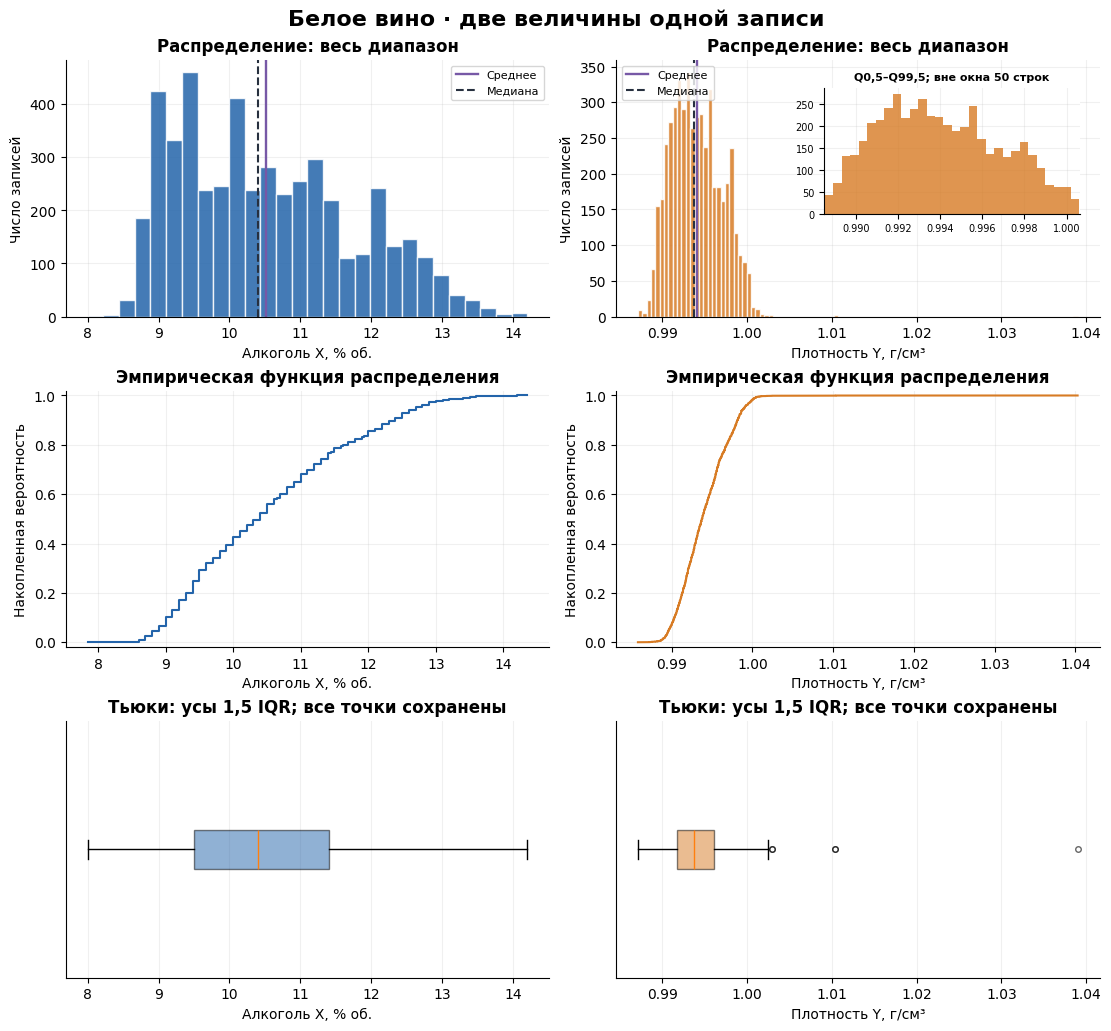

In [20]:
wine2_fig = wine2_figures.univariate(wine2_study["values"])
wine2_display(wine2_fig)
wine2_plt.close(wine2_fig)

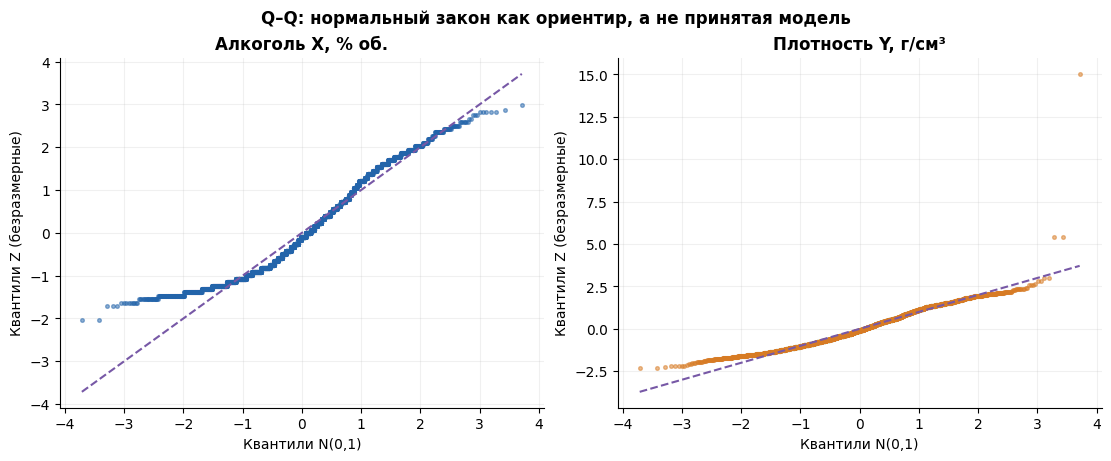

In [21]:
wine2_fig = wine2_figures.qq_plot(wine2_study["values"])
wine2_display(wine2_fig)
wine2_plt.close(wine2_fig)

In [22]:
wine2_display(wine2_Markdown(wine2_text.dependence_section(wine2_study)))

<a id="task2-dependence"></a>
### 8.5 Проверка зависимости

Алкоголь и плотность измерены у **одного случайно выбранного вина**.
Но это ещё не доказывает связь. При независимости должно выполняться

$$
\mathbb P(X\in C,Y\in D)=\mathbb P(X\in C)\mathbb P(Y\in D)
\quad\text{для всех борелевских }C,D.
$$

Чтобы показать зависимость, достаточно найти хотя бы один случай, когда равенства нет. Зададим рабочие
события $A=\{X>11\}$ и $B=\{Y<0.994\}$.
Пороги заданы в коде явно; это удобные исследовательские границы,
а не нормативы качества и не уровни значимости. Строгие неравенства важны:
записи ровно на границе относятся к дополнению события.

В файле $n_A=1561$, $n_B=2580$, $n_{A\cap B}=1480$, поэтому

$$
\mathbb P(A\cap B)=\frac{1480}{4898}=0.302164,\qquad
\mathbb P(A)\mathbb P(B)=\frac{1561\cdot2580}{4898^2}=0.167875.
$$

$$
\Delta=\mathbb P(A\cap B)-\mathbb P(A)\mathbb P(B)=0.134290\ne0.
$$

Проверка выполнена и **в целых числах**:
$n_{A\cap B}N-n_A n_B=3221660\ne0$.
Значит, разница не связана с округлением.
**X и Y зависимы в заданной конечной вероятностной модели.** Для этого вывода
не нужен p-value и не требуется независимость разных строк исходного CSV.

Это можно объяснить через условные вероятности:
$\mathbb P(B\mid A)=0.9481$,
а $\mathbb P(B\mid A^c)=0.3296$.
Среди записей с алкоголем выше 11% об. низкая плотность встречается примерно
в **94.8%**, среди остальных — в **33.0%**.
Это не означает, что каждое более крепкое вино имеет меньшую плотность.

Корреляции показывают ту же связь, что и диаграмма рассеяния:
Pearson $r=-0.780138$ (линейная),
Spearman $\rho_s=-0.821855$ (монотонная, средние ранги при совпадениях),
Kendall $\tau_b=-0.635104$ (с поправкой на совпадающие значения).
Ковариация $\operatorname{Cov}(X,Y)=-0.00287084$ п.п.·г/см³.
Нулевая корреляция вообще не гарантировала бы независимость; здесь наблюдается
сильная отрицательная связь и есть отдельное доказательство по событиям.


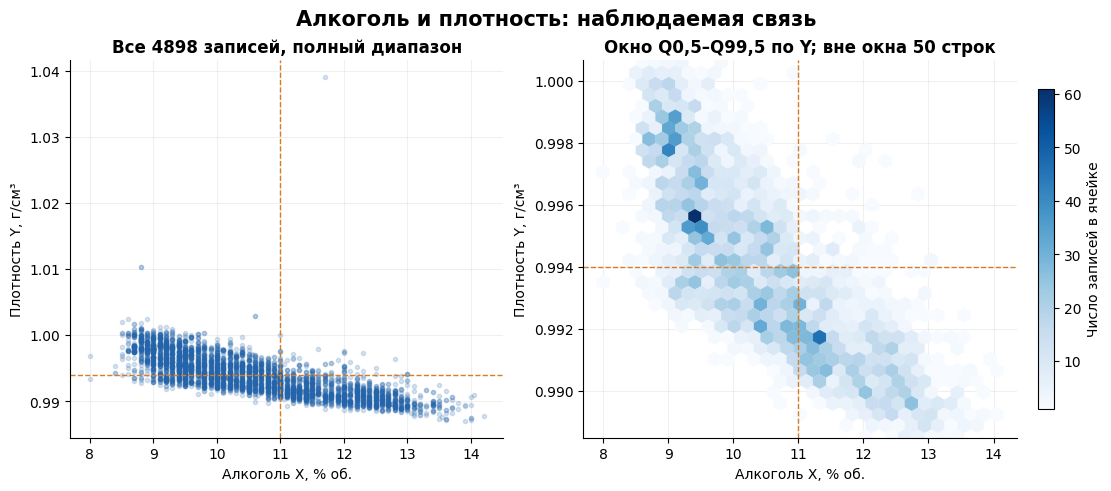

In [23]:
wine2_fig = wine2_figures.dependence(wine2_study["values"])
wine2_display(wine2_fig)
wine2_plt.close(wine2_fig)

In [24]:
wine2_display(wine2_Markdown(wine2_text.test_section(wine2_study)))

<a id="task2-test"></a>
### 8.6 Проверка гипотезы перестановками

Дополнительно проверим гипотезу о случайном сопоставлении значений:
$H_0^{perm}$ — при фиксированных наборах значений X и Y все сопоставления
между ними равновероятны; порядок пар не выделяется среди случайных сопоставлений.
Альтернатива — модуль ранговой корреляции необычно велик для такого сопоставления.
Статистика $T=|\rho_s|$, уровень $\alpha=0.05$.
Это один основной статистический тест; диагностические варианты ниже не используются
для выбора наименьшего p-value, поэтому семейство дополнительных тестов не создаётся.

Переставляем **только Y**, каждый раз оставляя X фиксированным.
Совпадающим значениям присваиваем средние ранги; перестановка рангов Y эквивалентна
перестановке исходного ряда. Расчёт повторён 9999 раз, seed=20261113.
Для двухстороннего теста используем заранее указанное определение через модуль:

$$
p_{MC}=\frac{1+\#\{b:|\rho_s^{(b)}|\ge|\rho_s^{obs}|\}}{B+1}.
$$

Наблюдаемое $\rho_s=-0.821855$; не менее экстремальных перестановок —
**0 из 9999**;
$p_{MC}=0.0001<0.05$.
Гипотеза случайного сопоставления отвергается. При нуле превышений результат
равен минимальному разрешению $1/(B+1)$, **а не нулю**; нельзя из этих
9999 перестановок заявить точное значение $p=10^{-20}$.

График показывает распределение перестановочных корреляций и наблюдаемую корреляцию.
Этот результат дополняет проверку вероятностей из раздела 5.
Для переноса p-value на неизвестную популяцию потребовалась бы обоснованная
модель отбора и обменяемость наблюдений при нуле. В файле нет данных о партиях,
поэтому такое обобщение не делается. Малый p-value также не доказывает причинность.


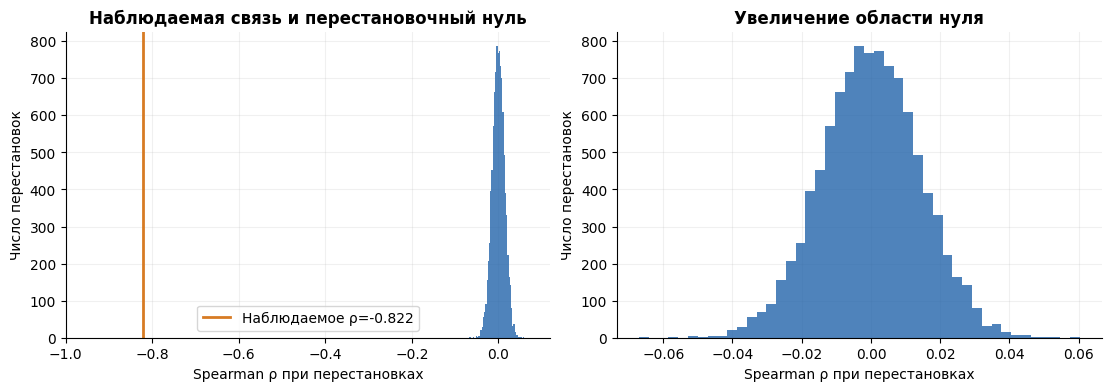

In [25]:
wine2_fig = wine2_figures.permutation_plot(wine2_study["permutation"])
wine2_display(wine2_fig)
wine2_plt.close(wine2_fig)

In [26]:
wine2_display(wine2_Markdown(wine2_text.robustness_section(wine2_study)))

<a id="task2-robustness"></a>
### 8.7 Проверка устойчивости вывода

В основном расчёте сохранены все строки, включая повторы. Для сравнения
также рассмотрены уникальные строки и данные без флагов Тьюки:

| Вариант | N | Pearson r | Spearman ρ | Kendall τ-b | Cov(X,Y) | Δ события | P(B∣A) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Все строки (основной закон) | 4898 | -0.780138 | -0.821855 | -0.635104 | -0.00287084 | 0.13429 | 0.94811 |
| Уникальные полные строки (иной закон) | 3961 | -0.760162 | -0.808451 | -0.620377 | -0.00268658 | 0.131829 | 0.953893 |
| Без флагов Тьюки по X/Y (иной закон) | 4893 | -0.805802 | -0.823047 | -0.636004 | -0.00287357 | 0.134363 | 0.948718 |

Во всех трёх вариантах направление и выраженность связи сохраняются.
Вариант уникальных строк меняет веса наблюдений; вариант без флагов Тьюки
меняет область исследования. Основным результатом остаётся расчёт на всех строках.
Результат не объясняется только одной экстремальной плотностью или наличием
полных повторов, хотя сами численные оценки от них зависят.

Более высокое содержание алкоголя связано с меньшей плотностью в этом файле.
Это согласуется с возможной физической интерпретацией состава раствора,
но здесь не проведён контролируемый эксперимент. Плотность также связана с
сахарами, кислотами, температурой и другими факторами. По двум столбцам нельзя отделить влияние алкоголя от остальных факторов
или точно предсказать плотность только по содержанию алкоголя. Измерительных протоколов и идентификаторов
партий нет; достоверность причинной модели не проверяется.


In [27]:
wine2_display(wine2_Markdown(wine2_text.generator_section(wine2_study)))

<a id="task2-generator"></a>
### 8.8 Как устроен генератор

Генератор использует частоты из таблицы. Сравним два способа: брать алкоголь
и плотность из одной строки или выбирать каждый признак отдельно.
**Основной способ — выбор готовой пары**, второй нужен для сравнения.

#### 8.8.1 Парный генератор

На каждом шаге независимо выбираем $I\sim\operatorname{Unif}\{1,\ldots,N\}$
с возвращением и возвращаем сразу $(X^*,Y^*)=(a_I,d_I)$.
Для любой пары $(x,y)$:

$$
\mathbb P(X^*=x,Y^*=y)=\sum_{i:(a_i,d_i)=(x,y)}\frac1N=p_{X,Y}(x,y).
$$

Таким образом, генератор воспроизводит **весь заданный совместный закон**,
в том числе повторы, маргинальные распределения, корреляции и вероятности событий.
Конкретная конечная серия совпадать с этими характеристиками точно не обязана.
Независимы разные сгенерированные **пары**; координаты внутри пары зависимы.

#### 8.8.2 Независимая генерация по обратной CDF

Для каждого столбца находим различные значения $z_1<\dots<z_K$,
частоты $c_j$, накопленные вероятности $C_j=\sum_{\ell\le j}c_\ell/N$,
$C_0=0$. Для $U\sim\operatorname{Unif}[0,1)$ выбираем $z_j$, если
$C_{j-1}\le U<C_j$. Длина интервала равна $c_j/N$, что доказывает правильность закона.
Интервалы заданы полуоткрытыми, так что даже U=0 и точные границы обрабатываются однозначно.

Если генерировать X и Y из **разных независимых U**, получим

$$
p_{X^*,Y^*}(x,y)=p_X(x)p_Y(y).
$$

Маргинальные гистограммы и CDF остаются верными, но исходная связь исчезает.
Это показывает, что похожих распределений каждого признака ещё недостаточно,
чтобы правильно описать пару. Независимый режим **не считается подходящей моделью наблюдаемой пары**.

#### 8.8.3 Как повторить генерацию

Используется явно заданный `numpy.random.Generator(numpy.random.PCG64(seed))`.
Одинаковые данные, режим, размер и seed дают одинаковую серию в зафиксированной среде.
Используется псевдослучайный генератор: при одинаковых настройках его результат
можно повторить. Это симуляция, а не физический источник случайности.
У каждой операции собственный объект Generator, seed протокола записаны явно.
Изменение интерактивного seed не меняет результаты исходного анализа.
Алгоритмы преобразования включены в начальную ячейку вычислительных файлов; при подготовке выполнены модульные тесты.


In [28]:
wine2_display(wine2_Markdown(wine2_text.interactive_section(wine2_study)))

<a id="task2-interactive"></a>
### 8.9 Интерактивный генератор

В marimo можно менять размер серии, seed и способ генерации.
Кнопка «Новая серия» создаёт другой набор чисел, а бегунки X и Y меняют пороги события.
Таблица и графики ниже показывают, как результат отличается от исходных данных.
В HTML сохранён один пример; бегунки работают в файле `task2_white_wine.py`, открытом через marimo.


m=10 000, seed=20261113, режим: paired


,Ряд,N,"Среднее X, % об.","Среднее Y, г/см³","σ X, п.п.","σ Y, г/см³",Pearson r,P(A∩B),P(B|A),Δ
0,Исходный закон,4898,10.514267,0.994027,1.230495,0.002991,-0.780138,0.302164,0.948110,0.134290
1,Генерация,10000,10.506220,0.994052,1.228717,0.003018,-0.771318,0.300800,0.959184,0.137289


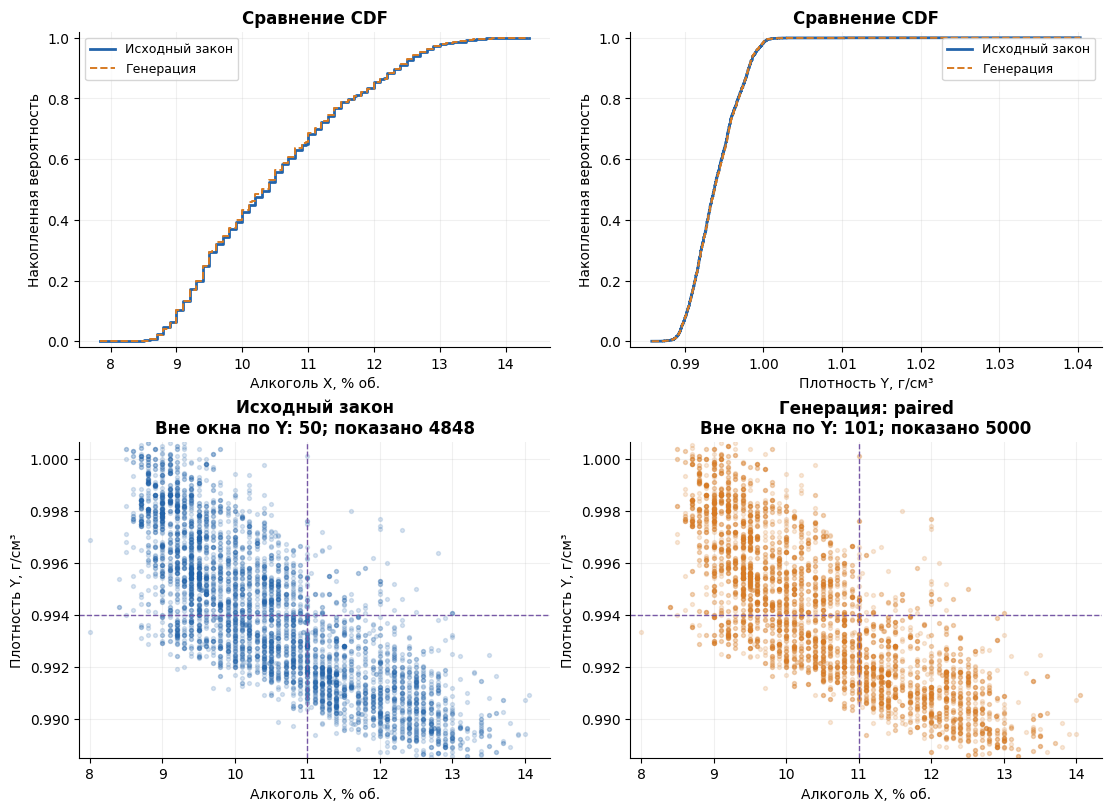

m=10 000, seed=20261113, режим: independent


,Ряд,N,"Среднее X, % об.","Среднее Y, г/см³","σ X, п.п.","σ Y, г/см³",Pearson r,P(A∩B),P(B|A),Δ
0,Исходный закон,4898,10.514267,0.994027,1.230495,0.002991,-0.780138,0.302164,0.948110,0.134290
1,Генерация,10000,10.517184,0.993979,1.229185,0.002954,-0.004531,0.170300,0.532021,-0.000793


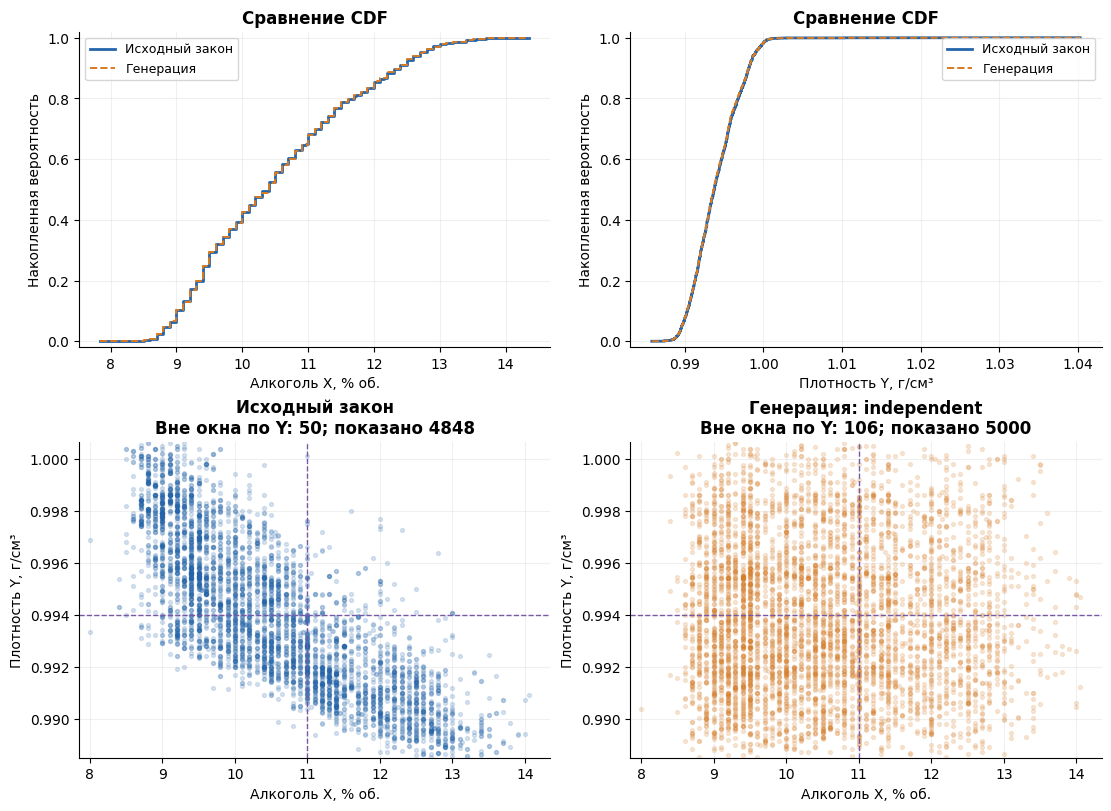

In [29]:
for wine2_mode in ["paired", "independent"]:
    wine2_generated = wine2_analysis.generate(wine2_study["values"], 10000, wine2_analysis.SEED, wine2_mode)
    print("m=10 000, seed=20261113, режим:", wine2_mode)
    wine2_display(wine2_analysis.simulation_metrics(wine2_study["values"], wine2_generated))
    wine2_fig = wine2_figures.simulation_plot(wine2_study["values"], wine2_generated, wine2_mode)
    wine2_display(wine2_fig)
    wine2_plt.close(wine2_fig)

In [30]:
wine2_display(wine2_Markdown(wine2_text.validation_section(wine2_study)))

<a id="task2-validation"></a>
### 8.10 Проверка генератора

#### 8.10.1 Сравнение с заданным законом

Для каждого режима сгенерировано $m=50\,000$ пар: seed=20261123 для парного,
seed=20261124 для независимого. Для всех проверок вместе задана вероятность
ложного сигнала $\alpha_{family}=0.01$ для **шести** сравнений:
четыре маргинальных CDF и по одному совместному событию для каждого режима.

Для CDF применяем неравенство Дворецкого–Кифера–Вольфовица (ДКВ),
для индикатора события — неравенство Хёффдинга:

$$
\mathbb P\!\left(\sup_t|F_m(t)-F(t)|>\varepsilon\right)\le 2e^{-2m\varepsilon^2},
\qquad
\mathbb P\!\left(|\widehat p_m-p|>\varepsilon\right)\le 2e^{-2m\varepsilon^2}.
$$

Чтобы ограничить вероятность хотя бы одного ложного сигнала, берём

$$
\varepsilon=\sqrt{\frac{\log(12/0.01)}{2m}}=0.008420.
$$

Целевая вероятность совместного события в парном режиме — $\mathbb P(A\cap B)$
из файла, в независимом — $\mathbb P(A)\mathbb P(B)$.
В этой серии выполнено **6 из 6** сравнений:

| Режим | Проверка | Ошибка | Граница | Пройдена |
| --- | --- | --- | --- | --- |
| paired | CDF: Алкоголь X, % об. | 0.00651605 | 0.00842026 | да |
| paired | CDF: Плотность Y, г/см³ | 0.00634733 | 0.00842026 | да |
| paired | Совместное событие A∩B | 0.00488415 | 0.00842026 | да |
| independent | CDF: Алкоголь X, % об. | 0.00218171 | 0.00842026 | да |
| independent | CDF: Плотность Y, г/см³ | 0.0022331 | 0.00842026 | да |
| independent | Совместное событие A∩B | 0.000445378 | 0.00842026 | да |

Границы сравнивают генерацию с **заданными** законами; независимый генератор
может успешно пройти свои проверки и всё равно плохо описывать наблюдаемую пару.
ДКВ здесь не является проверкой соответствия вин нормальному распределению.
Одного удачного запуска мало: важно также обоснование алгоритма и проверка кода.
Вероятностные границы предполагают идеализированные независимые генерации;
они не сертифицируют качество самого PCG64.

#### 8.10.2 Почему больший объём даёт меньшую ошибку

Для каждого $m\in\{50,200,1000,5000\}$ сформировано 200 независимых серий из
парного эмпирического закона. Рассчитана RMSE среднего относительно **известного**
среднего файла. В этой модели

$$
\operatorname{Var}(\bar V_m)=\frac{\sigma_V^2}m,\qquad
\frac{\operatorname{RMSE}(\bar V_m)}{\sigma_V}=\frac1{\sqrt m}.
$$

Конечные 200 повторов дают приближённые RMSE и не обязаны точно лежать на линии:

| m | Повторов | RMSE X / σX | RMSE Y / σY | Теория 1/√m |
| --- | --- | --- | --- | --- |
| 50 | 200 | 0.146223 | 0.144541 | 0.141421 |
| 200 | 200 | 0.0745068 | 0.0722778 | 0.0707107 |
| 1000 | 200 | 0.0320943 | 0.0332907 | 0.0316228 |
| 5000 | 200 | 0.0145863 | 0.0141827 | 0.0141421 |

Эксперимент иллюстрирует сходимость среднего генерации, а формула даёт теоретическое
обоснование. Новых измерений здесь нет: увеличивается только число сгенерированных значений.
При подготовке прошли 25 модульных тестов, проверка структуры marimo и полное выполнение ноутбука. Компактные вычислительные файлы дополнительно выполнены отдельно.


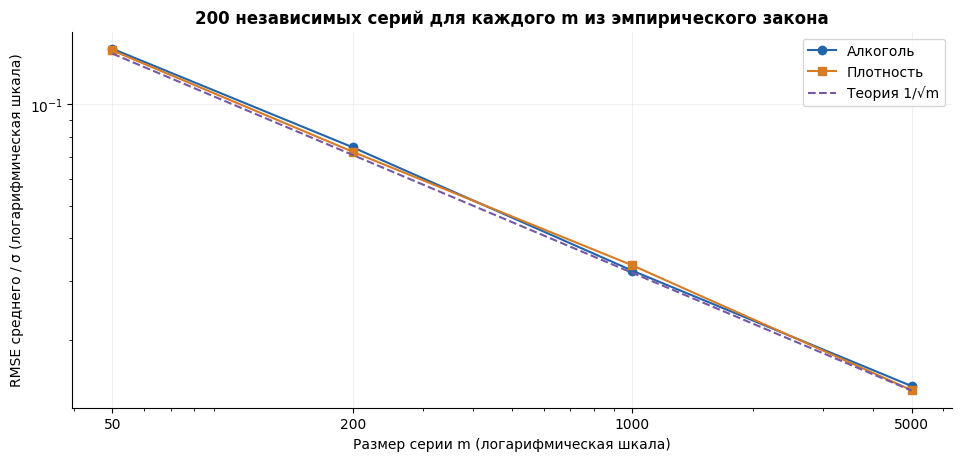

In [31]:
wine2_fig = wine2_figures.convergence_plot(wine2_study["convergence"])
wine2_display(wine2_fig)
wine2_plt.close(wine2_fig)

In [32]:
wine2_display(wine2_Markdown(wine2_text.conclusions_section(wine2_study)))

<a id="task2-conclusions"></a>
### 8.11 Выводы

В этой работе были рассмотрены содержание алкоголя и плотность белого вина.
Обе характеристики являются случайными величинами в нашем эксперименте:
мы случайно выбираем строку и заранее не знаем, какие значения получим.

Среднее и медиана алкоголя получились около 10,4–10,5% об., а плотности —
около 0,994 г/см³. У плотности есть несколько высоких значений, которые заметно
влияют на эксцесс. Они сохранены в основном расчёте, потому что по самому файлу
нельзя уверенно сказать, что это ошибки.

Алкоголь и плотность оказались зависимыми: при большем содержании алкоголя
плотность обычно ниже. Pearson равен **-0.780**, а Spearman —
**-0.822**. Проверка событий дала тот же вывод:
$\mathbb P(A\cap B)=0.3022$, тогда как
$\mathbb P(A)\mathbb P(B)=0.1679$.
Эти вероятности не равны, поэтому при случайном выборе строки из этого файла
гипотеза независимости неверна. Перестановочный тест дал
$p_{MC}=0.0001$ при уровне 0,05:
гипотеза случайного сопоставления столбцов тоже отвергается.
После проверки повторов и крайних значений направление связи сохранилось.

Для генерации двух величин вместе лучше брать готовую пару из одной случайной
строки. Так сохраняются и распределения отдельных признаков, и связь между ними.
При независимом выборе каждого признака гистограммы остаются похожими, но связь
теряется. Для выбранного совместного события это даёт разницу примерно
**13.43 процентного пункта**. Значит, одних похожих гистограмм недостаточно,
чтобы считать генератор подходящим для пары величин.

При увеличении размера серии ошибка среднего уменьшается примерно как
$1/\sqrt m$. Но дополнительные сгенерированные числа не заменяют новые
измерения. Все выводы относятся к этому файлу: они не доказывают причинную связь
и не означают, что у любых белых вин будут те же характеристики.


In [33]:
wine2_display(wine2_Markdown(wine2_text.criteria_section(wine2_study)))

<a id="task2-criteria"></a>
### 8.12 Выполненные критерии

| Критерий из задания 2 | Где выполнен | Проверяемый результат |
| --- | --- | --- |
| Отдельный датасет и две величины | §8.1–8.2 | Датасет белого вина, alcohol и density, источник и единицы |
| Обосновать случайные величины | §8.2 | Вероятностное пространство, измеримость, невырожденность |
| Установить независимость/зависимость | §8.5–8.7 | Точное нарушение факторизации, три корреляции, перестановочный тест и чувствительность |
| EDA | §8.3–8.4 | Проверка данных, частоты/CDF, квантили, моменты 1–4, разброс, форма, крайние записи |
| Интерактивный генератор | §8.8–8.10 | Два алгоритма, размер, seed, новые серии, режим, пороги, CSV, сравнение распределений |
| Использование marimo | task2_white_wine.py | Реактивные вычисления, приложение, скрытый код |
| Выводы и проверенные гипотезы | §8.11 | Интерпретация эффектов и гипотез, ограничения |


#### 8.12.1 Источники

1. Cortez et al. **Wine Quality** (2009). [UCI и лицензия](https://archive.ics.uci.edu/dataset/186/wine+quality),
   [авторское описание](https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality.names).
2. A. Kumar, J. Srivastava. **Classification-based Data Mining Approach for Quality
   Control in Wine Production** (2012).
   [Описание единиц](https://scialert.net/fulltext/amp.php?doi=jas.2012.598.601).
   Число строк взято из оригинального CSV, а не из опечатки этой статьи.
3. NumPy. [PCG64](https://numpy.org/doc/stable/reference/random/bit_generators/pcg64.html),
   [quantile](https://numpy.org/doc/stable/reference/generated/numpy.quantile.html).
4. SciPy. [Spearman и ties](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html),
   [схемы перестановок](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html).
   В работе используется собственная двухсторонняя статистика через модуль,
   а не неявное заимствование соглашения SciPy о двухстороннем p-value.
5. Massart P. **The Tight Constant in the Dvoretzky–Kiefer–Wolfowitz Inequality** (1990).
   [DOI: 10.1214/aop/1176990746](https://doi.org/10.1214/aop/1176990746).
6. Hoeffding W. **Probability Inequalities for Sums of Bounded Random Variables** (1963).
   [DOI: 10.1080/01621459.1963.10500830](https://doi.org/10.1080/01621459.1963.10500830).
7. marimo. [Запуск приложения](https://docs.marimo.io/guides/apps/),
   [статический экспорт](https://docs.marimo.io/guides/exporting/static_html/).

[К началу](#task2-start)


### 8.13 Как открыть интерактивную версию

Для просмотра интерактивных графиков откройте `[task2_white_wine.py](task2_white_wine.py)` через marimo:

```bash
python -m pip install marimo==0.25.2 numpy==2.5.4 pandas==3.1.1 scipy==1.18.1 matplotlib==3.11.2
python -m marimo run --no-sandbox [task2_white_wine.py](task2_white_wine.py)
```

Нужен Python 3.12 или новее.

[↑ К общему содержанию](#start) · [К началу раздела 8](#task2-start)
